<a href="https://colab.research.google.com/github/kartik-kumarr/LCSA-tracker-analyis/blob/main/LCSA_tracker_supplementary.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LCSA Tracker — survey analysis (supplementary material)

Analysis of the survey evaluating the Life Cycle Sustainability Assessment (LCSA)
Tracker prototypes (Qualtrics export; respondents from India, Australia and Vietnam).

**Reproducing the results.** Place the Qualtrics CSV next to this notebook (or set
`CONFIG["data_file"]`) and run all cells from top to bottom. Every function and
variable is defined before it is used. Sentiment and feature-coding results are
cached in `cache/`; delete that folder to recompute them.

| Part | Contents |
|---|---|
| 0 | Setup: imports, configuration, shared definitions |
| 1 | Loading and cleaning |
| 2 | Sample description and missing data |
| 3 | Open-text answers → sentiment scores |
| 4 | Missing-data treatment |
| 5 | Inferential statistics |
| 6 | Dimension reduction (PCA / factor analysis) |
| 7 | Qualitative analysis of open-ended answers |
| 9 | Tracker, Mapping and Geolocation features |
| 8 | Session information (software versions) |


## Part 0 — Setup

### 0.1 Imports

Optional packages set a `HAS_*` flag instead of stopping the run, so cells that
need them are skipped if they are not installed.


In [2]:
import json
import platform
import re
import sys
import warnings
from collections import Counter
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.decomposition import PCA, KernelPCA
from sklearn.preprocessing import StandardScaler


def _try(name, importer):
    try:
        return True, importer()
    except Exception:
        print(f"  [optional] {name} unavailable — dependent cells will be skipped.")
        return False, None


print("Optional dependencies:")
HAS_POSTHOCS, sp = _try("scikit-posthocs", lambda: __import__("scikit_posthocs"))
HAS_FA, _fa = _try("factor_analyzer", lambda: __import__("factor_analyzer"))
HAS_PLOTLY, _pl = _try("plotly", lambda: __import__("plotly.graph_objects",
                                                    fromlist=["go"]))
HAS_TRANSFORMERS, _tf = _try("transformers", lambda: __import__("transformers"))
HAS_SPACY, _sy = _try("spacy", lambda: __import__("spacy"))
HAS_WORDCLOUD, _wc = _try("wordcloud", lambda: __import__("wordcloud"))

if HAS_FA:
    # factor_analyzer still passes `force_all_finite` to scikit-learn's
    # check_array, which newer scikit-learn renamed to `ensure_all_finite`.
    # Translate the argument so factor analysis works with any version.
    import inspect
    import factor_analyzer.factor_analyzer as _fa_mod
    from sklearn.utils import check_array as _check_array
    if "force_all_finite" not in inspect.signature(_check_array).parameters:
        def _checkArrayCompat(*args, force_all_finite=None, **kwargs):
            if force_all_finite is not None:
                kwargs.setdefault("ensure_all_finite", force_all_finite)
            return _check_array(*args, **kwargs)
        _fa_mod.check_array = _checkArrayCompat
    from factor_analyzer import FactorAnalyzer
    from factor_analyzer.factor_analyzer import (
        calculate_bartlett_sphericity, calculate_kmo)
if HAS_PLOTLY:
    import plotly.graph_objects as go

warnings.filterwarnings("ignore", category=FutureWarning)

Optional dependencies:
  [optional] scikit-posthocs unavailable — dependent cells will be skipped.
  [optional] factor_analyzer unavailable — dependent cells will be skipped.


### 0.2 Configuration

All paths, thresholds and constants are set here. `random_seed` is used for every
random step (imputation, permutation tests, plot jitter), so results are identical
between runs.


In [3]:
CONFIG = {
    # Inputs
    "data_file": "LCSA Tracker Survey_June 22, 2026_22.30.csv",
    "qual_themes_file": "qual_themes.csv",
    # Outputs
    "fig_dir": "figures",
    "table_dir": "tables",
    "cache_dir": "cache",
    "fig_dpi": 1000,               # also applies to raster parts of SVGs
    "save_figures": True,
    "fig_formats": ("svg", "png"), # each figure is saved in both formats
    "png_dpi": 600,                # resolution of the PNG copies
    # Reproducibility
    "random_seed": 42,
    # Cleaning
    "last_col": "QID31_4",        # rows blank in every column AFTER this are dropped
    "birth_year_threshold": 100,
    # Analysis
    "sentiment_model": "cardiffnlp/twitter-roberta-base-sentiment-latest",
    # Ensemble for robustness (Part 3): scores are averaged across these models.
    # Two are multilingual, which matters for answers written by participants in
    # India and Vietnam who may mix languages or use non-native phrasing.
    "sentiment_models": [
        "cardiffnlp/twitter-roberta-base-sentiment-latest",       # neg/neu/pos
        "nlptown/bert-base-multilingual-uncased-sentiment",       # 1-5 stars
        "lxyuan/distilbert-base-multilingual-cased-sentiments-student",  # neg/neu/pos
    ],
    "sentiment_scale": (0, 100),  # scores are already 0-100; bounds the imputer
    "scoring_method": "expected_score",     # or "label_confidence" — see Part 3
    "sentiment_batch_size": 32,
    # Zero-shot model for feature coding (7.1c). Alternatives that also work:
    # "MoritzLaurer/deberta-v3-large-zeroshot-v2.0" (more accurate, much slower on CPU)
    # "MoritzLaurer/deberta-v3-base-zeroshot-v2.0"  (faster, slightly less accurate)
    "feature_model": "facebook/bart-large-mnli",
    "mice_max_iter": 10,
    "mice_m": 20,                 # number of multiply-imputed datasets
    "mice_sample_posterior": True,  # draws, not conditional means (required for MI)
    "n_permutations": 10000,      # Monte Carlo chi-square when expected counts < 5
    "alpha": 0.05,
    "correction": "holm",
    "min_group_n": 5,             # groups smaller than this are excluded from tests
    "threshold": 0.40,            # |loading| to call an item a strong contributor
    "n_factors": 2,
    "gamma": 0.10,                # kernel PCA
    "use_ollama": False,
}

np.random.seed(CONFIG["random_seed"])
rng = np.random.default_rng(CONFIG["random_seed"])

for _d in (CONFIG["fig_dir"], CONFIG["table_dir"], CONFIG["cache_dir"]):
    Path(_d).mkdir(exist_ok=True)

print(f"Seed {CONFIG['random_seed']} | outputs -> {CONFIG['fig_dir']}/, "
      f"{CONFIG['table_dir']}/, {CONFIG['cache_dir']}/")

Seed 42 | outputs -> figures/, tables/, cache/


### 0.3 Shared definitions

The analysis items (`rank_cols`), their labels (`question_labels`) and the a priori
constructs (`constructs`) are defined once here and used throughout.


In [4]:
# Analysis items, in reporting order
rank_cols = ['QID21', 'QID12', 'QID29', 'QID31_1', 'QID31_2', 'QID31_3',
             'QID31_4', 'QID13_4', 'QID13_5', 'QID13_6', 'QID24', 'QID28', 'QID22']

# Alias used by the PCA / factor-analysis cells.
rank_cols_sentiment = list(rank_cols)

# Labels used in tables and figures, keyed on column names
# The survey sheet numbers the QID13 sub-questions _1/_2/_3; this export names
# them _4/_5/_6 (combined mapping / tracker / geo-location). Both are mapped.
question_labels = {
    # Demographic / classifying
    "QID8":  "Expertise",
    "QID10": "Gender",
    "QID6":  "Experience with LCSA tracker",
    "QID7":  "Age",
    # Analysis items
    "QID19":   "Intuitiveness",
    "QID21":   "Interactiveness",
    "QID12":   "User-Experience",
    "QID13_4": "Mapping Likeability",
    "QID13_5": "Tracker Likeability",
    "QID13_6": "Geolocation Likeability",
    "QID13_1": "Mapping Likeability",
    "QID13_2": "Tracker Likeability",
    "QID13_3": "Geolocation Likeability",
    "QID16":   "Features Relationship",
    "QID24":   "Overall Likeability",
    "QID29":   "Prototype Novelty",
    "QID22":   "Most Intuitive Interaction",
    "QID28":   "Increased Functionality",
    "QID31_1": "Sustainability Importance",
    "QID31_2": "Environmental Importance",
    "QID31_3": "Social Importance",
    "QID31_4": "Economic Importance",
    "QID17":   "Data Representation",
    "QID18":   "Preferred Data Representation",
    "QID20":   "Content Improvement",
    "QID23":   "Interaction Improvement",
    "QID14":   "Prototype Improvement",
    "QID15":   "Utility",
    "QID25":   "Visualisation Preference",
    "QID26":   "Overall Improvement",
    "QID27":   "Other Comments",
    # Derived
    "Age": "Age (years)", "Region": "Region", "Gender": "Gender",
    "Occupation": "Expertise", "Seen": "Seen before", "AgeRange": "Age Range",
}

# A priori multi-item constructs
# Grouped from the questionnaire design, not from observed loadings (deriving
# groups from the data then testing them on the same data is circular). Part 6
# checks these empirically and reports whether they hold.
constructs = {
    'User-experience':       ['QID12', 'QID28'],
    'Likeability':           ['QID13_4', 'QID13_5'],   # mapping, tracker
    # Geolocation (QID13_6) is analysed as its own item (rank_cols), not in a construct.
    'Interaction':           ['QID21', 'QID22'],
    'Usefulness':            ['QID24', 'QID29'],
    'Sustainability-values': ['QID31_1', 'QID31_2', 'QID31_3', 'QID31_4'],
}

# Open-text question set (Part 7)
Questions = ['QID31_1', 'QID31_2', 'QID31_3', 'QID31_4', 'QID17', 'QID18',
             'QID19', 'QID20', 'QID21', 'QID22', 'QID23', 'QID12', 'QID13_4',
             'QID13_5', 'QID13_6', 'QID14', 'QID15', 'QID16', 'QID24', 'QID25',
             'QID26', 'QID27', 'QID28', 'QID29']

questions_dict = {
    "QID17": "11. What information/interactions would you like to see in a Life Cycle Sustainability Tracker?",
    "QID18": "12. How would you like to see data represented in the LCSA tracker prototype?",
    "QID19": "13. How useful was the content in understanding the Life Cycle Sustainability?",
    "QID20": "14. How could the content be improved?",
    "QID21": "15. How did you find the interactions and functionality?",
    "QID22": "16. What interaction is most intuitive?",
    "QID23": "17. How would you improve the interaction?",
    "QID12": "18. How was your experience using the LCSA tracker?",
    "QID13_4": "19. What did you like or dislike about? - Combined mapping",
    "QID13_5": "19. What did you like or dislike about? - Tracker",
    "QID13_6": "19. What did you like or dislike about? - Geo-location",
    "QID14": "20. How would you improve the LCSA tracker?",
    "QID15": "21. In what situations would you use the prototypes?",
    "QID16": "22. How useful were the prototypes in helping you understand the relationship between LCSA Tracker, mapping and their metrics?",
    "QID24": "23. What did you like or dislike about the LCSA tracker overall?",
    "QID25": "24. Which version of the prototypes did you prefer overall?",
    "QID26": "25. How would you improve it overall?",
    "QID27": "26. Do you have any other comments you would like to make?",
    "QID28": "27. If you were to add new components to the prototypes, what would they be?",
    "QID29": "28. Do you think the available visualisation approaches bring something new to the table?",
}

# Grouping variables used throughout Part 5
grouping_vars = ['Region', 'Occupation', 'Gender', 'Seen', 'AgeRange']

# Category orders (every table and figure uses these)
region_order   = ['Australia', 'India', 'Vietnam']
gender_order   = ['Male', 'Female', 'Prefer not to say']
expert_order   = ['Expert', 'Non-expert']
seen_order     = ['NO', 'YES']
duration_order = ['< 2 minutes', '2 mins – 5 mins', '> 5 mins']

# Age bands (10-year).
age_order = ["5-14", "15-24", "25-34", "35-44", "45-54", "55-64", "65-74",
             "75-84", "85-94", "95-104", "105 and over", "Does not mention"]

# Recruitment windows
# Region is inferred from response date because the survey never asked it. That is
# a substantive assumption — see the supplement.
regions = {
    'India':     [('2024-08-22', '2024-09-01')],
    'Australia': [('2024-09-02', '2024-12-10'), ('2025-08-17', '2025-10-28')],
    'Vietnam':   [('2024-12-11', '2025-08-16')],
}

# Occupation mapping (lower-cased for matching)
occupation_mapping = {
    "Expert": [
        "professor", "academic", "assistant professor (civil engineer)", "prof",
        "lecturer", "postdoc", "researcher", "engineer", "architect",
        "sustainability consultant", "consultant", "chemistry",
        "civil engineer", "scientist",
    ],
    "Non-expert": [
        "student", "students", "ph.d student", "phd student", "i am a student",
        "undergraduated", "fresher", "undergraduate student",
        "computer science student", "12 pass", "school", "pupil", "freshman",
    ],
}

# Colours
region_colors = {'India': '#DD8452', 'Vietnam': '#55A868', 'Australia': '#4C72B0'}
group_palette = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']

print(f"{len(rank_cols)} analysis items | {len(constructs)} constructs | "
      f"{len(question_labels)} labels")

13 analysis items | 5 constructs | 37 labels


### 0.4 Plot style and helper functions

The plot style is set once, so every figure looks the same regardless of the order
in which cells are run.


In [5]:
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.figsize": (8, 5), "font.family": "DejaVu Sans", "font.size": 10,
    "axes.linewidth": 0.8, "axes.edgecolor": "#333333",
    "savefig.bbox": "tight", "figure.dpi": 100,
    "svg.fonttype": "none",      # keep text as editable text in the SVG files
})


# save the current figure into fig_dir as SVG and PNG
def saveFig(name, formats=None):
    if not CONFIG["save_figures"]:
        return
    for fmt in formats or CONFIG.get("fig_formats", ("svg", "png")):
        dpi = CONFIG.get("png_dpi", 600) if fmt == "png" else CONFIG["fig_dpi"]
        plt.savefig(Path(CONFIG["fig_dir"]) / f"{name}.{fmt}",
                    dpi=dpi, format=fmt, bbox_inches="tight")


# persist a results table so figures and manuscript numbers stay in sync
def saveTable(frame, name):
    path = Path(CONFIG["table_dir"]) / f"{name}.csv"
    frame.to_csv(path, index=False)
    print(f"  saved -> {path}")
    return frame


# display label for a column; falls back to the column name
def labelOf(col):
    return question_labels.get(col, col)


# categories present in `series`, in canonical `order`, extras appended
def orderedCategories(series, order):
    present = set(series.dropna().unique())
    return [c for c in order if c in present] + \
           sorted([c for c in present if c not in order], key=str)


# the canonical category order for a grouping variable
def orderFor(gvar):
    return {'Region': region_order, 'Gender': gender_order,
            'Occupation': expert_order, 'Seen': seen_order,
            'AgeRange': age_order}.get(gvar, [])


def pct(n, total):
    return 0.0 if total == 0 else round(100 * n / total, 1)


# Levels that record a non-answer rather than a group. They are shown in the
# descriptive tables but never enter a test as if they were a population
# (e.g. "Does not mention" is not an age band).
NON_RESPONSE_LEVELS = {"Does not mention", "Not reported", "Prefer not to say",
                       "Others", "Other"}


# chi-square test of independence on a contingency table
def chi2Independence(table, n_perm=None, seed=None):
    table = np.asarray(table)
    chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
    if (expected < 5).mean() <= 0.20:
        return chi2, p, dof, expected, "asymptotic"
    n_perm = n_perm or CONFIG["n_permutations"]
    gen = np.random.default_rng(CONFIG["random_seed"] if seed is None else seed)
    r_idx = np.repeat(np.arange(table.shape[0]), table.sum(axis=1))
    c_idx = np.repeat(np.arange(table.shape[1]), table.sum(axis=0))
    exceed = 0
    for _ in range(n_perm):
        perm = np.zeros_like(table)
        np.add.at(perm, (r_idx, gen.permutation(c_idx)), 1)
        exceed += stats.chi2_contingency(perm, correction=False)[0] >= chi2 - 1e-12
    return chi2, (exceed + 1) / (n_perm + 1), dof, expected, "Monte Carlo"


print("Style and helpers ready.")

Style and helpers ready.


## Part 1 — Loading and cleaning

### 1.1 Reading the export

The Qualtrics export has two extra header rows (question text and import IDs).
We remove both before any analysis.


In [6]:
# read the Qualtrics export, skipping its two metadata header rows
def loadRaw(path=None):
    path = Path(path or CONFIG["data_file"])
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path!s}.\nSet CONFIG['data_file'] to the export "
            f"path. CSVs here: {sorted(p.name for p in Path('.').glob('*.csv'))}")
    frame = pd.read_csv(path, header=0, skiprows=[1, 2], dtype=str)
    frame.columns = [c.strip() for c in frame.columns]
    return frame


df_raw = loadRaw()
print(f"Raw export: {df_raw.shape[0]} responses x {df_raw.shape[1]} columns")
assert not df_raw["StartDate"].astype(str).str.contains("ImportId").any(), \
    "Metadata rows still present — check skiprows."
df_raw.head(3)

Raw export: 282 responses x 47 columns


,StartDate,EndDate,Status,IPAddress,Progress,Duration (in seconds),Finished,RecordedDate,ResponseId,RecipientLastName,...,QID13_6,QID14,QID15,QID16,QID24,QID25,QID26,QID27,QID28,QID29
0,2024-08-23 00:07:54,2024-08-23 00:11:38,IP Address,106.198.32.218,100,223,True,2024-08-23 00:11:39,R_4XoYVLplPZVDEMo,NaN,...,NaN,More location based data,NaN,Very useful,Visual appearance,NaN,NaN,NaN,Adding sounds will be better,Yes
1,2024-08-23 00:04:04,2024-08-23 00:16:01,IP Address,106.198.47.136,100,717,True,2024-08-23 00:16:02,R_4GdCqsp3hkeVGvf,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN
2,2024-08-23 00:09:01,2024-08-23 00:26:07,IP Address,103.158.43.22,100,1026,True,2024-08-23 00:26:08,R_41hGqWokjbb38ZU,NaN,...,NaN,Its better if we can give breif explanation ab...,I am not aware as of now.,Pretty useful,NaN,NaN,Brief information on what exactly is the purpo...,NaN,NaN,NaN


### 1.2 Cleaning

All cleaning is done in one function that returns a new data frame: we remove
respondents who did not start the survey, parse dates, and derive `Region`,
`Duration Category`, `Age`/`AgeRange`, `Occupation` (expert / non-expert),
`Gender` and `Seen` (prior exposure).


In [7]:
# map a response date to a recruitment wave
def assignRegion(date, regions=regions):
    if pd.isna(date):
        return 'Other'
    date = pd.Timestamp(date)
    for region, date_ranges in regions.items():
        for start, end in date_ranges:
            if pd.Timestamp(start) <= date <= pd.Timestamp(end):
                return region
    return 'Other'


def categorizeDuration(seconds):
    if pd.isna(seconds):
        return 'Incomplete'
    minutes = seconds / 60
    if minutes < 2:
        return '< 2 minutes'
    elif minutes <= 5:
        return '2 mins – 5 mins'
    return '> 5 mins'


# expert / Non-expert / Others from free-text occupation
def mapOccupation(value, mapping=occupation_mapping):
    if not isinstance(value, str) or not value.strip():
        return "Others"
    text = value.lower().strip()
    for group, terms in mapping.items():       # exact match wins
        if text in terms:
            return group
    # 'student' is checked before 'engineer' so that "engineering student"
    # is classified as Non-expert.
    for group in ("Non-expert", "Expert"):
        for term in mapping[group]:
            if term in text:
                return group
    return "Others"


# 10-year age bands
def mapAgeToRange(age):
    if pd.isna(age):
        return "Does not mention"
    bands = [(5, 14, "5-14"), (15, 24, "15-24"), (25, 34, "25-34"),
             (35, 44, "35-44"), (45, 54, "45-54"), (55, 64, "55-64"),
             (65, 74, "65-74"), (75, 84, "75-84"), (85, 94, "85-94"),
             (95, 104, "95-104")]
    for lo, hi, label in bands:
        if lo <= age <= hi:
            return label
    return "105 and over" if age >= 105 else "Does not mention"


# raw Qualtrics frame -> analysis-ready `df`. Pure: no in-place mutation
def clean(raw):
    out = raw.copy()
    audit = [("Raw responses in export", len(out))]

    # 1. Drop responses blank in every column after the anchor item.
    last_col = CONFIG["last_col"]
    if last_col not in out.columns:
        raise KeyError(f"{last_col!r} not in the export.")
    col_after = out.columns[out.columns.get_loc(last_col) + 1:]
    if len(col_after):
        mask = out[col_after].isna().all(axis=1)
        out = out.loc[~mask].copy()
        audit.append((f"After dropping rows blank past {last_col}", len(out)))

    # 2. Dates.
    date_txt = out['StartDate'].astype(str).str.extract(r"(\d{4}-\d{2}-\d{2})")[0]
    out['StartDate'] = pd.to_datetime(date_txt, errors='coerce')
    out = out.loc[out['StartDate'].notna()].copy()
    audit.append(("After dropping unparseable dates", len(out)))

    # 3. Region (+ `country` alias).
    out['Region'] = out['StartDate'].apply(assignRegion)
    out['country'] = out['Region']

    # 4. Duration.
    out['Duration (in seconds)'] = pd.to_numeric(
        out['Duration (in seconds)'], errors='coerce')
    out['Duration Category'] = out['Duration (in seconds)'].apply(categorizeDuration)

    # 5. Age — values above the threshold are read as birth years and converted
    #    with the year the response was given (responses span 2024-2025), not a
    #    fixed calendar year.
    age = pd.to_numeric(out.get('QID7'), errors='coerce')
    age = age.where(~(age > CONFIG["birth_year_threshold"]),
                    out['StartDate'].dt.year - age)
    out['Age'] = age
    out['AgeRange'] = out['Age'].apply(mapAgeToRange)

    # 6. Occupation.
    out['Occupation'] = out.get('QID8',
        pd.Series(index=out.index, dtype=object)).apply(mapOccupation)

    # 7. Gender and prior exposure.
    out['Gender'] = out.get('QID10').astype(str).str.strip().replace(
        {'nan': 'Not reported', '': 'Not reported'})
    out['Seen'] = out.get('QID6').astype(str).str.strip().str.upper().replace(
        {'NAN': 'Not reported', '': 'Not reported'})

    # Analysis items -> string, blanks unified to NaN.
    for c in rank_cols:
        if c in out.columns:
            s = out[c].astype(str).str.strip()
            out[c] = s.replace({'': np.nan, 'nan': np.nan, 'None': np.nan})

    out = out.reset_index(drop=True)
    audit.append(("Analysis sample", len(out)))
    return out, pd.DataFrame(audit, columns=["Step", "n"])


df, provenance = clean(df_raw)

print("Response funnel")
print(provenance.to_string(index=False))
print(f"\ndf: {df.shape[0]} responses x {df.shape[1]} columns")

# Re-running clean() must be a no-op — this is what makes "Run All" safe.
_again, _ = clean(df_raw)
assert _again.shape == df.shape, "clean() is not idempotent"
del _again
saveTable(provenance, "table_00_response_funnel")

Response funnel
                                  Step   n
               Raw responses in export 282
After dropping rows blank past QID31_4 212
      After dropping unparseable dates 212
                       Analysis sample 212

df: 212 responses x 55 columns
  saved -> tables/table_00_response_funnel.csv


,Step,n
0,Raw responses in export,282
1,After dropping rows blank past QID31_4,212
2,After dropping unparseable dates,212
3,Analysis sample,212


In [8]:
# Integrity checks — fail loudly rather than letting bad data reach the results.
assert df['StartDate'].notna().all(), "unparsed dates survived cleaning"
assert not df.columns.duplicated().any(), "duplicate column names"
missing_items = [c for c in rank_cols if c not in df.columns]
assert not missing_items, f"analysis items absent from the export: {missing_items}"

print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Region 'Other' (outside every window): {(df['Region'] == 'Other').sum()}")
print("\nRegion counts:")
print(df['Region'].value_counts().reindex(
    orderedCategories(df['Region'], region_order)).to_string())

emptyCols = df.isnull().sum()
print(f"\nColumns entirely empty: "
      f"{[c for c in df.columns if emptyCols[c] == len(df)]}")

Duplicate rows: 0
Region 'Other' (outside every window): 0

Region counts:
Region
Australia     44
India        133
Vietnam       35

Columns entirely empty: ['RecipientLastName', 'RecipientFirstName', 'RecipientEmail', 'ExternalReference']


## Part 2 — Sample description and missing data

We describe who responded and what is missing before running any test. The
grouping variables used in Part 5 are created and checked here, and group sizes
decide which tests are appropriate.

### 2.1 Engagement (completion time)


In [9]:
# counts and percentages for one categorical variable, in a fixed order
def frequencyTable(series, order=None, label="Category", dropna=False):
    counts = series.value_counts(dropna=dropna)
    if order is not None:
        counts = counts.reindex(orderedCategories(series, order)).fillna(0).astype(int)
    total = int(counts.sum())
    return pd.DataFrame({
        label: counts.index.astype(str),
        "n": counts.values.astype(int),
        "%": [pct(v, total) for v in counts.values],
    }).reset_index(drop=True)


engagement = frequencyTable(df["Duration Category"], duration_order, "Completion time")
print("Completion time, overall")
print(engagement.to_string(index=False))

dur = df["Duration (in seconds)"].dropna() / 60
print(f"\nMinutes: median {dur.median():.1f}, IQR "
      f"{dur.quantile(.25):.1f}–{dur.quantile(.75):.1f}, max {dur.max():.1f}")
saveTable(engagement, "table_01_engagement_overall")

Completion time, overall
Completion time   n    %
    < 2 minutes   4  1.9
2 mins – 5 mins  41 19.3
       > 5 mins 167 78.8

Minutes: median 6.9, IQR 5.4–10.4, max 50.7
  saved -> tables/table_01_engagement_overall.csv


,Completion time,n,%
0,< 2 minutes,4,1.9
1,2 mins – 5 mins,41,19.3
2,> 5 mins,167,78.8


Completion time by region, as row percentages so that regions of different size
can be compared.


In [10]:
# counts and row-wise percentages combined as 'n (x%)' in one table
def crosstabWithPct(frame, row, col, row_order=None, col_order=None):
    r_order = orderedCategories(frame[row], row_order or [])
    c_order = orderedCategories(frame[col], col_order or [])
    counts = pd.crosstab(frame[row], frame[col]).reindex(
        index=r_order, columns=c_order).fillna(0).astype(int)
    pcts = (pd.crosstab(frame[row], frame[col], normalize="index") * 100).reindex(
        index=r_order, columns=c_order).fillna(0).round(1)
    combined = counts.astype(str) + " (" + pcts.astype(str) + "%)"
    combined["Total"] = counts.sum(axis=1).astype(str)
    return combined, counts, pcts


engagement_by_region, _, _ = crosstabWithPct(
    df, "Region", "Duration Category", region_order, duration_order)
print("Completion time by region — n (% within region)")
print(engagement_by_region.to_string())
saveTable(engagement_by_region.reset_index(), "table_02_engagement_by_region")

Completion time by region — n (% within region)
Duration Category < 2 minutes 2 mins – 5 mins     > 5 mins Total
Region                                                          
Australia            1 (2.3%)       7 (15.9%)   36 (81.8%)    44
India                3 (2.3%)      34 (25.6%)   96 (72.2%)   133
Vietnam              0 (0.0%)        0 (0.0%)  35 (100.0%)    35
  saved -> tables/table_02_engagement_by_region.csv


Duration Category,Region,< 2 minutes,2 mins – 5 mins,> 5 mins,Total
0,Australia,1 (2.3%),7 (15.9%),36 (81.8%),44
1,India,3 (2.3%),34 (25.6%),96 (72.2%),133
2,Vietnam,0 (0.0%),0 (0.0%),35 (100.0%),35


### 2.2 Sample composition

One table per demographic variable, followed by a combined sample table.


In [11]:
demographics = {}
for col, order in [("Region", region_order), ("Gender", gender_order),
                   ("Occupation", expert_order), ("Seen", seen_order),
                   ("AgeRange", age_order)]:
    tab = frequencyTable(df[col], order, labelOf(col))
    demographics[col] = tab
    print(f"\n{labelOf(col)}")
    print(tab.to_string(index=False))

age_num = df["Age"].dropna()
print(f"\nAge (years): n={len(age_num)}, mean {age_num.mean():.1f} "
      f"(SD {age_num.std():.1f}), median {age_num.median():.0f}, "
      f"range {age_num.min():.0f}–{age_num.max():.0f}, "
      f"not reported {df['Age'].isna().sum()}")


Region
   Region   n    %
Australia  44 20.8
    India 133 62.7
  Vietnam  35 16.5

Gender
           Gender   n    %
             Male 147 69.3
           Female  64 30.2
Prefer not to say   1  0.5

Expertise
 Expertise   n    %
    Expert  22 10.4
Non-expert 190 89.6

Seen before
Seen before   n    %
         NO 176 83.0
        YES  36 17.0

Age Range
       Age Range   n    %
           15-24 173 81.6
           25-34  15  7.1
           35-44   9  4.2
           45-54   1  0.5
           55-64   3  1.4
Does not mention  11  5.2

Age (years): n=201, mean 21.4 (SD 7.4), median 18, range 16–61, not reported 11


In [12]:
# Combined sample-characteristics table (Table 1 format).
rows = []
for col, order in [("Gender", gender_order), ("Occupation", expert_order),
                   ("Seen", seen_order), ("AgeRange", age_order)]:
    for cat in orderedCategories(df[col], order):
        row = {"Variable": labelOf(col), "Level": cat}
        for region in orderedCategories(df["Region"], region_order):
            sub = df[df["Region"] == region]
            n = int((sub[col] == cat).sum())
            row[region] = f"{n} ({pct(n, len(sub))}%)"
        n_all = int((df[col] == cat).sum())
        row["Total"] = f"{n_all} ({pct(n_all, len(df))}%)"
        rows.append(row)

sample_characteristics = pd.DataFrame(rows)
print("Table 1 — Sample characteristics by region")
print(sample_characteristics.to_string(index=False))
saveTable(sample_characteristics, "table_03_sample_characteristics")

Table 1 — Sample characteristics by region
   Variable             Level  Australia       India    Vietnam       Total
     Gender              Male 20 (45.5%) 107 (80.5%) 20 (57.1%) 147 (69.3%)
     Gender            Female 24 (54.5%)  25 (18.8%) 15 (42.9%)  64 (30.2%)
     Gender Prefer not to say   0 (0.0%)    1 (0.8%)   0 (0.0%)    1 (0.5%)
  Expertise            Expert  8 (18.2%)    5 (3.8%)  9 (25.7%)  22 (10.4%)
  Expertise        Non-expert 36 (81.8%) 128 (96.2%) 26 (74.3%) 190 (89.6%)
Seen before                NO 32 (72.7%) 118 (88.7%) 26 (74.3%) 176 (83.0%)
Seen before               YES 12 (27.3%)  15 (11.3%)  9 (25.7%)  36 (17.0%)
  Age Range             15-24 35 (79.5%) 115 (86.5%) 23 (65.7%) 173 (81.6%)
  Age Range             25-34  5 (11.4%)    7 (5.3%)   3 (8.6%)   15 (7.1%)
  Age Range             35-44   1 (2.3%)    3 (2.3%)  5 (14.3%)    9 (4.2%)
  Age Range             45-54   0 (0.0%)    0 (0.0%)   1 (2.9%)    1 (0.5%)
  Age Range             55-64   2 (4.5%)    1

,Variable,Level,Australia,India,Vietnam,Total
0,Gender,Male,20 (45.5%),107 (80.5%),20 (57.1%),147 (69.3%)
1,Gender,Female,24 (54.5%),25 (18.8%),15 (42.9%),64 (30.2%)
2,Gender,Prefer not to say,0 (0.0%),1 (0.8%),0 (0.0%),1 (0.5%)
3,Expertise,Expert,8 (18.2%),5 (3.8%),9 (25.7%),22 (10.4%)
4,Expertise,Non-expert,36 (81.8%),128 (96.2%),26 (74.3%),190 (89.6%)
5,Seen before,NO,32 (72.7%),118 (88.7%),26 (74.3%),176 (83.0%)
6,Seen before,YES,12 (27.3%),15 (11.3%),9 (25.7%),36 (17.0%)
7,Age Range,15-24,35 (79.5%),115 (86.5%),23 (65.7%),173 (81.6%)
8,Age Range,25-34,5 (11.4%),7 (5.3%),3 (8.6%),15 (7.1%)
9,Age Range,35-44,1 (2.3%),3 (2.3%),5 (14.3%),9 (4.2%)


We test whether the composition of the three regional samples differs
(chi-square test of independence). If it does, a regional difference in sentiment
may partly reflect differences in expertise or age. Non-answers are excluded. When
more than 20% of expected counts are below 5, we report a Monte Carlo permutation
p-value instead (see the `Method` column).


In [13]:
composition_rows = []
for col in ["Gender", "Occupation", "Seen", "AgeRange"]:
    sub = df[~df[col].isin(NON_RESPONSE_LEVELS)]
    table = pd.crosstab(sub["Region"], sub[col])
    # Drop levels too sparse to be treated as a group at all.
    table = table.loc[:, table.sum(axis=0) >= CONFIG["min_group_n"]]
    if table.shape[1] < 2 or table.shape[0] < 2:
        continue
    chi2, p, dof, expected, method = chi2Independence(table.values)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    composition_rows.append({
        "Variable": labelOf(col),
        "Levels tested": ", ".join(map(str, table.columns)),
        "n": int(n),
        "chi2": round(chi2, 2),
        "df": dof,
        "p": round(p, 4),
        "Method": method,
        "Cramer's V": round(cramers_v, 3),
        "% cells expected < 5": round(100 * (expected < 5).mean(), 1),
    })

composition = pd.DataFrame(composition_rows)
print("Does sample composition differ across recruitment waves?")
print(composition.to_string(index=False))
print("\nWhere p < .05 the waves differ on that variable, so a regional effect in "
      "Part 5 is partly a composition effect.")
saveTable(composition, "table_04_composition_tests")


Does sample composition differ across recruitment waves?
   Variable       Levels tested   n  chi2  df      p      Method  Cramer's V  % cells expected < 5
     Gender        Female, Male 211 22.91   2 0.0000  asymptotic       0.330                   0.0
  Expertise  Expert, Non-expert 212 18.00   2 0.0002 Monte Carlo       0.291                  33.3
Seen before             NO, YES 212  8.27   2 0.0160  asymptotic       0.197                   0.0
  Age Range 15-24, 25-34, 35-44 197 13.66   4 0.0101 Monte Carlo       0.186                  44.4

Where p < .05 the waves differ on that variable, so a regional effect in Part 5 is partly a composition effect.
  saved -> tables/table_04_composition_tests.csv


,Variable,Levels tested,n,chi2,df,p,Method,Cramer's V,% cells expected < 5
0,Gender,"Female, Male",211,22.91,2,0.0000,asymptotic,0.330,0.0
1,Expertise,"Expert, Non-expert",212,18.00,2,0.0002,Monte Carlo,0.291,33.3
2,Seen before,"NO, YES",212,8.27,2,0.0160,asymptotic,0.197,0.0
3,Age Range,"15-24, 25-34, 35-44",197,13.66,4,0.0101,Monte Carlo,0.186,44.4


### 2.3 Descriptive figures


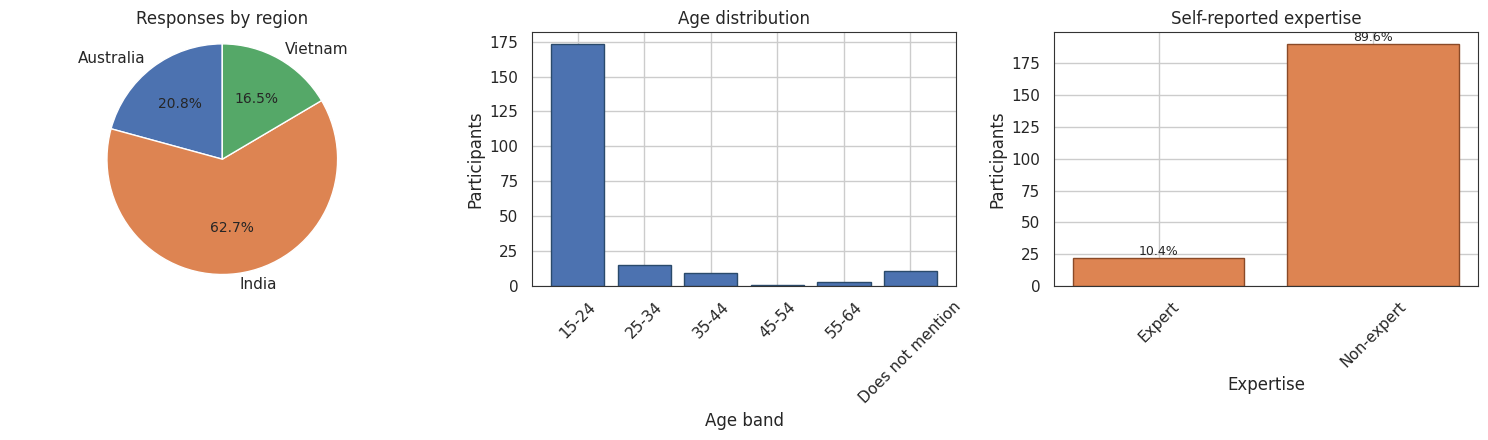

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Region
reg = demographics["Region"]
axes[0].pie(reg["n"], labels=reg["Region"], autopct="%1.1f%%", startangle=90,
            colors=[region_colors.get(r, "#999999") for r in reg["Region"]],
            wedgeprops={"linewidth": 1, "edgecolor": "white"})
axes[0].set_title("Responses by region")
axes[0].axis("equal")

# Age
ageb = demographics["AgeRange"]
axes[1].bar(ageb[labelOf("AgeRange")], ageb["n"], color="#4C72B0",
            edgecolor="#2A4A6B")
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Participants")
axes[1].set_title("Age distribution")
axes[1].tick_params(axis="x", rotation=45)

# Expertise
occ = demographics["Occupation"]
bars = axes[2].bar(occ[labelOf("Occupation")], occ["n"], color="#DD8452",
                   edgecolor="#8A4A28")
for bar, p in zip(bars, occ["%"]):
    axes[2].annotate(f"{p:.1f}%", (bar.get_x() + bar.get_width() / 2,
                                   bar.get_height()),
                     ha="center", va="bottom", fontsize=9)
axes[2].set_xlabel("Expertise")
axes[2].set_ylabel("Participants")
axes[2].set_title("Self-reported expertise")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
saveFig("fig_01_sample_composition")
plt.show()

### 2.4 Missing data

We measure missingness on the collected answers, before any imputation: a
respondent-by-item matrix, missingness per item, and missingness by subgroup.
The subgroup check tells us which variables the imputation model must include.


In [15]:
item_missing = pd.DataFrame({
    "Item": [labelOf(c) for c in rank_cols],
    "Column": rank_cols,
    "Missing": [int(df[c].isna().sum()) for c in rank_cols],
})
item_missing["% missing"] = [pct(m, len(df)) for m in item_missing["Missing"]]
item_missing = item_missing.sort_values("% missing", ascending=False)

print(f"Item-level missingness (n = {len(df)})")
print(item_missing.to_string(index=False))
print(f"\nOverall cell missingness across the {len(rank_cols)} analysis items: "
      f"{100 * df[rank_cols].isna().to_numpy().mean():.1f}%")

complete_cases = int(df[rank_cols].notna().all(axis=1).sum())
print(f"Complete cases on all items: {complete_cases} "
      f"({pct(complete_cases, len(df))}%) — this is the n a listwise-deletion "
      f"analysis would use, versus {len(df)} after imputation.")
saveTable(item_missing, "table_05_item_missingness")

Item-level missingness (n = 212)
                      Item  Column  Missing  % missing
         Prototype Novelty   QID29       91       42.9
   Increased Functionality   QID28       91       42.9
       Overall Likeability   QID24       85       40.1
       Tracker Likeability QID13_5       69       32.5
       Mapping Likeability QID13_4       64       30.2
   Geolocation Likeability QID13_6       59       27.8
Most Intuitive Interaction   QID22       40       18.9
           Interactiveness   QID21       34       16.0
           User-Experience   QID12       30       14.2
  Environmental Importance QID31_2        0        0.0
 Sustainability Importance QID31_1        0        0.0
         Social Importance QID31_3        0        0.0
       Economic Importance QID31_4        0        0.0

Overall cell missingness across the 13 analysis items: 20.4%
Complete cases on all items: 96 (45.3%) — this is the n a listwise-deletion analysis would use, versus 212 after imputation.
  saved ->

,Item,Column,Missing,% missing
2,Prototype Novelty,QID29,91,42.9
11,Increased Functionality,QID28,91,42.9
10,Overall Likeability,QID24,85,40.1
8,Tracker Likeability,QID13_5,69,32.5
7,Mapping Likeability,QID13_4,64,30.2
9,Geolocation Likeability,QID13_6,59,27.8
12,Most Intuitive Interaction,QID22,40,18.9
0,Interactiveness,QID21,34,16.0
1,User-Experience,QID12,30,14.2
4,Environmental Importance,QID31_2,0,0.0


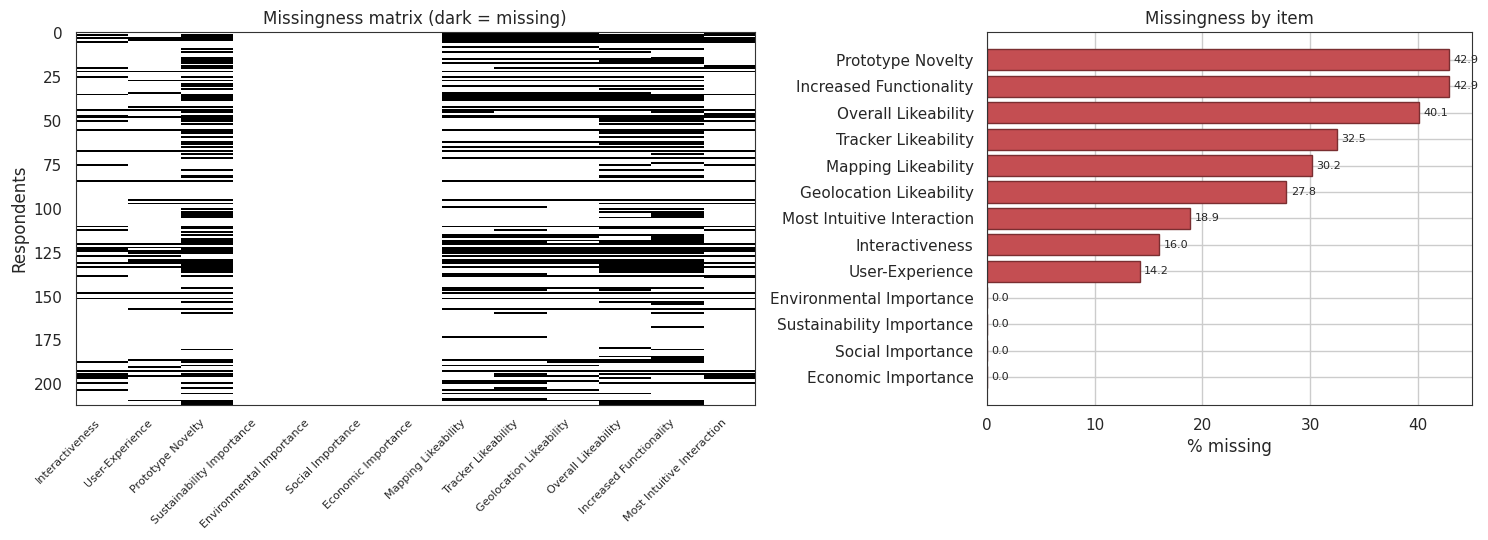

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5),
                         gridspec_kw={"width_ratios": [1.4, 1]})

# Missingness matrix
matrix = df[rank_cols].isna().astype(int)
axes[0].imshow(matrix.values, aspect="auto", cmap="Greys",
               interpolation="nearest", vmin=0, vmax=1)
axes[0].set_xticks(range(len(rank_cols)))
axes[0].set_xticklabels([labelOf(c) for c in rank_cols],
                        rotation=45, ha="right", fontsize=8)
axes[0].set_ylabel("Respondents")
axes[0].set_xlabel("")
axes[0].set_title("Missingness matrix (dark = missing)")
axes[0].grid(False)

# Item missingness bars
axes[1].barh(item_missing["Item"], item_missing["% missing"],
             color="#C44E52", edgecolor="#7A2E31")
axes[1].set_xlabel("% missing")
axes[1].set_title("Missingness by item")
axes[1].invert_yaxis()
for i, v in enumerate(item_missing["% missing"]):
    axes[1].text(v + 0.4, i, f"{v:.1f}", va="center", fontsize=8)

plt.tight_layout()
saveFig("fig_02_missingness")
plt.show()

Missingness by subgroup, with a chi-square test per grouping variable on the
number of missing items per respondent.


In [17]:
df["n_missing_items"] = df[rank_cols].isna().sum(axis=1)

missing_by_group = []
for gvar in grouping_vars:
    order = {"Region": region_order, "Gender": gender_order,
             "Occupation": expert_order, "Seen": seen_order,
             "AgeRange": age_order}[gvar]
    for level in orderedCategories(df[gvar], order):
        sub = df[df[gvar] == level]
        if len(sub) == 0:
            continue
        cells = len(sub) * len(rank_cols)
        missing_by_group.append({
            "Grouping": labelOf(gvar),
            "Level": level,
            "n": len(sub),
            "Missing cells": int(sub[rank_cols].isna().sum().sum()),
            "% missing": pct(int(sub[rank_cols].isna().sum().sum()), cells),
            "Mean items missing per person":
                round(sub["n_missing_items"].mean(), 2),
        })

missing_by_group = pd.DataFrame(missing_by_group)
print("Missingness by subgroup")
print(missing_by_group.to_string(index=False))
saveTable(missing_by_group, "table_06_missingness_by_subgroup")

# Kruskal-Wallis on per-person missing counts: does missingness depend on group?
print("\nDoes the amount of missing data depend on the grouping variable?")
mar_rows = []
for gvar in grouping_vars:
    groups = [g["n_missing_items"].values
              for lvl, g in df.groupby(gvar, observed=True)
              if lvl not in NON_RESPONSE_LEVELS
              and len(g) >= CONFIG["min_group_n"]]
    if len(groups) < 2:
        continue
    H, p = stats.kruskal(*groups)
    mar_rows.append({"Grouping": labelOf(gvar), "k groups": len(groups),
                     "H": round(H, 3), "p": round(p, 4),
                     "Interpretation": "depends on group" if p < CONFIG["alpha"]
                                       else "no detectable dependence"})
mar = pd.DataFrame(mar_rows)
print(mar.to_string(index=False))
print("\n'depends on group' means missingness is related to that observed variable. "
      "That is compatible with MAR and is a reason to keep the variable in the "
      "imputation model — but it rules out the simpler MCAR assumption.")
saveTable(mar, "table_07_mar_diagnostics")

Missingness by subgroup
   Grouping             Level   n  Missing cells  % missing  Mean items missing per person
     Region         Australia  44            112       19.6                           2.55
     Region             India 133            413       23.9                           3.11
     Region           Vietnam  35             38        8.4                           1.09
  Expertise            Expert  22             49       17.1                           2.23
  Expertise        Non-expert 190            514       20.8                           2.71
     Gender              Male 147            378       19.8                           2.57
     Gender            Female  64            178       21.4                           2.78
     Gender Prefer not to say   1              7       53.8                           7.00
Seen before                NO 176            479       20.9                           2.72
Seen before               YES  36             84       17.9       

,Grouping,k groups,H,p,Interpretation
0,Region,3,11.702,0.0029,depends on group
1,Expertise,2,0.099,0.7528,no detectable dependence
2,Gender,2,0.194,0.6596,no detectable dependence
3,Seen before,2,0.623,0.4299,no detectable dependence
4,Age Range,3,4.225,0.1209,no detectable dependence


#### Is skipping a question a finding in itself?

For each item we compare the share of respondents who answered it across regions
(chi-square test, Holm-corrected across items).


In [18]:
resp_rows, raw_p = [], []
regions_tested = [r for r in region_order
                  if (df["Region"] == r).sum() >= CONFIG["min_group_n"]]
for col in rank_cols:
    answered = df[col].notna()
    if answered.all():
        continue                                 # nothing to compare
    row = {"Item": labelOf(col)}
    for r in regions_tested:
        m = df["Region"] == r
        row[f"{r} % answered"] = pct(int(answered[m].sum()), int(m.sum()))
    table = pd.crosstab(df.loc[df["Region"].isin(regions_tested), "Region"],
                        answered[df["Region"].isin(regions_tested)])
    if table.shape[1] < 2:
        continue
    chi2, p, dof, expected, method = chi2Independence(table.values)
    row.update({"chi2": round(chi2, 2), "df": dof, "Method": method,
                "Cramer's V": round(np.sqrt(chi2 / (table.values.sum()
                                                    * (min(table.shape) - 1))), 3)})
    raw_p.append(p)
    resp_rows.append(row)

response_by_region = pd.DataFrame(resp_rows)
if not response_by_region.empty:
    adj = multipletests(raw_p, method=CONFIG["correction"])[1]
    response_by_region["p"] = np.round(raw_p, 4)
    response_by_region[f"p ({CONFIG['correction']})"] = np.round(adj, 4)
    response_by_region["Differs by region"] = np.where(adj < CONFIG["alpha"],
                                                       "yes", "no")
    print("Share of respondents who answered each item, by region")
    print(response_by_region.to_string(index=False))
    saveTable(response_by_region, "table_07b_response_rate_by_region")


Share of respondents who answered each item, by region
                      Item  Australia % answered  India % answered  Vietnam % answered  chi2  df     Method  Cramer's V      p  p (holm) Differs by region
           Interactiveness                  79.5              82.7                94.3  3.56   2 asymptotic       0.130 0.1684    0.3367                no
           User-Experience                  86.4              84.2                91.4  1.20   2 asymptotic       0.075 0.5487    0.5487                no
         Prototype Novelty                  65.9              47.4                82.9 16.01   2 asymptotic       0.275 0.0003    0.0030               yes
       Mapping Likeability                  68.2              65.4                88.6  7.12   2 asymptotic       0.183 0.0284    0.1706                no
       Tracker Likeability                  61.4              64.7                85.7  6.53   2 asymptotic       0.176 0.0382    0.1706                no
   Geolocation 

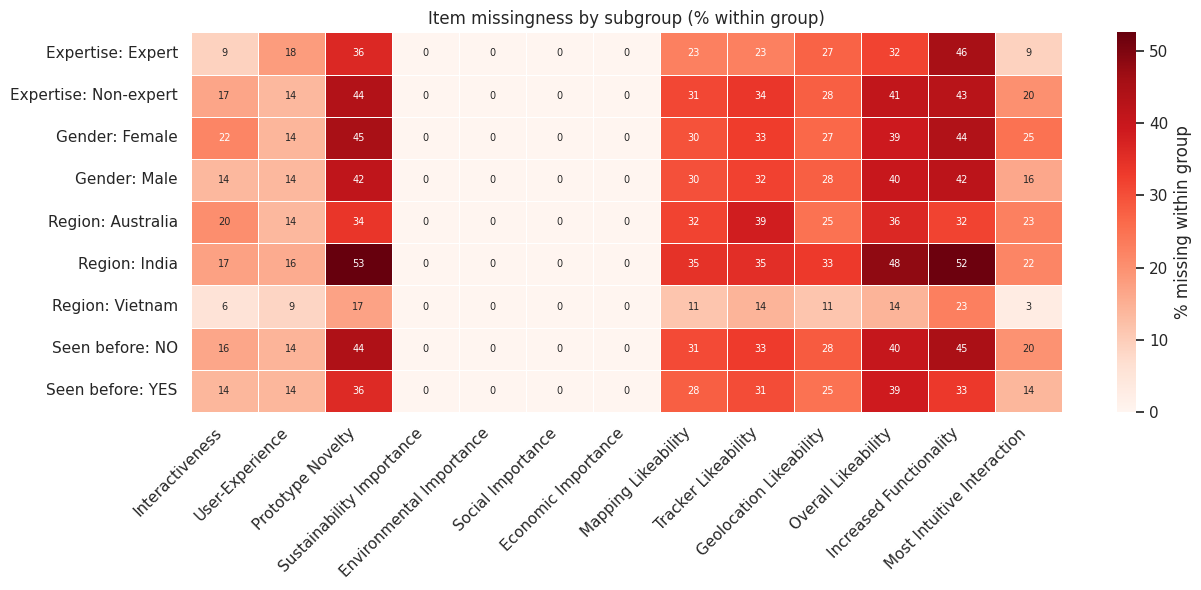

In [19]:
# Subgroup x item missingness heatmap.
heat_rows = []
for gvar in ["Region", "Occupation", "Gender", "Seen"]:
    order = {"Region": region_order, "Gender": gender_order,
             "Occupation": expert_order, "Seen": seen_order}[gvar]
    for level in orderedCategories(df[gvar], order):
        sub = df[df[gvar] == level]
        if len(sub) < CONFIG["min_group_n"]:
            continue
        for col in rank_cols:
            heat_rows.append({
                "Group": f"{labelOf(gvar)}: {level}",
                "Item": labelOf(col),
                "% missing": pct(int(sub[col].isna().sum()), len(sub)),
            })

heat = pd.DataFrame(heat_rows).pivot(index="Group", columns="Item",
                                     values="% missing")
heat = heat[[labelOf(c) for c in rank_cols]]

plt.figure(figsize=(13, 6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", vmin=0,
            cbar_kws={"label": "% missing within group"},
            annot_kws={"size": 7}, linewidths=0.4, linecolor="white")
plt.xlabel("")
plt.ylabel("")
plt.title("Item missingness by subgroup (% within group)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
saveFig("fig_03_missingness_by_subgroup")
plt.show()

### 2.5 Participant flow diagram (requires plotly)

Sankey diagram of Region → Age → Gender → Prior experience → Expertise.


In [20]:
if HAS_PLOTLY:
    flow_cols = ["Region", "AgeRange", "Gender", "Seen", "Occupation"]
    flow_titles = ["Region", "Age band", "Gender", "Seen before", "Expertise"]
    flow_orders = {"Region": region_order, "AgeRange": age_order,
                   "Gender": gender_order, "Seen": seen_order,
                   "Occupation": expert_order}

    labels, node_colors, offset = [], [], 0
    col_nodes = {}
    for i, c in enumerate(flow_cols):
        nodes = orderedCategories(df[c], flow_orders[c])      # order first,
        col_nodes[c] = nodes                                   # then index
        labels.extend([f"{n}" for n in nodes])
        node_colors.extend([group_palette[i % len(group_palette)]] * len(nodes))
        offset += len(nodes)

    # Node indices must be unique per column, since the same label (e.g. "NO")
    # can appear in more than one column.
    index = {}
    k = 0
    for c in flow_cols:
        for n in col_nodes[c]:
            index[(c, n)] = k
            k += 1

    sources, targets, values = [], [], []
    for left, right in zip(flow_cols[:-1], flow_cols[1:]):
        grouped = df.groupby([left, right], observed=True).size().reset_index(name="n")
        for _, r in grouped.iterrows():
            if (left, r[left]) in index and (right, r[right]) in index:
                sources.append(index[(left, r[left])])
                targets.append(index[(right, r[right])])
                values.append(int(r["n"]))

    fig_sankey = go.Figure(go.Sankey(
        arrangement="snap",
        node=dict(pad=15, thickness=22, label=labels, color=node_colors,
                  line=dict(color="grey", width=0.5)),
        link=dict(source=sources, target=targets, value=values,
                  color="rgba(120,120,140,0.25)"),
    ))
    fig_sankey.update_layout(
        font_size=13, paper_bgcolor="white", plot_bgcolor="white",
        margin=dict(l=40, r=40, t=80, b=40),
        annotations=[dict(text=f"<b>{t}</b>", x=x, y=1.06, xref="paper",
                          yref="paper", showarrow=False, font=dict(size=12))
                     for x, t in zip(np.linspace(0, 1, len(flow_cols)), flow_titles)],
    )
    out_html = Path(CONFIG["fig_dir"]) / "fig_04_participant_flow.html"
    fig_sankey.write_html(out_html)
    print(f"Saved {out_html}")
    fig_sankey.show()
else:
    print("plotly not installed — skipping the participant-flow diagram.")
    print("  pip install plotly")

Saved figures/fig_04_participant_flow.html


## Part 3 — Open-text answers → sentiment scores

The analysis items are free text, so we convert each answer to a sentiment score
from 0 (negative) to 100 (positive), with 50 as neutral.

### 3.1 Scoring method

For each answer we use the model's full probability distribution (expected score):

```python
score = 100 * (p_positive + 0.5 * p_neutral)
```

This gives a continuous score that equals 50 only when positive and negative
probabilities are balanced. The alternative, top-label confidence, is available
through `CONFIG["scoring_method"] = "label_confidence"` as a sensitivity check.

### 3.1a Ensemble of three models

To reduce dependence on any single model, we average the scores of three
pre-trained sentiment models with different training data
(`CONFIG["sentiment_models"]`). Labels are mapped to the same 0–100 scale
(negative = 0, neutral = 50, positive = 100; or 1–5 stars = 0, 25, 50, 75, 100).


In [21]:
# Robust sentiment: several Hugging Face models, combined.
# Each model is loaded the same way (AutoTokenizer + AutoModelForSequenceClassification)
# and turned into a 0-100 score from its full probability distribution, whatever its
# label set (negative/neutral/positive, or 1-5 stars). The final score per answer is
# the mean across models; agreement between models is reported in 3.1b.
SENTIMENT_MODELS = CONFIG.get("sentiment_models", [CONFIG["sentiment_model"]])


# position of a model label on the 0-100 scale (0 negative, 100 positive)
def labelValue(label):
    l = label.lower()
    m = re.search(r"([1-5])\s*star", l)
    if m:                                         # nlptown-style 1-5 stars
        return (int(m.group(1)) - 1) * 25.0
    if "neg" in l:
        return 0.0
    if "neu" in l:
        return 50.0
    if "pos" in l:
        return 100.0
    raise ValueError(f"Unknown sentiment label {label!r}")


# return a function mapping a list of texts -> list of 0-100 scores
def buildScorer(name):
    if not HAS_TRANSFORMERS:
        return None
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    import torch

    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSequenceClassification.from_pretrained(name)
    model.eval()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)

    # Read the label order from the model config rather than assuming it.
    id2label = {int(k): v for k, v in model.config.id2label.items()}
    values = np.array([labelValue(id2label[i]) for i in range(len(id2label))])
    three_class = set(values) == {0.0, 50.0, 100.0}

    def scoreBatch(texts):
        enc = tok(list(texts), padding=True, truncation=True, max_length=512,
                  return_tensors="pt").to(device)
        with torch.no_grad():
            probs = torch.softmax(model(**enc).logits, dim=-1).cpu().numpy()
        out = []
        for row in probs:
            if CONFIG["scoring_method"] == "label_confidence" and three_class:
                k = int(np.argmax(row))
                signed = {100.0: row[k], 0.0: -row[k]}.get(values[k], 0.0)
                out.append(round(float((signed + 1) * 50), 1))
            else:                                  # expected score
                out.append(round(float((row * values).sum()), 1))
        return out

    print(f"  loaded {name} on {device}; labels {[id2label[i] for i in sorted(id2label)]}")
    return scoreBatch


# score `cols` of `frame` with one model, caching to disk
def scoreFrame(frame, cols, name, tag=""):
    slug = re.sub(r"[^0-9A-Za-z]+", "_", name)
    cache_path = Path(CONFIG["cache_dir"]) / (
        f"sentiment_{slug}_{CONFIG['scoring_method']}{'_' + tag if tag else ''}.csv")
    if cache_path.exists():
        cached = pd.read_csv(cache_path, index_col=0)
        if list(cached.columns) == list(cols) and len(cached) == len(frame):
            print(f"Loaded cached scores for {name}")
            cached.index = frame.index
            return cached
        print(f"Cache for {name} does not match the current frame — recomputing.")

    scorer = buildScorer(name)
    if scorer is None:
        raise RuntimeError(
            f"transformers is not installed and no valid cache for {name}.\n"
            "pip install transformers torch, or remove the model from "
            "CONFIG['sentiment_models'].")
    scores = pd.DataFrame(index=frame.index, columns=cols, dtype=float)
    bs = CONFIG["sentiment_batch_size"]
    for col in cols:
        text = frame[col]
        mask = text.notna() & text.astype(str).str.strip().ne("")
        idx = text.index[mask]
        vals = text.loc[idx].astype(str).tolist()
        got = []
        for i in range(0, len(vals), bs):
            got.extend(scorer(vals[i:i + bs]))
        scores.loc[idx, col] = got
        print(f"  {name} | {col}: scored {len(vals)}, missing {int((~mask).sum())}")
    scores.to_csv(cache_path)
    print(f"Cached -> {cache_path}")
    return scores


model_scores = {}
for name in SENTIMENT_MODELS:
    try:
        model_scores[name] = scoreFrame(df, rank_cols, name)
    except Exception as exc:                       # one model failing must not stop the run
        print(f"  ** {name} skipped: {type(exc).__name__}: {exc}")
if not model_scores:
    raise RuntimeError("No sentiment model could be run — see the messages above.")

# Ensemble: mean of the models' scores, cell by cell.
df_scores = sum(model_scores.values()) / len(model_scores)
print(f"\nEnsemble of {len(model_scores)} model(s): {list(model_scores)}")
print(f"Score matrix: {df_scores.shape}")
print(df_scores.describe().round(1).to_string())


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (19 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  loaded lxyuan/distilbert-base-multilingual-cased-sentiments-student on cpu; labels ['positive', 'neutral', 'negative']
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID21: scored 178, missing 34
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID12: scored 182, missing 30
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID29: scored 121, missing 91
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID31_1: scored 212, missing 0
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID31_2: scored 212, missing 0
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID31_3: scored 212, missing 0
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID31_4: scored 212, missing 0
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID13_4: scored 148, missing 64
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID13_5: scored 143, missing 69
  lxyuan/distilb

### 3.1b Agreement between the sentiment models

For each item we report Spearman's ρ between each pair of models and Cohen's κ on
the negative / neutral / positive category (scores < 40, 40–60, > 60). Items with
low agreement are listed and should be interpreted with caution.


In [22]:
from itertools import combinations
from sklearn.metrics import cohen_kappa_score


# 0-100 score -> negative / neutral / positive (for kappa)
def toCategory(s):
    return pd.cut(s, [-np.inf, 40, 60, np.inf], labels=["neg", "neu", "pos"])


names = list(model_scores)
if len(names) < 2:
    print("Only one sentiment model ran — no agreement to compute.")
else:
    rows = []
    for col in rank_cols + ["ALL ITEMS"]:
        if col == "ALL ITEMS":
            data = {n: model_scores[n].stack() for n in names}
        else:
            data = {n: model_scores[n][col] for n in names}
        rhos, kappas = [], []
        for a, b in combinations(names, 2):
            pair = pd.concat([data[a], data[b]], axis=1).dropna()
            if len(pair) < 5:
                continue
            rhos.append(stats.spearmanr(pair.iloc[:, 0], pair.iloc[:, 1])[0])
            ca, cb = toCategory(pair.iloc[:, 0]), toCategory(pair.iloc[:, 1])
            kappas.append(cohen_kappa_score(ca.astype(str), cb.astype(str)))
        rows.append({
            "Item": "All items" if col == "ALL ITEMS" else labelOf(col),
            "n scored": int(pd.concat(data, axis=1).dropna().shape[0]),
            "Mean Spearman rho": round(float(np.nanmean(rhos)), 2) if rhos else np.nan,
            "Min Spearman rho": round(float(np.nanmin(rhos)), 2) if rhos else np.nan,
            "Mean kappa (neg/neu/pos)": round(float(np.nanmean(kappas)), 2) if kappas else np.nan,
        })
    sentiment_agreement = pd.DataFrame(rows)
    print(f"Agreement between the {len(names)} sentiment models")
    print("(rho: rank agreement of the 0-100 scores; kappa: agreement on "
          "negative / neutral / positive, chance-corrected)")
    print(sentiment_agreement.to_string(index=False))
    weak = sentiment_agreement[(sentiment_agreement["Mean Spearman rho"] < 0.5)
                               & (sentiment_agreement["Item"] != "All items")]
    if len(weak):
        print("\nItems where the models disagree (rho < 0.5) — treat their sentiment "
              "results with caution: " + ", ".join(weak["Item"]))
    saveTable(sentiment_agreement, "table_05b_sentiment_model_agreement")

    # Sensitivity: does the main regional result depend on the model? -----------------
    print("\nMean score per model (all scored cells):")
    for n in names:
        print(f"  {n:<60s} {model_scores[n].stack().mean():5.1f}")


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning:

A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:758: RuntimeWarning:

invalid value encountered in scalar divide

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning:

A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:758: RuntimeWarning:

invalid value encountered in scalar divide

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning:

A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' pa

Agreement between the 3 sentiment models
(rho: rank agreement of the 0-100 scores; kappa: agreement on negative / neutral / positive, chance-corrected)
                      Item  n scored  Mean Spearman rho  Min Spearman rho  Mean kappa (neg/neu/pos)
           Interactiveness       178               0.69              0.61                      0.34
           User-Experience       182               0.38              0.22                      0.43
         Prototype Novelty       121               0.59              0.56                      0.33
 Sustainability Importance       212               0.70              0.54                      0.00
  Environmental Importance       212               0.70              0.55                      0.00
         Social Importance       212               0.57              0.35                      0.00
       Economic Importance       212               0.68              0.53                      0.00
       Mapping Likeability       148            

### 3.2 Score distribution

We check how many scores sit exactly at 50, since a large number of ties reduces
the variance available for later tests.


Scored cells: 2193
Mean 70.5 | SD 12.3 | median 69.5 | range 8.8–97.6
Exactly 50 (neutral): 0.0% of scored cells


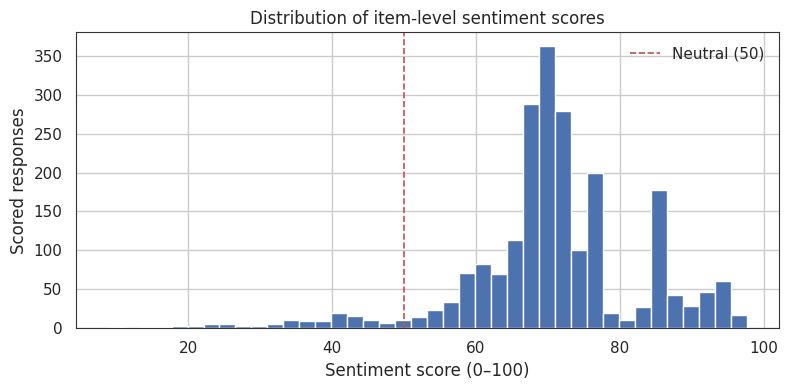

In [23]:
flat = df_scores.stack().dropna()
at_neutral = float((flat == 50).mean())
print(f"Scored cells: {len(flat)}")
print(f"Mean {flat.mean():.1f} | SD {flat.std():.1f} | "
      f"median {flat.median():.1f} | range {flat.min():.1f}–{flat.max():.1f}")
print(f"Exactly 50 (neutral): {100 * at_neutral:.1f}% of scored cells")
if at_neutral > 0.25 and CONFIG["scoring_method"] == "label_confidence":
    print("\n  NOTE: a large spike at exactly 50 is an artefact of the "
          "label-confidence mapping, not a property of the responses.\n"
          "  Re-running with CONFIG['scoring_method'] = 'expected_score' will "
          "spread these out. Compare both before reporting.")

plt.figure(figsize=(8, 4))
plt.hist(flat, bins=40, color="#4C72B0", edgecolor="white")
plt.axvline(50, color="#C44E52", linestyle="--", lw=1.2, label="Neutral (50)")
plt.xlabel("Sentiment score (0–100)")
plt.ylabel("Scored responses")
plt.title("Distribution of item-level sentiment scores")
plt.legend(frameon=False)
plt.tight_layout()
saveFig("fig_05_sentiment_distribution")
plt.show()

## Part 4 — Missing-data treatment

### 4.1 Comparison of five strategies

| Strategy | What it does | Limitation |
|---|---|---|
| `listwise` | keeps complete cases only | loses most of the sample; assumes MCAR |
| `fill_neutral` | blanks → 50 | shrinks variance |
| `fill_positive` | blanks → positive | upward bias (best case) |
| `fill_negative` | blanks → negative | downward bias (worst case) |
| `mice` | 20 imputations from the other items and grouping variables, pooled | assumes MAR |

The positive and negative fills bound the possible range. We use multiple
imputation (`CONFIG["mice_m"]` = 20, `sample_posterior=True`) with Region,
expertise, gender, prior exposure and age as predictors.


In [24]:
from sklearn.exceptions import ConvergenceWarning

results = {}

# Listwise deletion
results["listwise"] = df_scores.dropna()

# Constant fills, on the score scale
neutral_fill, positive_fill, negative_fill = 50.0, 90.0, 10.0
results["fill_neutral"] = df_scores.fillna(neutral_fill)
results["fill_positive"] = df_scores.fillna(positive_fill)
results["fill_negative"] = df_scores.fillna(negative_fill)

# Multiple imputation
# Auxiliary predictors: every variable Part 5 compares on. They help impute the
# scores but are not themselves part of the results.
aux = pd.DataFrame(index=df.index)
for r in region_order[1:]:                                   # dummy-coded
    aux[f"Region_{r}"] = (df["Region"] == r).astype(float)
aux["Expert"] = df["Occupation"].map({"Expert": 1.0, "Non-expert": 0.0})
aux["Female"] = df["Gender"].map({"Female": 1.0, "Male": 0.0})
aux["Seen"] = df["Seen"].map({"YES": 1.0, "NO": 0.0})
aux["Age"] = df["Age"].astype(float)

impute_input = pd.concat([df_scores, aux], axis=1)
lo, hi = CONFIG["sentiment_scale"]
min_vals = np.r_[np.full(len(rank_cols), lo), np.full(aux.shape[1], -np.inf)]
max_vals = np.r_[np.full(len(rank_cols), hi), np.full(aux.shape[1], np.inf)]


def imputeOnce(seed):
    imp = IterativeImputer(
        max_iter=CONFIG["mice_max_iter"],
        random_state=seed,
        sample_posterior=CONFIG["mice_sample_posterior"],
        min_value=min_vals, max_value=max_vals,   # keep scores on the 0-100 scale
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        arr = imp.fit_transform(impute_input)
    return pd.DataFrame(arr[:, :len(rank_cols)], columns=rank_cols,
                        index=df_scores.index)


m_imp = CONFIG["mice_m"] if CONFIG["mice_sample_posterior"] else 1
mi_frames = [imputeOnce(CONFIG["random_seed"] + i) for i in range(m_imp)]
# Observed values are identical in every dataset — only the gaps vary.
assert all(np.allclose(f.where(df_scores.notna()).fillna(-1),
                       df_scores.fillna(-1)) for f in mi_frames)

# For the distribution comparison use one completed dataset (a single draw keeps
# realistic spread; the average of the m draws would shrink it).
results["mice"] = mi_frames[0]
print(f"Multiple imputation: m = {m_imp} datasets, auxiliary predictors: "
      f"{list(aux.columns)}")

comparison = pd.DataFrame([
    {"Strategy": k,
     "n respondents": len(v),
     "Cells": int(v.notna().sum().sum()),
     "Mean": round(float(v.stack().mean()), 2),
     "SD": round(float(v.stack().std()), 2),
     "Median": round(float(v.stack().median()), 2)}
    for k, v in results.items()
])
print("Effect of the missing-data strategy on the score distribution "
      "('mice' = imputed dataset 1 of m)")
print(comparison.to_string(index=False))
saveTable(comparison, "table_08_missing_strategy_comparison")


Multiple imputation: m = 20 datasets, auxiliary predictors: ['Region_India', 'Region_Vietnam', 'Expert', 'Female', 'Seen', 'Age']
Effect of the missing-data strategy on the score distribution ('mice' = imputed dataset 1 of m)
     Strategy  n respondents  Cells  Mean    SD  Median
     listwise             96   1248 70.12 12.61   69.47
 fill_neutral            212   2756 66.34 13.74   68.23
fill_positive            212   2756 74.52 13.48   71.67
fill_negative            212   2756 58.17 26.76   68.23
         mice            212   2756 68.96 14.31   69.47
  saved -> tables/table_08_missing_strategy_comparison.csv


,Strategy,n respondents,Cells,Mean,SD,Median
0,listwise,96,1248,70.12,12.61,69.47
1,fill_neutral,212,2756,66.34,13.74,68.23
2,fill_positive,212,2756,74.52,13.48,71.67
3,fill_negative,212,2756,58.17,26.76,68.23
4,mice,212,2756,68.96,14.31,69.47


`listwise` and `mice` should give similar means. A large gap would suggest that
respondents with missing answers differ from those without.


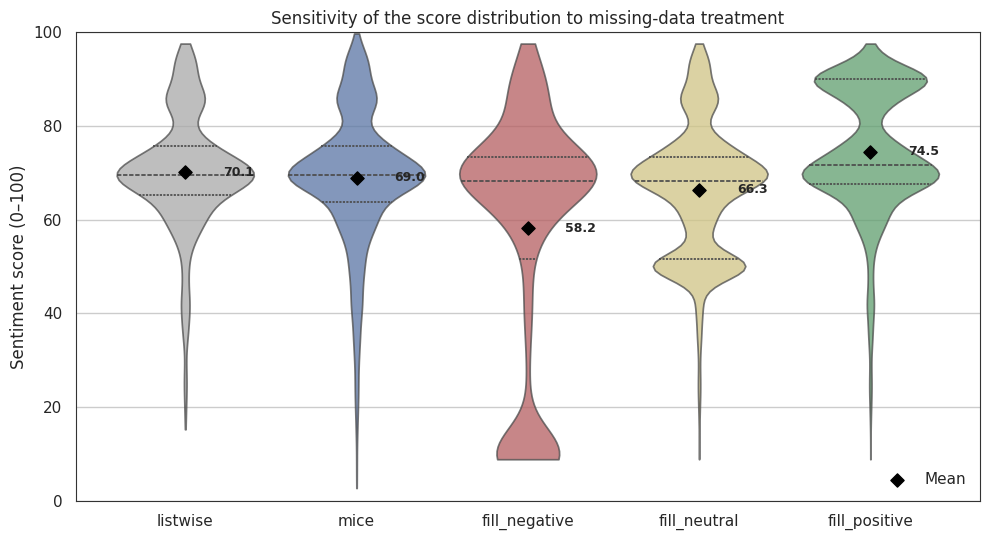

In [25]:
long = pd.concat(
    [pd.DataFrame({"Strategy": k, "score": v.stack().values})
     for k, v in results.items()],
    ignore_index=True)
order = ["listwise", "mice", "fill_negative", "fill_neutral", "fill_positive"]
palette = {"listwise": "#A9A9A9", "mice": "#4C72B0", "fill_negative": "#C44E52",
           "fill_neutral": "#DDCC77", "fill_positive": "#55A868"}

plt.figure(figsize=(10, 5.5))
sns.violinplot(data=long, x="Strategy", y="score", order=order, hue="Strategy",
               palette=palette, legend=False, inner="quartile", cut=0, alpha=0.75)
means = long.groupby("Strategy", observed=True)["score"].mean().reindex(order)
plt.scatter(range(len(order)), means.values, color="black", s=45, marker="D",
            zorder=5, label="Mean")
for i, m in enumerate(means.values):
    plt.text(i + 0.22, m, f"{m:.1f}", va="center", fontsize=9, fontweight="bold")
plt.ylim(0, 100)                      # the scale really is 0-100
plt.ylabel("Sentiment score (0–100)")
plt.xlabel("")
plt.title("Sensitivity of the score distribution to missing-data treatment")
plt.legend(frameon=False, loc="lower right")
plt.tight_layout()
saveFig("fig_06_missing_strategy_sensitivity")
plt.show()

### 4.2 Analysis frames

* `mi_full` — the 20 imputed datasets. Every imputation-based test is run on each
  and pooled.
* `df_mice_full` — the average of the 20 datasets, used only for descriptive
  summaries and the exploratory analysis in Part 6, never for p-values.

Grouping variables keep their text labels; numeric codes needed for correlations
are stored in separate `*_code` columns.


In [26]:
context_cols = ["ResponseId", "StartDate", "Region", "country", "Gender",
                "Occupation", "Seen", "Age", "AgeRange", "Duration Category",
                "Duration (in seconds)", "n_missing_items"]
context_cols = [c for c in context_cols if c in df.columns]

mi_full = [pd.concat([df[context_cols].copy(), f], axis=1) for f in mi_frames]
mice_mean = sum(mi_frames) / len(mi_frames)
df_mice_full = pd.concat([df[context_cols].copy(), mice_mean], axis=1)

# Numeric codes for correlation only. Labels above are left intact.
code_maps = {
    "Region":     {r: i for i, r in enumerate(region_order)},
    "Gender":     {g: i for i, g in enumerate(gender_order)},
    "Occupation": {"Expert": 1, "Non-expert": 0},
    "Seen":       {"NO": 0, "YES": 1},
}
for frame in [df_mice_full] + mi_full:
    for col, mapping in code_maps.items():
        frame[f"{col}_code"] = frame[col].map(mapping)

print(f"Analysis frames: {len(mi_full)} imputed datasets, each "
      f"{df_mice_full.shape[0]} respondents x {df_mice_full.shape[1]} columns")
for frame in [df_mice_full] + mi_full:
    assert frame[rank_cols].notna().all().all(), "imputation left missing values"
    assert frame[rank_cols].min().min() >= 0 and frame[rank_cols].max().max() <= 100, \
        "imputed values fell outside the 0-100 scale"
assert not pd.api.types.is_numeric_dtype(df_mice_full["Occupation"]), \
    "Occupation was re-coded to numbers — the label/code separation has been broken"

print("\nBefore vs after imputation. 'Between-imputation SD' is how much the item "
      "mean varies across the m datasets — the uncertainty single imputation hid:")
check = pd.DataFrame({
    "Item": [labelOf(c) for c in rank_cols],
    "n observed": [int(df_scores[c].notna().sum()) for c in rank_cols],
    "% imputed": [pct(int(df_scores[c].isna().sum()), len(df_scores))
                  for c in rank_cols],
    "Observed mean": [round(float(df_scores[c].mean()), 1) for c in rank_cols],
    "Imputed mean (pooled)": [round(float(np.mean([f[c].mean() for f in mi_full])), 1)
                              for c in rank_cols],
    "Between-imputation SD": [round(float(np.std([f[c].mean() for f in mi_full],
                                                 ddof=1)), 2)
                              if len(mi_full) > 1 else 0.0 for c in rank_cols],
})
check["Shift"] = (check["Imputed mean (pooled)"] - check["Observed mean"]).round(1)
print(check.to_string(index=False))
print("\nA shift here is expected and is not an error: with Region in the model, "
      "respondents are imputed towards their own group, and the groups that skipped "
      "more items differ from those that did not.")
saveTable(check, "table_09_imputation_check")

df_mice_full.to_csv(Path(CONFIG["table_dir"]) / "analysis_frame.csv", index=False)


Analysis frames: 20 imputed datasets, each 212 respondents x 29 columns

Before vs after imputation. 'Between-imputation SD' is how much the item mean varies across the m datasets — the uncertainty single imputation hid:
                      Item  n observed  % imputed  Observed mean  Imputed mean (pooled)  Between-imputation SD  Shift
           Interactiveness         178       16.0           77.9                   75.8                   0.60   -2.1
           User-Experience         182       14.2           82.5                   81.3                   0.44   -1.2
         Prototype Novelty         121       42.9           70.2                   67.8                   0.71   -2.4
 Sustainability Importance         212        0.0           70.9                   70.9                   0.00    0.0
  Environmental Importance         212        0.0           70.7                   70.7                   0.00    0.0
         Social Importance         212        0.0           70.6       

### 4.3 Pooling and limitations

Rank-based tests do not give an estimate with a standard error, so we pool the 20
Kruskal–Wallis statistics with the D2 rule (Li et al., 1991; van Buuren, 2018,
§5.3). Effect sizes are averaged across datasets.

Limitations: imputation assumes data are missing at random; a blank open-text
answer may mean "nothing to add" rather than a missing opinion; and up to 43% of
some items are imputed. For these reasons, available-case analysis is our primary
analysis (5.4) and imputation is used as a sensitivity check (5.8).


## Part 5 — Inferential statistics

We first check the test assumptions, then reliability, then group comparisons with
effect sizes and correction, post-hoc tests, correlations, and sensitivity checks.

### 5.1 Assumption checks

Normality (Shapiro–Wilk) and equal variances (Levene) on the observed scores.


In [27]:
observed = pd.concat([df[["Region"]], df_scores], axis=1)
observed = observed[~observed["Region"].isin(NON_RESPONSE_LEVELS)]

assumption_rows = []
for col in rank_cols:
    d = observed[[col, "Region"]].dropna()
    # Residuals from a one-way model, dummy-coded on region.
    X = sm.add_constant(pd.get_dummies(d["Region"], drop_first=True).astype(float))
    resid = sm.OLS(d[col].astype(float), X).fit().resid

    W, p_shapiro = stats.shapiro(resid)
    groups = [g[col].astype(float).values for _, g in d.groupby("Region", observed=True)
              if len(g) >= CONFIG["min_group_n"]]
    lev_stat, p_levene = stats.levene(*groups) if len(groups) > 1 else (np.nan, np.nan)

    assumption_rows.append({
        "Item": labelOf(col),
        "n observed": len(d),
        "Skew": round(float(stats.skew(d[col].astype(float))), 2),
        "Kurtosis": round(float(stats.kurtosis(d[col].astype(float))), 2),
        "Shapiro W": round(W, 3),
        "Shapiro p": round(p_shapiro, 4),
        "Normal?": "no" if p_shapiro < CONFIG["alpha"] else "not rejected",
        "Levene p": round(p_levene, 4) if not np.isnan(p_levene) else np.nan,
        "Equal variance?": ("no" if p_levene < CONFIG["alpha"]
                            else "not rejected") if not np.isnan(p_levene) else "n/a",
    })

assumptions = pd.DataFrame(assumption_rows)
print("Assumption checks on residuals of the observed scores (one-way, by region)")
print(assumptions.to_string(index=False))

n_nonnormal = int((assumptions["Normal?"] == "no").sum())
print(f"\nNormality rejected for {n_nonnormal} of {len(rank_cols)} items.")
print("Levene, not Bartlett, is the variance test reported here: Bartlett assumes "
      "normality, so on this data it would be testing one violated assumption "
      "while relying on another.")
if n_nonnormal > len(rank_cols) / 2:
    print("\n=> Non-parametric tests (Kruskal-Wallis / Mann-Whitney) are the primary "
          "analysis. Parametric equivalents appear in 5.8 as a sensitivity check only.")
saveTable(assumptions, "table_10_assumption_checks")

Assumption checks on residuals of the observed scores (one-way, by region)
                      Item  n observed  Skew  Kurtosis  Shapiro W  Shapiro p Normal?  Levene p Equal variance?
           Interactiveness         178 -1.34      1.80      0.905     0.0000      no    0.0128              no
           User-Experience         182 -2.39      7.00      0.799     0.0000      no    0.0003              no
         Prototype Novelty         121 -0.76      1.04      0.908     0.0000      no    0.3561    not rejected
 Sustainability Importance         212  0.42     -1.09      0.854     0.0000      no    0.5661    not rejected
  Environmental Importance         212  0.37     -0.95      0.901     0.0000      no    0.9261    not rejected
         Social Importance         212  0.26     -0.50      0.919     0.0000      no    0.4423    not rejected
       Economic Importance         212  0.33     -0.69      0.906     0.0000      no    0.0955    not rejected
       Mapping Likeability         14

,Item,n observed,Skew,Kurtosis,Shapiro W,Shapiro p,Normal?,Levene p,Equal variance?
0,Interactiveness,178,-1.34,1.80,0.905,0.0000,no,0.0128,no
1,User-Experience,182,-2.39,7.00,0.799,0.0000,no,0.0003,no
2,Prototype Novelty,121,-0.76,1.04,0.908,0.0000,no,0.3561,not rejected
3,Sustainability Importance,212,0.42,-1.09,0.854,0.0000,no,0.5661,not rejected
4,Environmental Importance,212,0.37,-0.95,0.901,0.0000,no,0.9261,not rejected
5,Social Importance,212,0.26,-0.50,0.919,0.0000,no,0.4423,not rejected
6,Economic Importance,212,0.33,-0.69,0.906,0.0000,no,0.0955,not rejected
7,Mapping Likeability,148,-0.75,0.64,0.936,0.0000,no,0.0924,not rejected
8,Tracker Likeability,143,-1.22,2.35,0.893,0.0000,no,0.1835,not rejected
9,Geolocation Likeability,153,-0.98,1.43,0.958,0.0001,no,0.0001,no


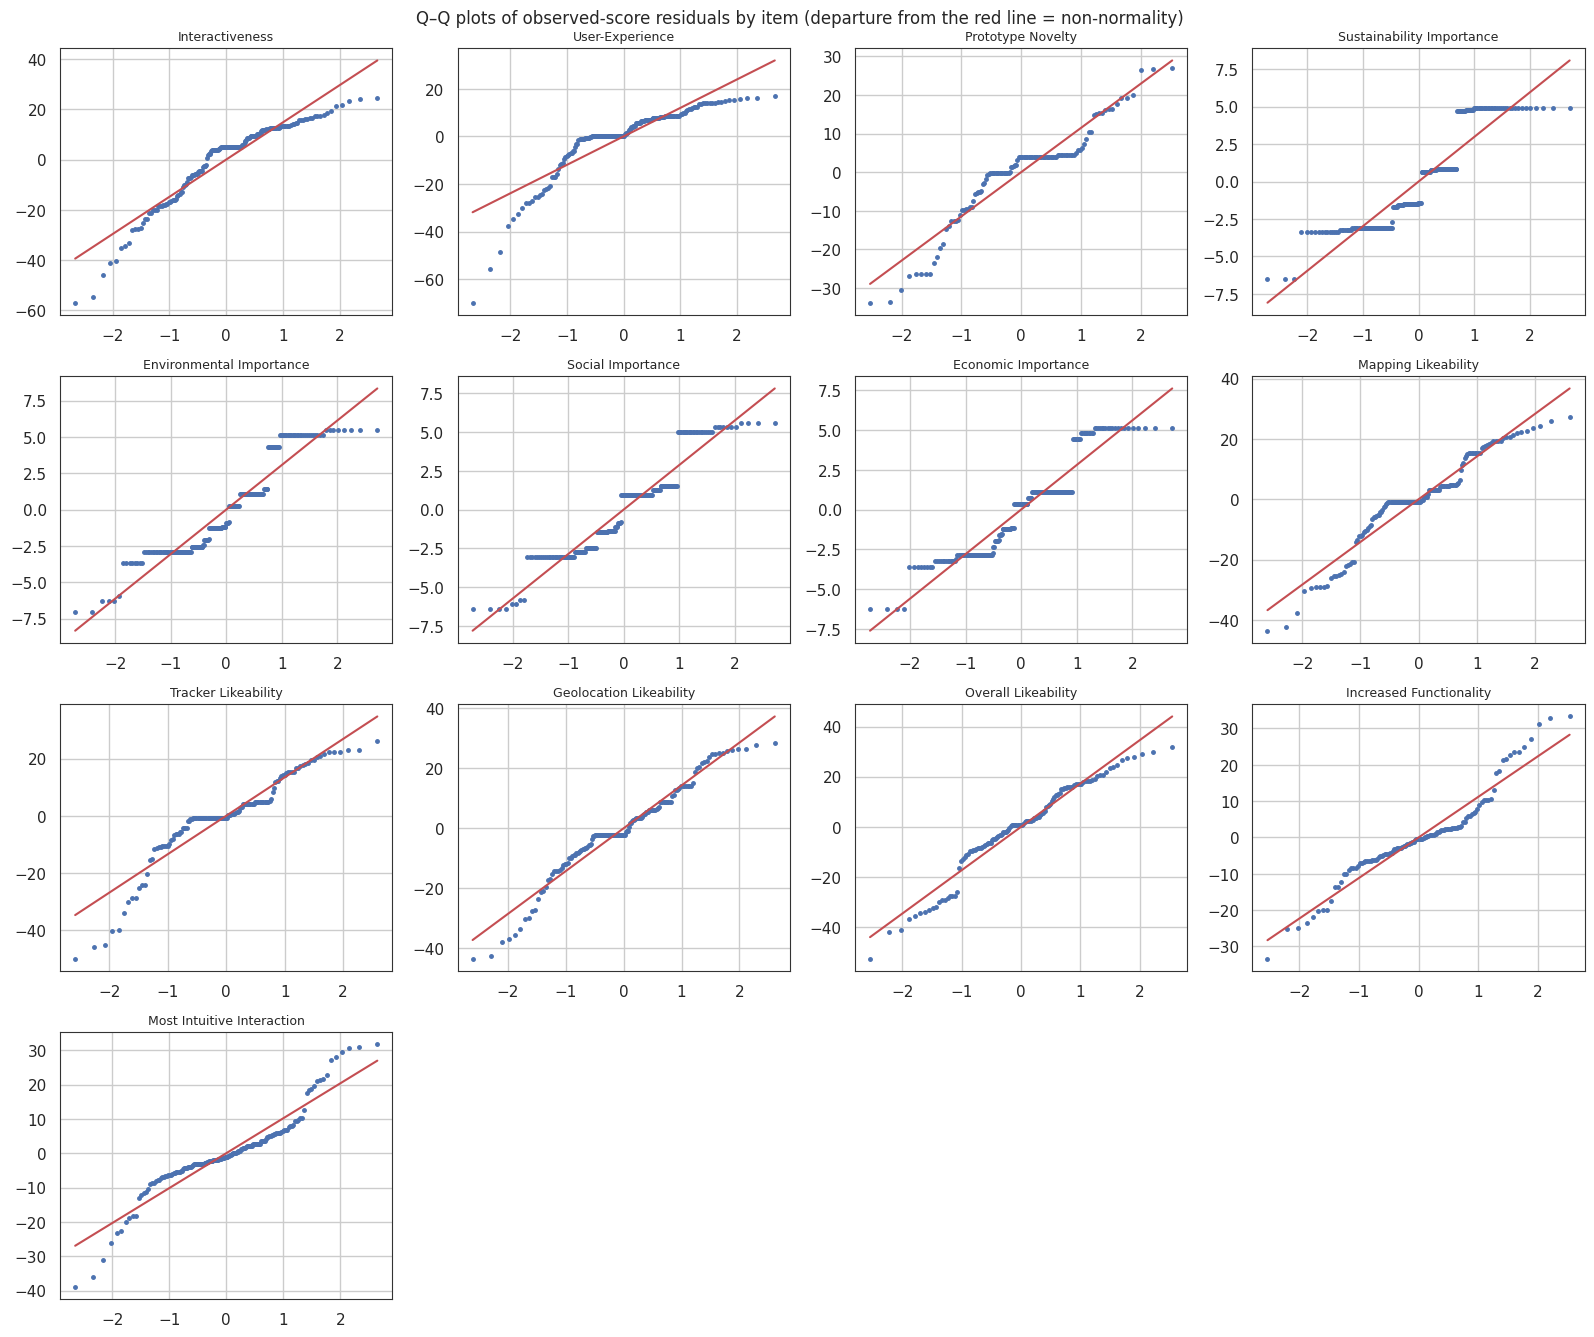

In [28]:
n_rows = int(np.ceil(len(rank_cols) / 4))          # grid grows with the item list
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 3.4 * n_rows))
for ax, col in zip(axes.ravel(), rank_cols):
    d = observed[[col, "Region"]].dropna()
    X = sm.add_constant(pd.get_dummies(d["Region"], drop_first=True).astype(float))
    resid = sm.OLS(d[col].astype(float), X).fit().resid
    stats.probplot(resid, dist="norm", plot=ax)
    ax.set_title(labelOf(col), fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.get_lines()[0].set_markersize(2.5)
    ax.get_lines()[0].set_color("#4C72B0")
    ax.get_lines()[1].set_color("#C44E52")
for ax in axes.ravel()[len(rank_cols):]:
    ax.axis("off")
fig.suptitle("Q–Q plots of observed-score residuals by item (departure from the red line = non-normality)",
             fontsize=12)
plt.tight_layout()
saveFig("fig_07_qq_residuals")
plt.show()

### 5.2 Reliability

Cronbach's α for each construct, computed on each imputed dataset and averaged.
Because the items are different open-ended questions scored by a classifier, a low
α may reflect that the questions cover different aspects rather than poor
reliability. We report inter-item correlations alongside α.


In [29]:
# cronbach's alpha and the complete-case n
def cronbachAlpha(frame):
    d = frame.apply(pd.to_numeric, errors="coerce").dropna()
    k = d.shape[1]
    if k < 2 or len(d) < 3:
        return np.nan, len(d)
    total_var = d.sum(axis=1).var(ddof=1)
    if not np.isfinite(total_var) or total_var == 0:
        return np.nan, len(d)
    item_var = d.var(axis=0, ddof=1).sum()
    return (k / (k - 1)) * (1 - item_var / total_var), len(d)


def reliabilityReport(frame, constructs=constructs):
    rows = []
    for name, items in constructs.items():
        items = [i for i in items if i in frame.columns]
        if len(items) < 2:
            continue
        a, n = cronbachAlpha(frame[items])
        inter = frame[items].corr().values
        mean_inter = inter[np.triu_indices_from(inter, k=1)].mean()
        # Alpha if each item is deleted: a value well above the overall alpha
        # flags an item that is dragging the construct down.
        worst_item, worst_gain = None, -np.inf
        if len(items) > 2:
            for it in items:
                a_del, _ = cronbachAlpha(frame[[c for c in items if c != it]])
                if pd.notna(a_del) and pd.notna(a) and (a_del - a) > worst_gain:
                    worst_gain, worst_item = a_del - a, it
        rows.append({
            "Construct": name,
            "k items": len(items),
            "n": n,
            "Cronbach's alpha": round(a, 3) if pd.notna(a) else np.nan,
            "Mean inter-item r": round(float(mean_inter), 3),
            "Best drop": labelOf(worst_item) if worst_item else "n/a",
            "Alpha gain if dropped": (round(worst_gain, 3)
                                      if np.isfinite(worst_gain) else np.nan),
        })
    return pd.DataFrame(rows)


# Run on each imputed dataset and average. Computing alpha on the AVERAGE of the
# imputations would inflate it, because averaging removes noise from the
# imputed cells and makes the items look more consistent than they are.
reliability_by_m = [reliabilityReport(f) for f in mi_full]
reliability = reliability_by_m[0].copy()
for c in ["Cronbach's alpha", "Mean inter-item r", "Alpha gain if dropped"]:
    # nanmean_quiet-style: 2-item constructs have no "alpha if dropped" (NaN)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        reliability[c] = np.round(np.nanmean(
            [r[c].astype(float).values for r in reliability_by_m], axis=0), 3)
print(f"Reliability of the a priori constructs (mean over m = {len(mi_full)} "
      "imputed datasets)")
print(reliability.to_string(index=False))

a_all = float(np.mean([cronbachAlpha(f[rank_cols])[0] for f in mi_full]))
n_all = len(df_mice_full)
print(f"\nAll {len(rank_cols)} items treated as one scale: alpha = {a_all:.3f} (n = {n_all})")
print("\nConventional reading: >=.70 acceptable, .60-.70 questionable, <.60 poor. "
      "A 2-item construct's alpha is especially unstable — report the correlation "
      "between the two items instead.")
saveTable(reliability, "table_11_reliability")

Reliability of the a priori constructs (mean over m = 20 imputed datasets)
            Construct  k items   n  Cronbach's alpha  Mean inter-item r                 Best drop  Alpha gain if dropped
      User-experience        2 212            -0.225             -0.098                       n/a                    NaN
          Likeability        2 212             0.513              0.347                       n/a                    NaN
          Interaction        2 212             0.133              0.081                       n/a                    NaN
           Usefulness        2 212             0.320              0.199                       n/a                    NaN
Sustainability-values        4 212             0.574              0.254 Sustainability Importance                 -0.018

All 13 items treated as one scale: alpha = 0.592 (n = 212)

Conventional reading: >=.70 acceptable, .60-.70 questionable, <.60 poor. A 2-item construct's alpha is especially unstable — report the co

,Construct,k items,n,Cronbach's alpha,Mean inter-item r,Best drop,Alpha gain if dropped
0,User-experience,2,212,-0.225,-0.098,n/a,NaN
1,Likeability,2,212,0.513,0.347,n/a,NaN
2,Interaction,2,212,0.133,0.081,n/a,NaN
3,Usefulness,2,212,0.320,0.199,n/a,NaN
4,Sustainability-values,4,212,0.574,0.254,Sustainability Importance,-0.018


### 5.3 Construct scores (observed answers, no imputation)

A construct score is the mean of the construct's items that a respondent answered,
provided they answered at least half of them (`MIN_ITEMS_FRACTION`); otherwise it is
missing.


In [30]:
# Construct scores from the OBSERVED answers (no imputation).
MIN_ITEMS_FRACTION = 0.5

construct_cols = []
construct_col_map = {}          # construct name -> column name, used in Part 7
obs_scores = pd.DataFrame(index=df.index)
for name, items in constructs.items():
    items = [i for i in items if i in df_scores.columns]
    if not items:
        continue
    col = "CS_" + re.sub(r"[^0-9A-Za-z]+", "_", name).strip("_")
    need = int(np.ceil(MIN_ITEMS_FRACTION * len(items)))
    answered = df_scores[items].notna().sum(axis=1)
    obs_scores[col] = df_scores[items].mean(axis=1).where(answered >= need)
    for frame in [df_mice_full] + mi_full:       # imputed version: Part 6 only
        frame[col] = frame[items].mean(axis=1)
    construct_cols.append(col)
    construct_col_map[name] = col
    question_labels[col] = name

# Frame used for every construct table, test and figure from here on.
constructs_obs = pd.concat([df[context_cols], obs_scores], axis=1)

print("Construct scores (observed answers, no imputation)")
summary = constructs_obs[construct_cols].describe().round(1)
summary.loc["n scored"] = constructs_obs[construct_cols].notna().sum()
print(summary.to_string())


Construct scores (observed answers, no imputation)
          CS_User_experience  CS_Likeability  CS_Interaction  CS_Usefulness  CS_Sustainability_values
count                  185.0           149.0           181.0          135.0                     212.0
mean                    76.2            68.3            70.6           68.7                      70.7
std                     11.8            12.6            10.8           13.0                       2.0
min                      8.8            22.7            35.3           16.2                      66.0
25%                     71.4            62.4            65.3           63.5                      69.3
50%                     75.6            69.5            72.7           71.1                      70.7
75%                     85.7            75.1            76.9           77.2                      71.7
max                     97.4            96.4            94.8           96.4                      75.7
n scored               185.0   

#### Scores by group — questions and constructs in separate tables

For each grouping variable we report two tables, each cell as *mean ± SD (n)*:

* **Table A** — every question on its own (n = respondents who answered it).
* **Table B** — the construct scores, with the items each construct contains.


In [31]:
def fmtCell(values):
    v = pd.Series(values, dtype=float).dropna()
    if len(v) == 0:
        return "–"
    sd = v.std(ddof=1) if len(v) > 1 else float("nan")
    return f"{v.mean():.1f} ± {sd:.1f} ({len(v)})"


def levelsFor(gvar, order):
    return [g for g in orderedCategories(df[gvar], order)
            if g not in NON_RESPONSE_LEVELS
            and (df[gvar] == g).sum() >= CONFIG["min_group_n"]]


# table A: every question on its own (no constructs)
def itemTable(gvar, order):
    levels = levelsFor(gvar, order)
    in_groups = df[gvar].isin(levels)
    rows = []
    for it in [c for c in rank_cols if c in df_scores.columns]:
        row = {"Question": labelOf(it),
               "Total": fmtCell(df_scores.loc[in_groups, it])}
        for g in levels:
            row[g] = fmtCell(df_scores.loc[df[gvar] == g, it])
        rows.append(row)
    return pd.DataFrame(rows)


# table B: construct scores only
def constructTable(gvar, order):
    levels = levelsFor(gvar, order)
    in_groups = df[gvar].isin(levels)
    rows = []
    for name, items in constructs.items():
        ccol = construct_col_map.get(name)
        if ccol is None:
            continue
        row = {"Construct": name,
               "Items": ", ".join(labelOf(i) for i in items),
               "Total": fmtCell(constructs_obs.loc[in_groups, ccol])}
        for g in levels:
            row[g] = fmtCell(constructs_obs.loc[df[gvar] == g, ccol])
        rows.append(row)
    return pd.DataFrame(rows)


SHOW_BREAKDOWN_FOR = grouping_vars        # e.g. ["Region"] for a shorter output
for gvar in SHOW_BREAKDOWN_FOR:
    order = orderFor(gvar)

    ta = itemTable(gvar, order)
    title = f"Table A — Question scores by {labelOf(gvar)} (no constructs) — mean ± SD (n)"
    print("\n" + title + "\n" + "-" * len(title))
    print(ta.to_string(index=False))
    saveTable(ta, f"table_12b_items_by_{gvar}")

    tb = constructTable(gvar, order)
    title = f"Table B — Construct scores by {labelOf(gvar)} — mean ± SD (n)"
    print("\n" + title + "\n" + "-" * len(title))
    print(tb.to_string(index=False))
    saveTable(tb, f"table_12c_constructs_by_{gvar}")


Table A — Question scores by Region (no constructs) — mean ± SD (n)
-------------------------------------------------------------------
                  Question             Total        Australia             India          Vietnam
           Interactiveness 77.9 ± 16.0 (178) 76.3 ± 18.9 (35) 80.8 ± 12.8 (110) 69.9 ± 19.5 (33)
           User-Experience 82.5 ± 13.8 (182) 78.7 ± 20.2 (38)  85.4 ± 8.9 (112) 77.2 ± 16.0 (32)
         Prototype Novelty 70.2 ± 12.0 (121)  73.6 ± 9.5 (29)  69.3 ± 12.5 (63) 68.9 ± 13.0 (29)
 Sustainability Importance  70.9 ± 3.2 (212)  71.0 ± 3.0 (44)  70.8 ± 3.3 (133)  70.9 ± 3.0 (35)
  Environmental Importance  70.7 ± 3.2 (212)  71.4 ± 3.3 (44)  70.6 ± 3.1 (133)  70.3 ± 3.4 (35)
         Social Importance  70.6 ± 3.0 (212)  70.2 ± 2.7 (44)  70.8 ± 3.0 (133)  70.4 ± 3.3 (35)
       Economic Importance  70.8 ± 2.9 (212)  71.3 ± 2.6 (44)  70.6 ± 2.9 (133)  70.9 ± 3.4 (35)
       Mapping Likeability 68.4 ± 14.6 (148) 66.2 ± 17.9 (30)  70.3 ± 12.5 (87) 65.1 ± 

### 5.4 Group comparisons

Each item is tested on the respondents who answered it (available-case analysis);
no values are imputed. This is our primary analysis, because a blank open-text
answer often means "nothing to say" and some items are up to 43% blank.

* **2 groups** → Mann–Whitney *U*, effect size Cliff's δ
* **3 or more groups** → Kruskal–Wallis *H*, effect size ε² = H/(n−1)
* Groups smaller than `CONFIG["min_group_n"]` are excluded and reported.
* p-values are corrected within each family of items (Holm).
* Non-answers ("Does not mention", "Not reported") are excluded.

`groupComparisonMi` runs the same tests on the imputed datasets and pools them
with the D2 rule (used in 5.8).


In [32]:
# cliff's delta. Positive => group `a` tends to score higher than `b`
def cliffsDelta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    gt = (a[:, None] > b[None, :]).sum()
    lt = (a[:, None] < b[None, :]).sum()
    return (gt - lt) / (len(a) * len(b))


def interpretDelta(d):
    d = abs(d)
    return ("negligible" if d < 0.147 else "small" if d < 0.33
            else "medium" if d < 0.474 else "large")


# effect size for Kruskal-Wallis. Algebraically H/(n-1)
def epsilonSquared(H, n):
    return H / (n - 1) if n > 1 else np.nan


def interpretEpsilon(e):
    return ("negligible" if e < 0.01 else "small" if e < 0.06
            else "medium" if e < 0.14 else "large")


# non-parametric comparison of `cols` across levels of `group_col`
def groupComparison(frame, cols, group_col, order=None,
                   min_n=None, correction=None, alpha=None):
    min_n = min_n or CONFIG["min_group_n"]
    correction = correction or CONFIG["correction"]
    alpha = alpha or CONFIG["alpha"]

    levels = [g for g in orderedCategories(frame[group_col], order or [])
              if g not in NON_RESPONSE_LEVELS]
    sizes = frame[group_col].value_counts()
    kept = [g for g in levels if sizes.get(g, 0) >= min_n]
    dropped = [(g, int(sizes.get(g, 0))) for g in levels if g not in kept]

    if len(kept) < 2:
        return pd.DataFrame(), dropped

    rows, raw_p = [], []
    for c in cols:
        if c not in frame.columns:
            continue
        series = pd.to_numeric(frame[c], errors="coerce")
        samples = [series[frame[group_col] == g].dropna().values for g in kept]
        if any(len(s) < 2 for s in samples):
            continue

        row = {"Variable": labelOf(c)}
        allv = np.concatenate(samples)               # everyone in the tested groups
        row["Total (M±SD)"] = f"{allv.mean():.1f} ± {allv.std(ddof=1):.1f}"
        row["Total (n)"] = len(allv)
        for g, s in zip(kept, samples):
            row[f"{g} (M±SD)"] = f"{s.mean():.1f} ± {s.std(ddof=1):.1f}"
            row[f"{g} (n)"] = len(s)

        if len(kept) == 2:
            U, p = stats.mannwhitneyu(samples[0], samples[1],
                                      alternative="two-sided")
            d = cliffsDelta(samples[0], samples[1])
            row.update({"Test": "Mann-Whitney", "Statistic": round(float(U), 1),
                        "Effect size": round(float(d), 3),
                        "Effect metric": "Cliff's d",
                        "Magnitude": interpretDelta(d),
                        "Higher": kept[0] if d > 0 else kept[1] if d < 0 else "tie"})
        else:
            H, p = stats.kruskal(*samples)
            n_tot = sum(len(s) for s in samples)
            e2 = epsilonSquared(H, n_tot)
            means = {g: s.mean() for g, s in zip(kept, samples)}
            row.update({"Test": "Kruskal-Wallis", "Statistic": round(float(H), 3),
                        "Effect size": round(float(e2), 3),
                        "Effect metric": "epsilon^2",
                        "Magnitude": interpretEpsilon(e2),
                        "Higher": max(means, key=means.get)})
        raw_p.append(p)
        rows.append(row)

    res = pd.DataFrame(rows)
    if not res.empty:
        # Correct on the UNROUNDED p-values, then round for display.
        adjusted = multipletests(raw_p, method=correction)[1]
        res["p"] = np.round(raw_p, 4)
        res[f"p ({correction})"] = np.round(adjusted, 4)
        res["Significant"] = np.where(adjusted < alpha, "yes", "no")
    return res, dropped


# pool m chi-square statistics on k df with the D2 rule
def poolD2(chi2_stats, k):
    d = np.asarray(chi2_stats, float)
    m = len(d)
    if m == 1:
        return d[0] / k, k, np.inf, float(stats.chi2.sf(d[0], k))
    r = (1 + 1 / m) * np.var(np.sqrt(d), ddof=1)
    D2 = max((d.mean() / k - (m + 1) / (m - 1) * r) / (1 + r), 0.0)
    if r < 1e-10:                   # no between-imputation variation
        return D2, k, np.inf, float(stats.chi2.sf(D2 * k, k))
    df2 = k ** (-3 / m) * (m - 1) * (1 + 1 / r) ** 2
    return D2, k, df2, float(stats.f.sf(D2, k, df2))


# group comparison pooled across multiply-imputed datasets
def groupComparisonMi(frames, cols, group_col, order=None,
                        min_n=None, correction=None, alpha=None):
    min_n = min_n or CONFIG["min_group_n"]
    correction = correction or CONFIG["correction"]
    alpha = alpha or CONFIG["alpha"]
    base = frames[0]

    levels = [g for g in orderedCategories(base[group_col], order or [])
              if g not in NON_RESPONSE_LEVELS]
    sizes = base[group_col].value_counts()
    kept = [g for g in levels if sizes.get(g, 0) >= min_n]
    dropped = [(g, int(sizes.get(g, 0))) for g in levels if g not in kept]
    if len(kept) < 2:
        return pd.DataFrame(), dropped
    k = len(kept) - 1

    rows, raw_p = [], []
    for c in cols:
        if c not in base.columns:
            continue
        H_list, eff_list, means, sds, tots = [], [], [], [], []
        for f in frames:
            series = pd.to_numeric(f[c], errors="coerce")
            samples = [series[f[group_col] == g].dropna().values for g in kept]
            try:
                H, _ = stats.kruskal(*samples)
            except ValueError:            # all values identical
                H = 0.0
            H_list.append(H)
            n_tot = sum(len(s) for s in samples)
            eff_list.append(cliffsDelta(samples[0], samples[1]) if len(kept) == 2
                            else epsilonSquared(H, n_tot))
            means.append([s.mean() for s in samples])
            sds.append([s.std(ddof=1) for s in samples])
            allv = np.concatenate(samples)
            tots.append((allv.mean(), allv.std(ddof=1), len(allv)))
        D2, df1, df2, p = poolD2(H_list, k)
        means, sds = np.mean(means, axis=0), np.mean(sds, axis=0)
        eff = float(np.mean(eff_list))

        row = {"Variable": labelOf(c)}
        t_mu, t_sd, t_n = np.mean(tots, axis=0)
        row["Total (M±SD)"] = f"{t_mu:.1f} ± {t_sd:.1f}"
        row["Total (n)"] = int(t_n)
        for g, mu, sd in zip(kept, means, sds):
            row[f"{g} (M±SD)"] = f"{mu:.1f} ± {sd:.1f}"
            row[f"{g} (n)"] = int(sizes[g])
        row.update({
            "Test": ("Mann-Whitney" if len(kept) == 2 else "Kruskal-Wallis")
                    + f" (MI, m={len(frames)})",
            "Statistic": round(float(D2), 3),
            "df": f"{df1}, {df2:.0f}" if df2 < 1e5 else f"{df1}, inf",
            "Effect size": round(eff, 3),
            "Effect metric": "Cliff's d" if len(kept) == 2 else "epsilon^2",
            "Magnitude": (interpretDelta(eff) if len(kept) == 2
                          else interpretEpsilon(eff)),
            "Higher": ((kept[0] if eff > 0 else kept[1] if eff < 0 else "tie")
                       if len(kept) == 2 else kept[int(np.argmax(means))]),
        })
        raw_p.append(p)
        rows.append(row)

    res = pd.DataFrame(rows)
    if not res.empty:
        adjusted = multipletests(raw_p, method=correction)[1]
        res["p"] = np.round(raw_p, 4)
        res[f"p ({correction})"] = np.round(adjusted, 4)
        res["Significant"] = np.where(adjusted < alpha, "yes", "no")
    return res, dropped


# Item-level tests: AVAILABLE CASES (primary)
# Real scores only; each item uses everyone who answered it.
available = pd.concat([df[context_cols], df_scores], axis=1)

group_results = {}
for gvar in grouping_vars:
    order = {"Region": region_order, "Gender": gender_order,
             "Occupation": expert_order, "Seen": seen_order,
             "AgeRange": age_order}[gvar]
    res, dropped = groupComparison(available, rank_cols, gvar, order)
    group_results[gvar] = res
    header = f"Items by {labelOf(gvar)} — answered responses only"
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))
    if dropped:
        print(f"Excluded (n < {CONFIG['min_group_n']}): "
              + ", ".join(f"{g} (n={n})" for g, n in dropped))
    if res.empty:
        print("Not enough groups of usable size to test.")
    else:
        print(res.to_string(index=False))           # (n) = answered, per group
        saveTable(res, f"table_12_items_by_{gvar}")


Items by Region — answered responses only
                  Variable Total (M±SD)  Total (n) Australia (M±SD)  Australia (n) India (M±SD)  India (n) Vietnam (M±SD)  Vietnam (n)           Test  Statistic  Effect size Effect metric  Magnitude    Higher      p  p (holm) Significant
           Interactiveness  77.9 ± 16.0        178      76.3 ± 18.9             35  80.8 ± 12.8        110    69.9 ± 19.5           33 Kruskal-Wallis      7.860        0.044     epsilon^2      small     India 0.0196    0.2161          no
           User-Experience  82.5 ± 13.8        182      78.7 ± 20.2             38   85.4 ± 8.9        112    77.2 ± 16.0           32 Kruskal-Wallis      8.660        0.048     epsilon^2      small     India 0.0132    0.1580          no
         Prototype Novelty  70.2 ± 12.0        121       73.6 ± 9.5             29  69.3 ± 12.5         63    68.9 ± 13.0           29 Kruskal-Wallis      4.306        0.036     epsilon^2      small Australia 0.1161    1.0000          no
 Sust

In [33]:
# Construct scores from observed answers (5.3), no imputation.
construct_results = {}
for gvar in grouping_vars:
    order = {"Region": region_order, "Gender": gender_order,
             "Occupation": expert_order, "Seen": seen_order,
             "AgeRange": age_order}[gvar]
    res, dropped = groupComparison(constructs_obs, construct_cols, gvar, order)
    construct_results[gvar] = res
    if not res.empty:
        print(f"\nConstructs by {labelOf(gvar)} (observed answers)")
        if dropped:
            print(f"Excluded (n < {CONFIG['min_group_n']}): "
                  + ", ".join(f"{g} (n={n})" for g, n in dropped))
        show = [c for c in res.columns if not c.endswith("(n)")]
        print(res[show].to_string(index=False))
        saveTable(res, f"table_13_constructs_by_{gvar}")


Constructs by Region (observed answers)
             Variable Total (M±SD) Australia (M±SD) India (M±SD) Vietnam (M±SD)           Test  Statistic  Effect size Effect metric  Magnitude    Higher      p  p (holm) Significant
      User-experience  76.2 ± 11.8      72.4 ± 15.3   79.1 ± 9.5    71.1 ± 11.6 Kruskal-Wallis     15.863        0.086     epsilon^2     medium     India 0.0004    0.0018         yes
          Likeability  68.3 ± 12.6      65.5 ± 16.0  70.3 ± 10.1    65.2 ± 14.3 Kruskal-Wallis      2.439        0.016     epsilon^2      small     India 0.2954    0.8861          no
          Interaction  70.6 ± 10.8      70.7 ± 10.9   72.5 ± 9.6    64.1 ± 11.8 Kruskal-Wallis     12.193        0.068     epsilon^2     medium     India 0.0023    0.0090         yes
           Usefulness  68.7 ± 13.0      70.3 ± 13.3  69.0 ± 11.8    66.5 ± 15.4 Kruskal-Wallis      1.724        0.013     epsilon^2      small Australia 0.4222    0.8861          no
Sustainability-values   70.7 ± 2.0       71.

#### Number of tests

Correction is applied within each table, but many families of tests are run. We
report the total number of tests so that the overall false-positive risk can be
judged; results outside the primary comparisons should be read as exploratory.


In [34]:
n_tests = sum(len(r) for r in group_results.values()) + \
          sum(len(r) for r in construct_results.values())
n_families = len([r for r in group_results.values() if not r.empty]) + \
             len([r for r in construct_results.values() if not r.empty])
sig = sum(int((r["Significant"] == "yes").sum())
          for r in list(group_results.values()) + list(construct_results.values())
          if not r.empty)
print(f"Tests run: {n_tests} across {n_families} families")
print(f"Significant after within-family {CONFIG['correction']} correction: {sig}")
print(f"Expected false positives at alpha={CONFIG['alpha']} with no correction: "
      f"{CONFIG['alpha'] * n_tests:.1f}")

Tests run: 90 across 10 families
Significant after within-family holm correction: 2
Expected false positives at alpha=0.05 with no correction: 4.5


### 5.5 Post-hoc tests

Dunn's test, run only for items where the Kruskal–Wallis test was significant
after correction.


In [35]:
if not HAS_POSTHOCS:
    print("scikit-posthocs not installed — skipping post-hoc tests.")
    print("  pip install scikit-posthocs")
else:
    posthoc_tables = {}
    for gvar, res in group_results.items():
        if res.empty:
            continue
        sig_items = res.loc[res["Significant"] == "yes", "Variable"].tolist()
        multi_level = available[gvar].value_counts()
        multi_level = (multi_level >= CONFIG["min_group_n"]).sum() > 2
        if not sig_items or not multi_level:
            continue
        rev = {labelOf(c): c for c in rank_cols}
        for item_label in sig_items:
            col = rev.get(item_label)
            if col is None:
                continue
            d = available[[col, gvar]].dropna()
            d = d[~d[gvar].isin(NON_RESPONSE_LEVELS)]
            keep = d[gvar].value_counts()
            keep = keep[keep >= CONFIG["min_group_n"]].index
            d = d[d[gvar].isin(keep)]
            dunn = sp.posthoc_dunn(d, val_col=col, group_col=gvar,
                                   p_adjust="bonferroni")
            medians = d.groupby(gvar, observed=True)[col].median()
            rows = []
            for i, g1 in enumerate(dunn.index):
                for g2 in dunn.index[i + 1:]:
                    rows.append({
                        "Group 1": g1, "Group 2": g2,
                        "Median 1": round(float(medians[g1]), 1),
                        "Median 2": round(float(medians[g2]), 1),
                        "Median diff": round(float(medians[g1] - medians[g2]), 1),
                        "p (Bonferroni)": round(float(dunn.loc[g1, g2]), 4),
                        "Significant": "yes" if dunn.loc[g1, g2] < CONFIG["alpha"] else "no",
                    })
            table = pd.DataFrame(rows)
            posthoc_tables[(gvar, col)] = table
            print(f"\nDunn's post-hoc — {item_label} by {labelOf(gvar)}")
            print(table.to_string(index=False))
            saveTable(table, f"table_14_posthoc_{gvar}_{col}")

    if not posthoc_tables:
        print("No omnibus test survived correction, so no post-hoc tests were run.")
        print("This is the correct outcome, not a failure — running pairwise "
              "contrasts anyway is what inflates false positives.")

scikit-posthocs not installed — skipping post-hoc tests.
  pip install scikit-posthocs


### 5.6 Scores by region — constructs and individual questions

Box plots from the observed answers. Each box shows the median (line), the mean
(white diamond, labelled) and all respondents (dots); *n* is the number with a score.


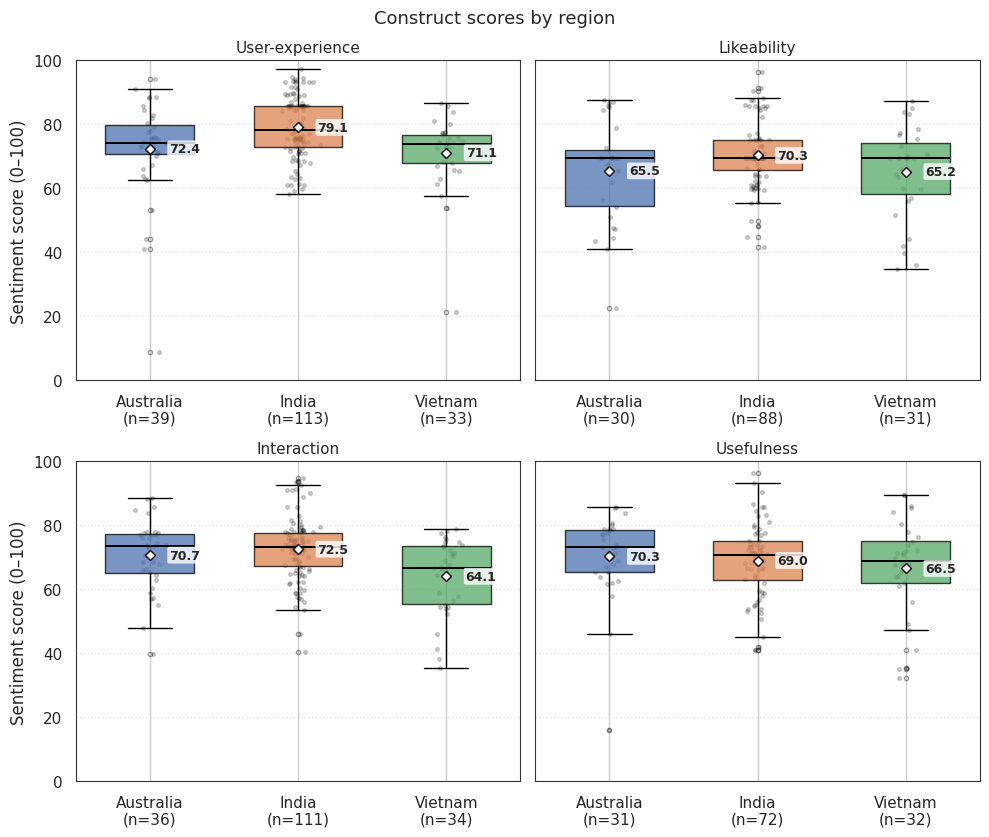

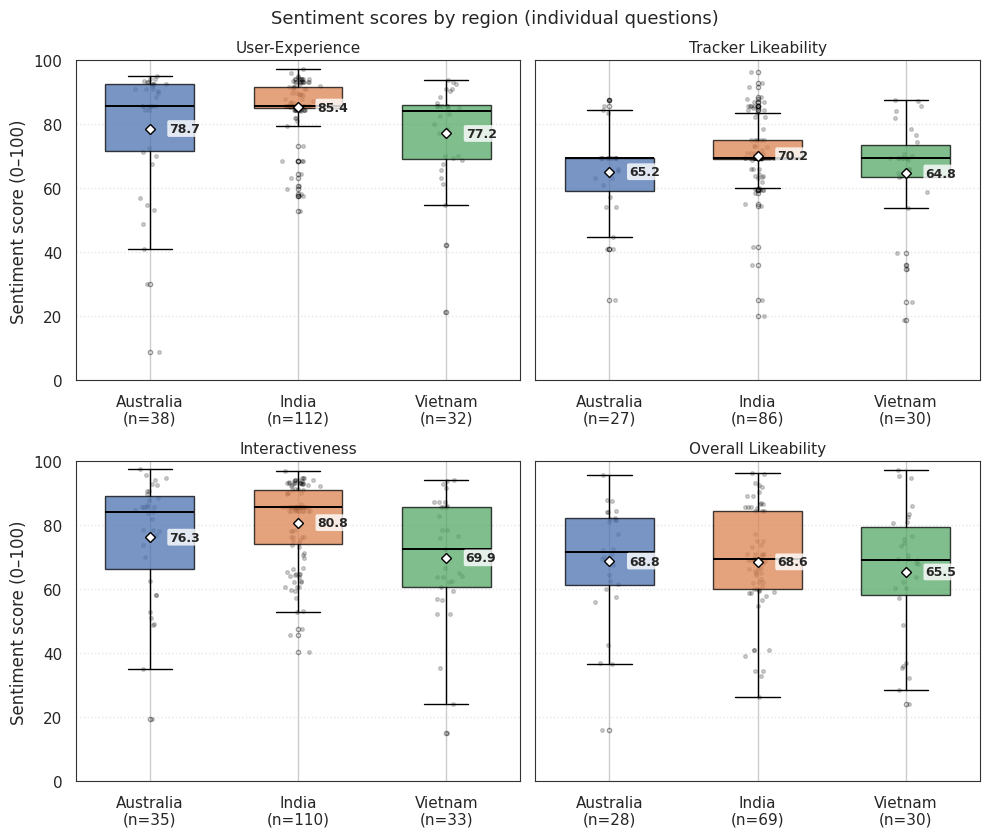

In [36]:
# Regions with enough respondents (also used by 5.8 and Part 6).
regions_present = [r for r in region_order
                   if (df["Region"] == r).sum() >= CONFIG["min_group_n"]]


# box plots of `cols` by region, with each box's mean labelled
def regionBoxplots(frame, cols, title, fname, ncols=2):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.25 * nrows),
                             sharey=True, squeeze=False)
    for ax, col in zip(axes.ravel(), cols):
        groups = [frame.loc[df["Region"] == r, col].dropna().values
                  for r in regions_present]
        bp = ax.boxplot(groups, patch_artist=True, showmeans=True, widths=0.6,
                        tick_labels=[f"{r}\n(n={len(g)})"
                                     for r, g in zip(regions_present, groups)],
                        medianprops=dict(color="black", linewidth=1.4),
                        meanprops=dict(marker="D", markerfacecolor="white",
                                       markeredgecolor="black", markersize=5),
                        flierprops=dict(marker="o", markersize=3, alpha=0.4))
        for patch, r in zip(bp["boxes"], regions_present):
            patch.set_facecolor(region_colors.get(r, "#999999"))
            patch.set_alpha(0.75)
        # Seeded jitter, so the figure is identical on every run.
        jit = np.random.default_rng(CONFIG["random_seed"])
        for i, g in enumerate(groups, start=1):
            ax.scatter(jit.normal(i, 0.05, len(g)), g, s=7, color="black", alpha=0.18)
        # Label the mean (white diamond) of each box.
        for i, g in enumerate(groups, start=1):
            if len(g):
                m = np.mean(g)
                ax.annotate(f"{m:.1f}", xy=(i, m), xytext=(14, 0),
                            textcoords="offset points", va="center", ha="left",
                            fontsize=9, fontweight="bold",
                            bbox=dict(boxstyle="round,pad=0.15", fc="white",
                                      ec="none", alpha=0.8))
        ax.set_title(labelOf(col), fontsize=11)
        ax.set_ylim(0, 100)
        ax.yaxis.grid(True, linestyle=":", alpha=0.5)
        ax.set_axisbelow(True)
    for ax in axes.ravel()[len(cols):]:          # hide unused panels
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel("Sentiment score (0–100)")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    saveFig(fname)
    plt.show()


# (a) WITH constructs — observed construct scores.
plot_constructs = ["User-experience", "Likeability", "Interaction", "Usefulness"]
regionBoxplots(constructs_obs, [construct_col_map[n] for n in plot_constructs],
                "Construct scores by region", "fig_08a_constructs_by_region")

# (b) WITHOUT constructs — individual questions, observed answers.
plot_items = ["QID12", "QID13_5", "QID21", "QID24"]
regionBoxplots(df_scores, plot_items,
                "Sentiment scores by region (individual questions)",
                "fig_08b_items_by_region")


Plotting: [('Interactiveness', 'QID21'), ('User-Experience', 'QID12'), ('Prototype Novelty', 'QID29'), ('Overall Likeability', 'QID24')]


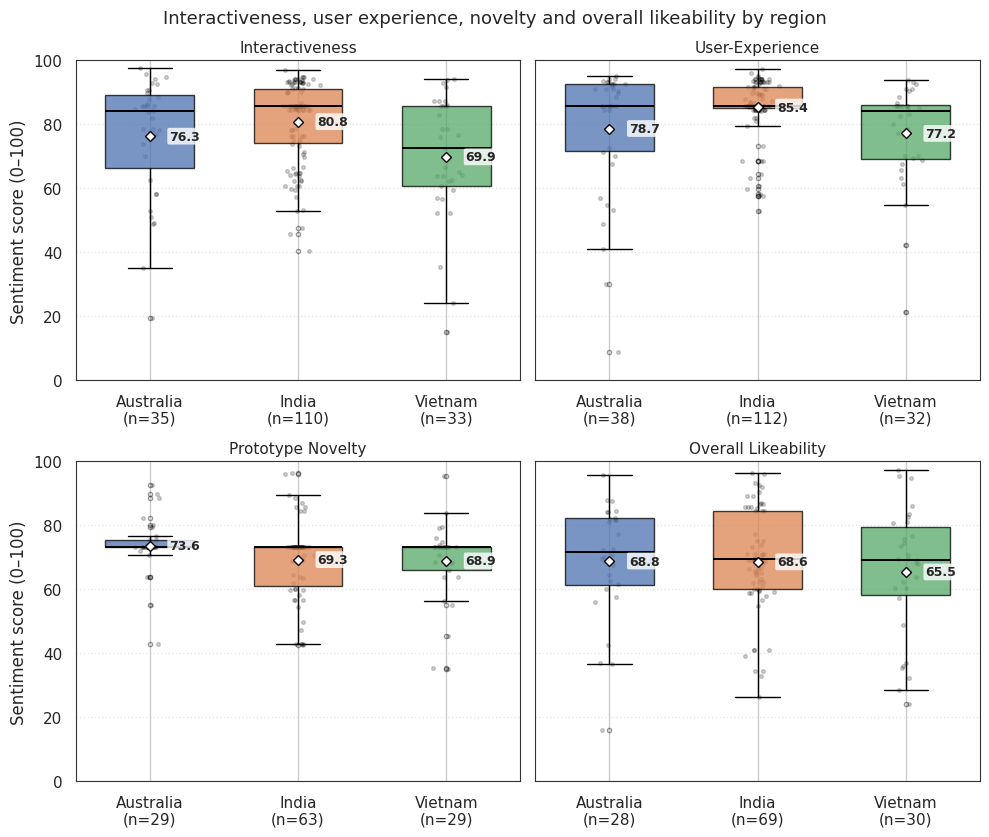

In [37]:
# Box plots by region: Interactiveness, User-Experience, Prototype Novelty, Overall Likeability
CONFIG["fig_formats"] = ("svg", "png")   # save as SVG and PNG
CONFIG["fig_dpi"] = 1000             # at 1000 dpi
plt.rcParams["svg.fonttype"] = "none"   # keep text editable in the SVG

wanted = ["Interactiveness", "User-Experience", "Prototype Novelty", "Overall Likeability"]

label_to_col = {labelOf(c).strip().lower(): c for c in df_scores.columns}
sel_cols = []
for w in wanted:
    col = label_to_col.get(w.lower())
    if col is None:
        print(f"Not found: {w!r} — check its label with labelOf()")
    else:
        sel_cols.append(col)

print("Plotting:", [(labelOf(c), c) for c in sel_cols])
regionBoxplots(df_scores, sel_cols,
                "Interactiveness, user experience, novelty and overall likeability by region",
                "fig_08c_selected_items_by_region", ncols=2)

### 5.7 Correlations

Spearman's ρ on the observed answers with pairwise deletion, for the individual
questions and for the construct scores. Expertise and prior exposure are coded 0/1;
region is not ordered and is left out. * marks p < .05 (uncorrected, exploratory).


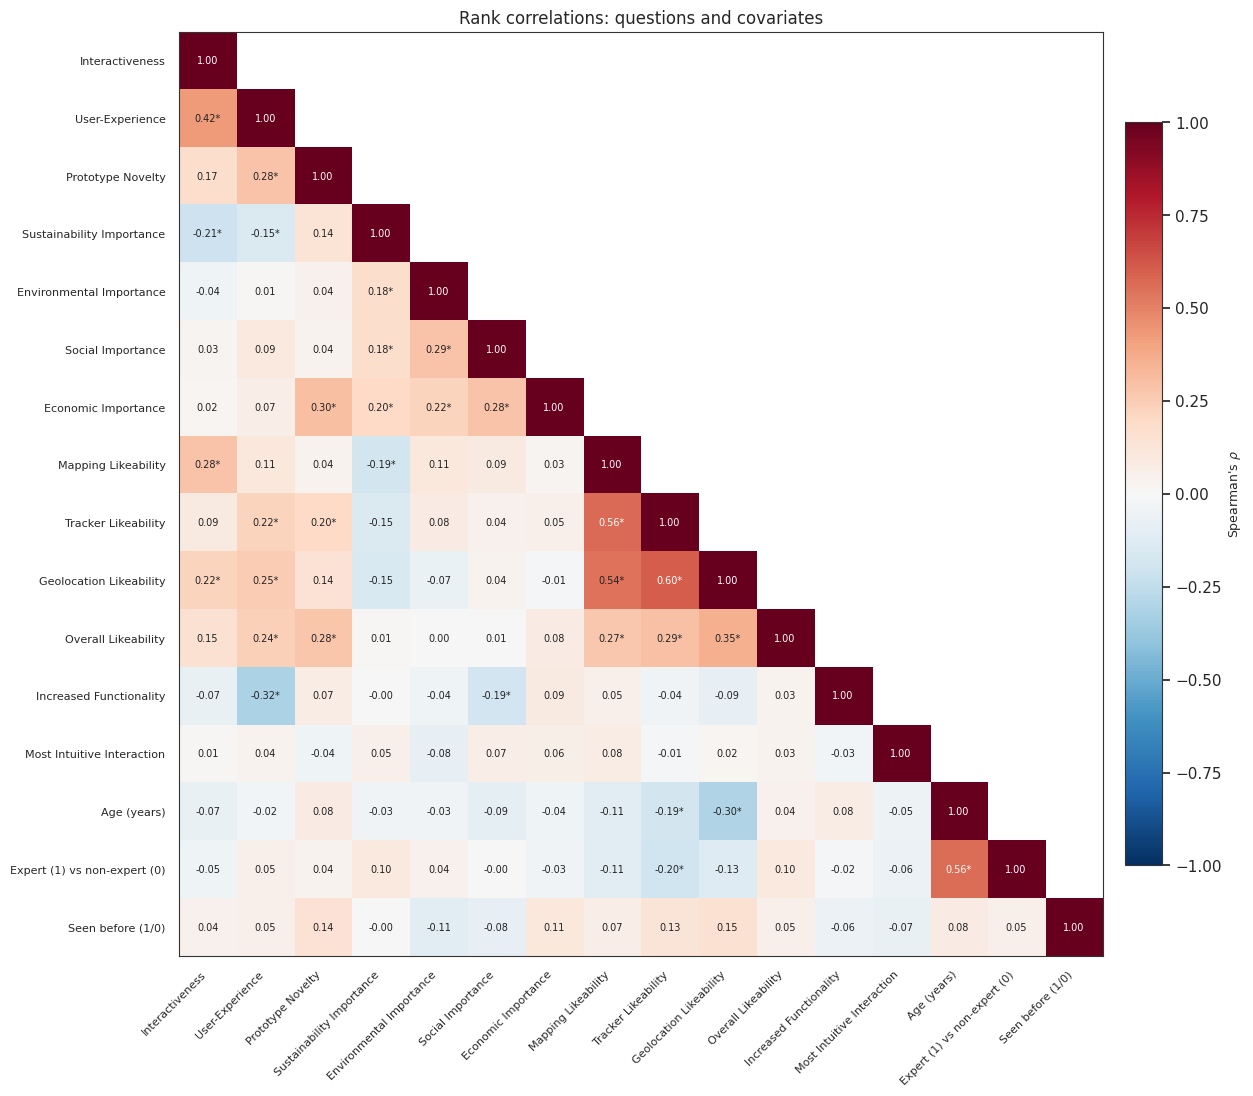

  saved -> tables/table_09a_spearman_items.csv


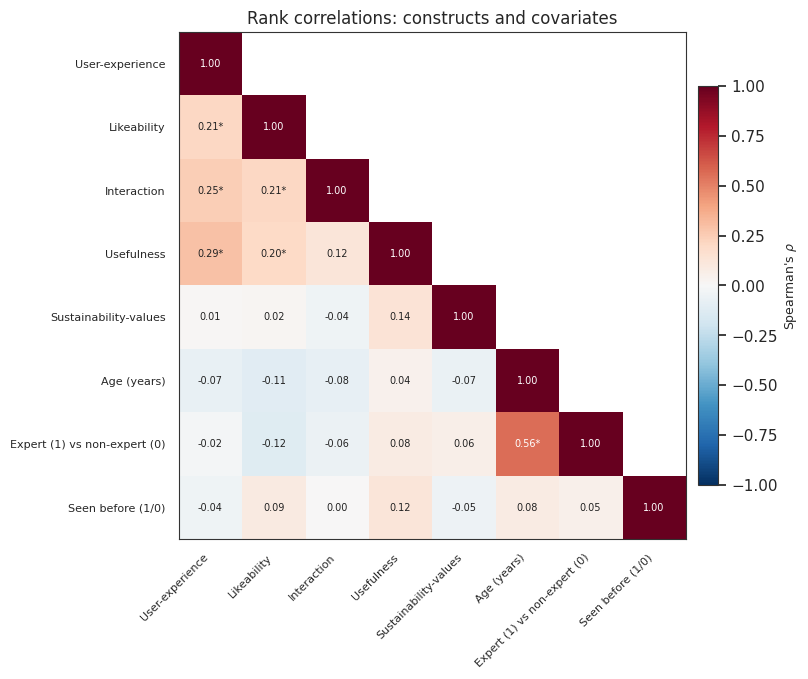

  saved -> tables/table_09b_spearman_constructs.csv


In [38]:
covariates = pd.DataFrame({
    "Age": df["Age"].astype(float),
    "Occupation_code": df["Occupation"].map({"Expert": 1, "Non-expert": 0}),
    "Seen_code": df["Seen"].map({"YES": 1, "NO": 0}),
}, index=df.index)
question_labels.setdefault("Occupation_code", "Expert (1) vs non-expert (0)")
question_labels.setdefault("Seen_code", "Seen before (1/0)")


# pairwise Spearman correlations on observed data, lower triangle
def spearmanHeatmap(frame, cols, title, fname):
    data = frame[cols].apply(pd.to_numeric, errors="coerce")
    k = len(cols)
    rho = np.full((k, k), np.nan)
    pval = np.full((k, k), np.nan)
    nobs = np.zeros((k, k), dtype=int)
    for a in range(k):
        for b in range(k):
            pair = data.iloc[:, [a, b]].dropna()
            nobs[a, b] = len(pair)
            if a == b:
                rho[a, b] = 1.0
            elif len(pair) >= 5 and pair.nunique().min() > 1:
                rho[a, b], pval[a, b] = stats.spearmanr(pair.iloc[:, 0], pair.iloc[:, 1])
    labels = [labelOf(c) for c in cols]
    corr = pd.DataFrame(rho, index=labels, columns=labels)
    plotted = corr.mask(np.triu(np.ones_like(rho, dtype=bool), k=1))

    fig, ax = plt.subplots(figsize=(0.62 * k + 3.2, 0.55 * k + 2.6))
    im = ax.imshow(plotted, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
    for a in range(k):
        for b in range(k):
            v = plotted.iloc[a, b]
            if pd.notna(v):
                star = "*" if a != b and pd.notna(pval[a, b]) and pval[a, b] < 0.05 else ""
                ax.text(b, a, f"{v:.2f}{star}", ha="center", va="center", fontsize=7,
                        color="white" if abs(v) > 0.55 else "#222222")
    ax.set_xticks(range(k))
    ax.set_yticks(range(k))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)
    ax.grid(False)
    cbar = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
    cbar.set_label(r"Spearman's $\rho$", fontsize=9)
    ax.set_title(title, fontsize=12)
    plt.tight_layout()
    saveFig(fname)
    plt.show()

    long = pd.DataFrame([{"Variable 1": labels[a], "Variable 2": labels[b],
                          "rho": round(rho[a, b], 3),
                          "p": round(pval[a, b], 4) if pd.notna(pval[a, b]) else np.nan,
                          "n": int(nobs[a, b])}
                         for a in range(k) for b in range(a)])
    saveTable(long, fname.replace("fig_", "table_"))
    return corr


cov_cols = ["Age", "Occupation_code", "Seen_code"]

# (a) WITHOUT constructs — individual questions.
items_frame = pd.concat([df_scores, covariates], axis=1)
corr_items = spearmanHeatmap(items_frame, rank_cols + cov_cols,
                              "Rank correlations: questions and covariates",
                              "fig_09a_spearman_items")

# (b) WITH constructs — construct scores.
constructs_frame = pd.concat([obs_scores, covariates], axis=1)
corr_constructs = spearmanHeatmap(constructs_frame, construct_cols + cov_cols,
                                   "Rank correlations: constructs and covariates",
                                   "fig_09b_spearman_constructs")


### 5.8 Sensitivity checks

**(a) Parametric equivalent.** Welch's one-way ANOVA on the observed scores. We use
Welch's test because Levene's test (5.1) showed unequal variances and group sizes
differ (India n = 133, Vietnam n = 35).


In [39]:
# welch's heteroscedastic one-way ANOVA. Returns (F, df1, df2, p)
def welchAnova(*groups):
    groups = [np.asarray(g, float) for g in groups]
    k = len(groups)
    n = np.array([len(g) for g in groups], float)
    m = np.array([g.mean() for g in groups])
    v = np.array([g.var(ddof=1) for g in groups])
    if np.any(v == 0):
        return np.nan, k - 1, np.nan, np.nan
    w = n / v
    mw = (w * m).sum() / w.sum()
    tmp = (((1 - w / w.sum()) ** 2) / (n - 1)).sum()
    F = ((w * (m - mw) ** 2).sum() / (k - 1)) / (1 + 2 * (k - 2) / (k ** 2 - 1) * tmp)
    df2 = (k ** 2 - 1) / (3 * tmp)
    return F, k - 1, df2, float(stats.f.sf(F, k - 1, df2))


para_rows = []
for col in rank_cols:
    groups = [observed.loc[observed["Region"] == r, col].dropna().values
              for r in regions_present]
    if any(len(g) < 2 for g in groups):
        continue
    F, df1, df2, p_welch = welchAnova(*groups)
    H, p_kw = stats.kruskal(*groups)
    para_rows.append({
        "Item": labelOf(col),
        "n observed": int(sum(len(g) for g in groups)),
        "Welch F": round(float(F), 3), "df": f"{df1}, {df2:.1f}",
        "Welch p": round(float(p_welch), 4),
        "KW H": round(float(H), 3), "KW p": round(float(p_kw), 4),
        "Agree at alpha=.05": "yes" if (p_welch < 0.05) == (p_kw < 0.05) else "NO",
    })
parametric = pd.DataFrame(para_rows)
print("Welch ANOVA vs Kruskal-Wallis on observed scores, by region "
      "(uncorrected p, for comparability)")
print(parametric.to_string(index=False))
disagree = int((parametric["Agree at alpha=.05"] == "NO").sum())
print(f"\nDisagreements: {disagree} of {len(parametric)}")
saveTable(parametric, "table_16_parametric_sensitivity")


Welch ANOVA vs Kruskal-Wallis on observed scores, by region (uncorrected p, for comparability)
                      Item  n observed  Welch F      df  Welch p   KW H   KW p Agree at alpha=.05
           Interactiveness         178    5.043 2, 54.7   0.0098  7.860 0.0196                yes
           User-Experience         182    5.433 2, 51.6   0.0072  8.660 0.0132                yes
         Prototype Novelty         121    2.054 2, 62.2   0.1368  4.306 0.1161                yes
 Sustainability Importance         212    0.091 2, 77.2   0.9131  0.373 0.8300                yes
  Environmental Importance         212    1.343 2, 71.6   0.2677  3.986 0.1363                yes
         Social Importance         212    0.740 2, 72.6   0.4805  1.337 0.5125                yes
       Economic Importance         212    1.177 2, 72.4   0.3141  2.208 0.3316                yes
       Mapping Likeability         148    1.693 2, 51.9   0.1939  2.544 0.2802                yes
       Tracker Likeabil

,Item,n observed,Welch F,df,Welch p,KW H,KW p,Agree at alpha=.05
0,Interactiveness,178,5.043,"2, 54.7",0.0098,7.860,0.0196,yes
1,User-Experience,182,5.433,"2, 51.6",0.0072,8.660,0.0132,yes
2,Prototype Novelty,121,2.054,"2, 62.2",0.1368,4.306,0.1161,yes
3,Sustainability Importance,212,0.091,"2, 77.2",0.9131,0.373,0.8300,yes
4,Environmental Importance,212,1.343,"2, 71.6",0.2677,3.986,0.1363,yes
5,Social Importance,212,0.740,"2, 72.6",0.4805,1.337,0.5125,yes
6,Economic Importance,212,1.177,"2, 72.4",0.3141,2.208,0.3316,yes
7,Mapping Likeability,148,1.693,"2, 51.9",0.1939,2.544,0.2802,yes
8,Tracker Likeability,143,2.065,"2, 48.7",0.1378,4.564,0.1021,yes
9,Geolocation Likeability,153,7.102,"2, 48.2",0.0020,10.270,0.0059,yes


**(b) Effect of the missing-data method.** The regional comparison using available
cases (primary), pooled multiple imputation, and complete cases only. Agreement
between the three indicates that the missing data do not drive the result.


In [40]:
listwise = available.dropna(subset=rank_cols)
print(f"Complete cases (all {len(rank_cols)} items answered): "
      f"{len(listwise)} of {len(available)}")

methods = {
    "available": groupComparison(available, rank_cols, "Region", region_order)[0],
    "MI": groupComparisonMi(mi_full, rank_cols, "Region", region_order)[0],
    "complete": groupComparison(listwise, rank_cols, "Region", region_order)[0],
}
padj = f"p ({CONFIG['correction']})"
merged = None
for name, res in methods.items():
    if res.empty:
        print(f"{name}: too few cases per region to test.")
        continue
    part = res[["Variable", padj, "Effect size"]].rename(
        columns={padj: f"p adj ({name})", "Effect size": f"effect ({name})"})
    merged = part if merged is None else merged.merge(part, on="Variable", how="left")

if merged is not None:
    sig = merged[[c for c in merged.columns if c.startswith("p adj")]] < CONFIG["alpha"]
    merged["Methods agree"] = np.where(sig.nunique(axis=1) == 1, "yes", "NO")
    print("\nRegional comparison under three missing-data methods "
          f"({CONFIG['correction']}-adjusted p)")
    print(merged.to_string(index=False))
    n_diff = int((merged["Methods agree"] == "NO").sum())
    print(f"\nConclusions differ for {n_diff} of {len(merged)} items.")
    if (methods["complete"].empty is False) and len(listwise) < 60:
        print("Note: the complete-case column rests on very few people; weight it "
              "least.")
    saveTable(merged, "table_17_missing_data_sensitivity")


Complete cases (all 13 items answered): 96 of 212

Regional comparison under three missing-data methods (holm-adjusted p)
                  Variable  p adj (available)  effect (available)  p adj (MI)  effect (MI)  p adj (complete)  effect (complete) Methods agree
           Interactiveness             0.2161               0.044      0.6694        0.032            1.0000              0.039           yes
           User-Experience             0.1580               0.048      0.7140        0.033            0.3568              0.076           yes
         Prototype Novelty             1.0000               0.036      1.0000        0.012            1.0000              0.033           yes
 Sustainability Importance             1.0000               0.002      1.0000        0.002            1.0000              0.006           yes
  Environmental Importance             1.0000               0.019      1.0000        0.019            0.9619              0.053           yes
         Social Importance

## Part 6 — Dimension reduction (exploratory)

We check whether the items reflect fewer underlying dimensions. This part uses
`df_mice_full` (the average of the imputed datasets), which is acceptable for
exploration but slightly overstates correlations for heavily imputed items.

### 6.1 Suitability for factor analysis

Bartlett's test of sphericity, the Kaiser–Meyer–Olkin (KMO) measure, and the
sample-size ratio.


In [41]:
X = df_mice_full[rank_cols].apply(pd.to_numeric, errors="coerce")
X_scaled = StandardScaler().fit_transform(X)
n_obs, n_items = X.shape

print(f"n = {n_obs} respondents, {n_items} items "
      f"({n_obs / n_items:.1f} cases per item)")
print("Rules of thumb ask for at least 5-10 cases per item and n >= 100 overall.")

kmo_total = None
if HAS_FA:
  try:
    chi2_b, p_b = calculate_bartlett_sphericity(X)
    kmo_per_item, kmo_total = calculate_kmo(X)
    print(f"\nBartlett's test of sphericity: chi2 = {chi2_b:.1f}, p = {p_b:.4g}")
    print("  (p < .05 means the correlation matrix differs from the identity, "
          "i.e. there are correlations worth factoring.)")
    print(f"KMO overall = {kmo_total:.3f}")
    print("  (>=.80 excellent, .70-.79 good, .60-.69 mediocre, <.60 unacceptable.)")
    kmo_items = pd.DataFrame({
        "Item": [labelOf(c) for c in rank_cols],
        "KMO": np.round(kmo_per_item, 3),
    }).sort_values("KMO")
    print("\nPer-item KMO (low values are candidates for removal):")
    print(kmo_items.to_string(index=False))
    saveTable(kmo_items, "table_18_kmo")
    if kmo_total < 0.60:
        print("\n  WARNING: KMO below .60. Factor analysis is not supported on this "
              "data; treat Part 6 as exploratory only and do not build scores from it.")
  except TypeError as exc:
    print(f"KMO / Bartlett skipped: factor_analyzer is incompatible with the "
          f"installed scikit-learn ({exc}). See the note in section 6.3.")
else:
    print("\nfactor_analyzer not installed — cannot compute KMO or Bartlett's test.")
    print("  pip install factor_analyzer")
    print("  These are prerequisites, not optional extras: without them there is no "
          "evidence the item set is factorable.")

n = 212 respondents, 13 items (16.3 cases per item)
Rules of thumb ask for at least 5-10 cases per item and n >= 100 overall.

factor_analyzer not installed — cannot compute KMO or Bartlett's test.
  pip install factor_analyzer
  These are prerequisites, not optional extras: without them there is no evidence the item set is factorable.


### 6.2 Principal component analysis

PCA with explained variance per component.


In [42]:
pca = PCA(random_state=CONFIG["random_seed"])
pca.fit(X_scaled)

variance = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
    "Eigenvalue": np.round(pca.explained_variance_, 3),
    "% variance": np.round(100 * pca.explained_variance_ratio_, 1),
    "Cumulative %": np.round(100 * np.cumsum(pca.explained_variance_ratio_), 1),
})
print("Variance explained")
print(variance.to_string(index=False))

n_kaiser = int((pca.explained_variance_ > 1).sum())
n_80 = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.80) + 1)
print(f"\nComponents to retain: {n_kaiser} by Kaiser's criterion (eigenvalue > 1), "
      f"{n_80} to reach 80% cumulative variance.")
saveTable(variance, "table_19_pca_variance")

Variance explained
Component  Eigenvalue  % variance  Cumulative %
      PC1       2.968        22.7          22.7
      PC2       1.815        13.9          36.6
      PC3       1.251         9.6          46.2
      PC4       1.088         8.3          54.5
      PC5       1.040         8.0          62.5
      PC6       1.014         7.8          70.3
      PC7       0.731         5.6          75.9
      PC8       0.697         5.3          81.2
      PC9       0.602         4.6          85.8
     PC10       0.592         4.5          90.3
     PC11       0.494         3.8          94.1
     PC12       0.400         3.1          97.2
     PC13       0.368         2.8         100.0

Components to retain: 6 by Kaiser's criterion (eigenvalue > 1), 8 to reach 80% cumulative variance.
  saved -> tables/table_19_pca_variance.csv


,Component,Eigenvalue,% variance,Cumulative %
0,PC1,2.968,22.7,22.7
1,PC2,1.815,13.9,36.6
2,PC3,1.251,9.6,46.2
3,PC4,1.088,8.3,54.5
4,PC5,1.040,8.0,62.5
5,PC6,1.014,7.8,70.3
6,PC7,0.731,5.6,75.9
7,PC8,0.697,5.3,81.2
8,PC9,0.602,4.6,85.8
9,PC10,0.592,4.5,90.3


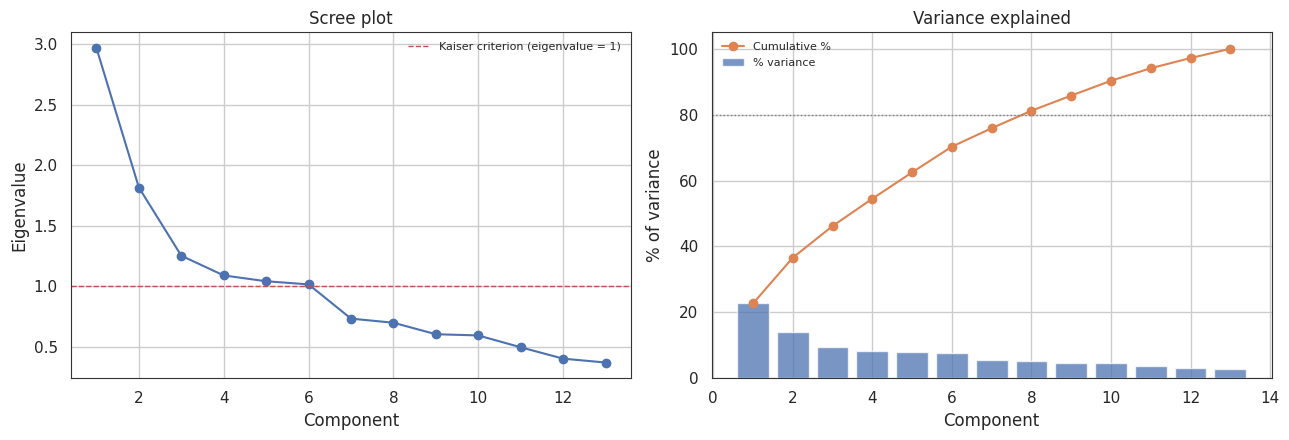

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, len(variance) + 1), variance["Eigenvalue"], "o-",
             color="#4C72B0")
axes[0].axhline(1, color="#C44E52", linestyle="--", lw=1,
                label="Kaiser criterion (eigenvalue = 1)")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Eigenvalue")
axes[0].set_title("Scree plot")
axes[0].legend(frameon=False, fontsize=8)

axes[1].bar(range(1, len(variance) + 1), variance["% variance"], color="#4C72B0",
            alpha=0.75, label="% variance")
axes[1].plot(range(1, len(variance) + 1), variance["Cumulative %"], "o-",
             color="#DD8452", label="Cumulative %")
axes[1].axhline(80, color="grey", linestyle=":", lw=1)
axes[1].set_xlabel("Component")
axes[1].set_ylabel("% of variance")
axes[1].set_title("Variance explained")
axes[1].legend(frameon=False, fontsize=8)

plt.tight_layout()
saveFig("fig_10_pca_scree")
plt.show()

In [44]:
# Loadings for the retained components.
n_keep = max(n_kaiser, 2)
loadings_pca = pd.DataFrame(
    pca.components_[:n_keep].T,
    index=[labelOf(c) for c in rank_cols],
    columns=[f"PC{i+1}" for i in range(n_keep)],
)
print(f"PCA loadings, first {n_keep} components "
      f"(|loading| > {CONFIG['threshold']} marked *)")
annotated = loadings_pca.round(2).astype(str)
for c in loadings_pca.columns:
    strong = loadings_pca[c].abs() > CONFIG["threshold"]
    annotated.loc[strong, c] = annotated.loc[strong, c] + "*"
print(annotated.to_string())
saveTable(loadings_pca.round(3).reset_index(), "table_20_pca_loadings")

PCA loadings, first 6 components (|loading| > 0.4 marked *)
                              PC1    PC2    PC3    PC4    PC5    PC6
Interactiveness              0.38  -0.06    0.1  -0.31   0.21  -0.36
User-Experience             0.41*   0.01    0.2  -0.39  -0.06  -0.24
Prototype Novelty            0.33   0.18  0.45*   0.12  -0.27  -0.09
Sustainability Importance     0.0  0.46*   0.12   0.14  -0.19  0.42*
Environmental Importance     0.13  0.44*  -0.36   0.07  -0.15  -0.11
Social Importance            0.13  0.46*  -0.35  -0.14   0.25   0.07
Economic Importance          0.09   0.5*   0.14   0.06   0.12  -0.19
Mapping Likeability          0.35  -0.17  -0.39   0.22   0.27    0.1
Tracker Likeability          0.39  -0.11  -0.29   0.17  -0.11   0.03
Geolocation Likeability      0.4*   -0.2  -0.13   0.13  -0.04    0.2
Overall Likeability           0.3  -0.09   0.28   0.34  -0.22   0.28
Increased Functionality     -0.05   0.04   0.19  0.67*  0.45*  -0.4*
Most Intuitive Interaction    0.1   0.04   

,index,PC1,PC2,PC3,PC4,PC5,PC6
0,Interactiveness,0.381,-0.059,0.097,-0.310,0.212,-0.365
1,User-Experience,0.410,0.014,0.204,-0.390,-0.058,-0.238
2,Prototype Novelty,0.332,0.177,0.453,0.117,-0.268,-0.089
3,Sustainability Importance,0.003,0.460,0.118,0.141,-0.190,0.415
4,Environmental Importance,0.133,0.441,-0.360,0.072,-0.152,-0.108
5,Social Importance,0.128,0.462,-0.349,-0.142,0.251,0.072
6,Economic Importance,0.094,0.501,0.135,0.057,0.123,-0.193
7,Mapping Likeability,0.345,-0.174,-0.389,0.220,0.275,0.105
8,Tracker Likeability,0.387,-0.109,-0.285,0.173,-0.110,0.035
9,Geolocation Likeability,0.400,-0.200,-0.128,0.130,-0.038,0.201


### 6.3 Exploratory factor analysis

Varimax-rotated factor analysis, which gives more interpretable loadings than
unrotated components.


In [45]:
fa = None
loadings = None
if not HAS_FA:
    print("factor_analyzer not installed — skipping EFA.")
else:
    try:
        fa = FactorAnalyzer(n_factors=CONFIG["n_factors"], rotation="varimax")
        fa.fit(X)
    except TypeError as exc:
        # factor_analyzer <= 0.5.x calls check_array(force_all_finite=...), which
        # scikit-learn renamed to ensure_all_finite in 1.6 and removed in 1.8.
        # Nothing here is wrong with the data — the two libraries disagree.
        print(f"EFA skipped: factor_analyzer is incompatible with the installed "
              f"scikit-learn ({exc}).")
        print("  Fix with either:")
        print("    pip install -U factor_analyzer      # once it supports sklearn >= 1.8")
        print("    pip install 'scikit-learn<1.6'      # pin back instead")
        fa = None

if fa is not None:

    loadings = pd.DataFrame(
        fa.loadings_,
        index=[labelOf(c) for c in rank_cols],
        columns=[f"Factor{i+1}" for i in range(CONFIG["n_factors"])],
    )
    ev, cv = fa.get_factor_variance()[1:]
    print("Rotated factor loadings")
    print(loadings.round(3).to_string())
    print("\nVariance explained per factor: "
          + ", ".join(f"Factor{i+1} {100*v:.1f}%" for i, v in enumerate(ev)))
    print(f"Cumulative: {100 * cv[-1]:.1f}%")

    # Communalities: how much of each item is captured by the retained factors.
    comm = pd.DataFrame({
        "Item": [labelOf(c) for c in rank_cols],
        "Communality": np.round(fa.get_communalities(), 3),
    }).sort_values("Communality")
    print("\nCommunalities (low = the item is barely explained by these factors):")
    print(comm.to_string(index=False))

    saveTable(loadings.round(3).reset_index(), "table_21_factor_loadings")
    saveTable(comm, "table_22_communalities")

    plt.figure(figsize=(7, 6))
    sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, linewidths=0.4, linecolor="white",
                cbar_kws={"label": "Loading"})
    plt.xlabel("")
    plt.ylabel("")
    plt.title(f"Varimax-rotated factor loadings ({CONFIG['n_factors']} factors)")
    plt.yticks(rotation=0)
    plt.tight_layout()
    saveFig("fig_11_factor_loadings")
    plt.show()

factor_analyzer not installed — skipping EFA.


### 6.4 Empirical factors vs a priori constructs

Each item is assigned to the factor it loads on most strongly, and this grouping
is compared with the questionnaire-based constructs.


In [46]:
if loadings is not None:
    rev_label = {labelOf(c): c for c in rank_cols}
    apriori = {item: name for name, items in constructs.items() for item in items}
    rows = []
    for item_label in loadings.index:
        col = rev_label[item_label]
        best = loadings.loc[item_label].abs().idxmax()
        rows.append({
            "Item": item_label,
            "A priori construct": apriori.get(col, "unassigned"),
            "Dominant factor": best,
            "Loading": round(float(loadings.loc[item_label, best]), 3),
            "Strong?": "yes" if abs(loadings.loc[item_label, best])
                       > CONFIG["threshold"] else "no",
        })
    alignment = pd.DataFrame(rows).sort_values(["Dominant factor", "Loading"])
    print("A priori constructs vs empirical factor structure")
    print(alignment.to_string(index=False))

    crosstab = pd.crosstab(alignment["A priori construct"],
                           alignment["Dominant factor"])
    print("\nCross-tabulation:")
    print(crosstab.to_string())
    n_weak = int((alignment["Strong?"] == "no").sum())
    print(f"\n{n_weak} of {len(alignment)} items do not load strongly on any factor "
          f"(|loading| <= {CONFIG['threshold']}).")
    saveTable(alignment, "table_23_construct_factor_alignment")

### 6.5 Factor scores and group comparisons

Factor scores are estimated with `fa.transform()` (regression method) and compared
across groups.


In [47]:
if loadings is not None:
    scores = fa.transform(X)
    factor_cols = []
    for i in range(CONFIG["n_factors"]):
        col = f"Factor{i+1}_score"
        df_mice_full[col] = scores[:, i]
        question_labels[col] = f"Factor {i+1} score"
        factor_cols.append(col)

    print("Factor scores")
    print(df_mice_full[factor_cols].describe().round(3).to_string())

    for gvar in grouping_vars:
        order = {"Region": region_order, "Gender": gender_order,
                 "Occupation": expert_order, "Seen": seen_order,
                 "AgeRange": age_order}[gvar]
        res, dropped = groupComparison(df_mice_full, factor_cols, gvar, order)
        if res.empty:
            continue
        print(f"\nFactor scores by {labelOf(gvar)}")
        if dropped:
            print(f"Excluded (n < {CONFIG['min_group_n']}): "
                  + ", ".join(f"{g} (n={n})" for g, n in dropped))
        show = [c for c in res.columns if not c.endswith("(n)")]
        print(res[show].to_string(index=False))
        saveTable(res, f"table_24_factor_scores_by_{gvar}")

### 6.6 Kernel PCA (exploratory only)

Included for completeness. Kernel PCA has no loadings or explained variance in the
original item space, and its result depends on the untuned `gamma` (0.1), so we do
not interpret it further.


Item correlations with kernel components (gamma = 0.1) — descriptive, not loadings
                             KPC1   KPC2
Interactiveness             0.374 -0.467
User-Experience             0.340 -0.454
Prototype Novelty           0.073 -0.427
Sustainability Importance  -0.371 -0.112
Environmental Importance   -0.411 -0.263
Social Importance          -0.266 -0.169
Economic Importance        -0.239 -0.183
Mapping Likeability         0.046 -0.478
Tracker Likeability         0.069 -0.470
Geolocation Likeability     0.106 -0.479
Overall Likeability        -0.011 -0.438
Increased Functionality    -0.138  0.199
Most Intuitive Interaction -0.029  0.007


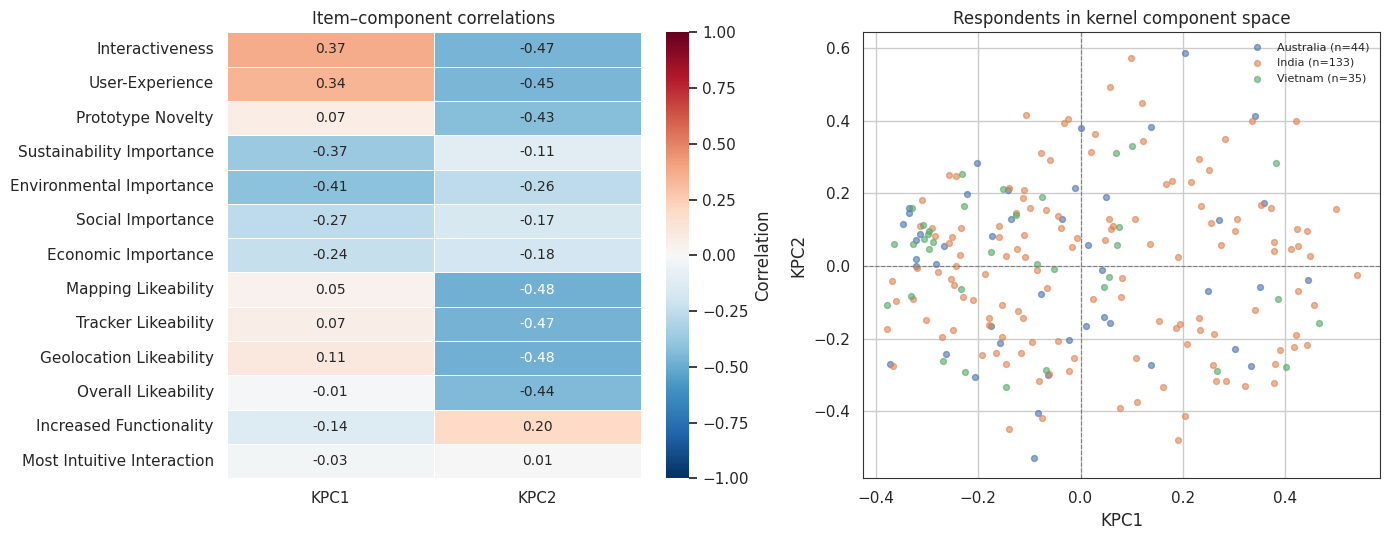

  saved -> tables/table_25_kpca_correlations.csv


,index,KPC1,KPC2
0,Interactiveness,0.374,-0.467
1,User-Experience,0.340,-0.454
2,Prototype Novelty,0.073,-0.427
3,Sustainability Importance,-0.371,-0.112
4,Environmental Importance,-0.411,-0.263
5,Social Importance,-0.266,-0.169
6,Economic Importance,-0.239,-0.183
7,Mapping Likeability,0.046,-0.478
8,Tracker Likeability,0.069,-0.470
9,Geolocation Likeability,0.106,-0.479


In [48]:
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=CONFIG["gamma"],
                 random_state=CONFIG["random_seed"])
X_kpca = kpca.fit_transform(X_scaled)

kpca_corr = pd.DataFrame(
    np.corrcoef(X_scaled.T, X_kpca.T)[:n_items, n_items:],
    index=[labelOf(c) for c in rank_cols],
    columns=["KPC1", "KPC2"],
)
print(f"Item correlations with kernel components (gamma = {CONFIG['gamma']}) — "
      "descriptive, not loadings")
print(kpca_corr.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(kpca_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=axes[0], linewidths=0.4, linecolor="white",
            cbar_kws={"label": "Correlation"})
axes[0].set_title("Item–component correlations")
axes[0].set_ylabel("")
axes[0].tick_params(axis="y", rotation=0)

for r in regions_present:
    m = df_mice_full["Region"] == r
    axes[1].scatter(X_kpca[m.values, 0], X_kpca[m.values, 1], s=18, alpha=0.6,
                    label=f"{r} (n={int(m.sum())})",
                    color=region_colors.get(r, "#999999"))
axes[1].axhline(0, color="grey", ls="--", lw=0.8)
axes[1].axvline(0, color="grey", ls="--", lw=0.8)
axes[1].set_xlabel("KPC1")
axes[1].set_ylabel("KPC2")
axes[1].set_title("Respondents in kernel component space")
axes[1].legend(frameon=False, fontsize=8)

plt.tight_layout()
saveFig("fig_12_kernel_pca")
plt.show()
saveTable(kpca_corr.round(3).reset_index(), "table_25_kpca_correlations")

## Part 7 — Qualitative analysis of open-ended answers

Each section checks for its optional packages and is skipped if they are missing.

### 7.1 Keyword extraction


Top keywords in Increased Functionality (121 responses, 194 content words)
  Keyword  Frequency
       vr         27
    table         17
     data         13
     view         10
    datum          8
    sound          7
  country          4
    place          3
      map          3
 location          2
    video          2
   google          2
   visual          2
    chart          2
       ai          2
    graph          2
  project          2
    sheet          2
component          1
      ios          1
    usage          1
  support          1
   oculus          1
   device          1
        w          1
  saved -> tables/table_26_keywords.csv


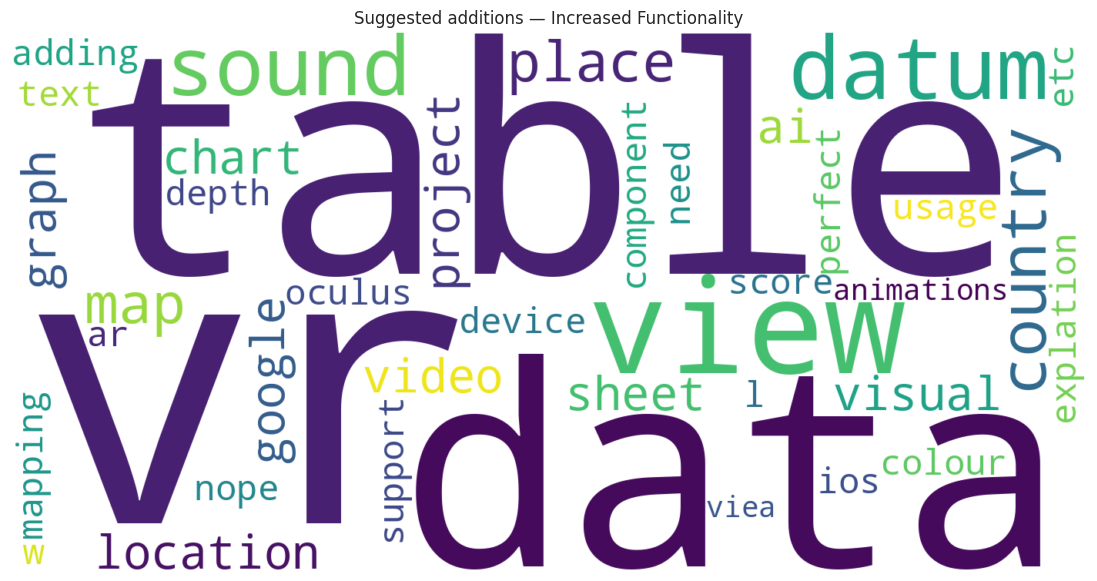

In [49]:
STOPWORD_EXTRAS = {
    "ok", "okay", "yeah", "yes", "no", "hi", "hello", "thanks", "thank",
    "welcome", "bye", "goodbye", "nice", "great", "amazing", "excellent",
    "bad", "good", "awesome", "fine", "nothing", "something", "thing",
    "stuff", "well", "interesting", "type", "multiple", "lot", "bit",
}
KEYWORD_SOURCE = "QID28"     # "what components would you add?"

if HAS_SPACY:
    from collections import Counter
    try:
        import spacy
        nlp = spacy.load("en_core_web_sm")
    except OSError:
        nlp = None
        print("spaCy is installed but the 'en_core_web_sm' model is not.")
        print("  python -m spacy download en_core_web_sm")

    if nlp is not None and KEYWORD_SOURCE in df.columns:
        texts = df[KEYWORD_SOURCE].dropna().astype(str)
        words = []
        for doc in nlp.pipe(texts, batch_size=64):     # pipe() is much faster
            for tok in doc:                            # than calling nlp() per row
                # PROPN is included and short upper-case tokens are kept, so
                # abbreviations such as "VR", "AR" and "3D" are not dropped.
                abbrev = tok.text.isupper() or tok.text.lower() in {"3d", "2d"}
                if (tok.pos_ in {"NOUN", "ADJ", "PROPN"} and not tok.is_stop
                        and (tok.is_alpha or abbrev)
                        and tok.lemma_.lower() not in STOPWORD_EXTRAS
                        and (len(tok.lemma_) > 2 or abbrev)):
                    words.append(tok.text.lower() if abbrev else tok.lemma_.lower())
        counts = Counter(words)
        keyword_table = pd.DataFrame(counts.most_common(25),
                                     columns=["Keyword", "Frequency"])
        print(f"Top keywords in {labelOf(KEYWORD_SOURCE)} "
              f"({len(texts)} responses, {len(words)} content words)")
        print(keyword_table.to_string(index=False))
        saveTable(keyword_table, "table_26_keywords")

        if HAS_WORDCLOUD and len(counts):
            from wordcloud import WordCloud
            wc = WordCloud(width=1400, height=700, background_color="white",
                           colormap="viridis",
                           random_state=CONFIG["random_seed"]) \
                .generate_from_frequencies(dict(counts.most_common(40)))
            plt.figure(figsize=(14, 7))
            plt.imshow(wc, interpolation="bilinear")
            plt.axis("off")
            plt.title(f"Suggested additions — {labelOf(KEYWORD_SOURCE)}")
            saveFig("fig_13_keyword_cloud")
            plt.show()
        elif not HAS_WORDCLOUD:
            print("\nwordcloud not installed — skipping the word cloud.")
else:
    print("spaCy not installed — skipping keyword extraction.")
    print("  pip install spacy && python -m spacy download en_core_web_sm")

### 7.1b Suggested new components (QID28) — experts vs non-experts

We code the answers to *"If you were to add new components to the prototypes,
what would they be?"* into technical features using the keyword dictionary
`TECH_FEATURES`. Each feature is counted once per person, and requests for more
data or information are not counted as features. Every coded answer is saved
(`table_26c_…`) so the coding can be checked.

Tests:

1. **Response rate** — Fisher's exact test on answered vs blank.
2. **Overall difference** — permutation test (10,000 shuffles of the expertise
   labels), because one person can request several features.
3. **Per feature** — Fisher's exact test with Benjamini–Hochberg correction.

The expert group is small, so only large differences can be detected.


Increased Functionality: 121 typed something, 29 of them a non-answer (e.g. 'No', 'Yes', 'Yes', 'Everything great', '.', "It's really nice"), 92 real suggestions.

Increased Functionality — who made a suggestion?
  Expert     : 12 of 22 answered (54.5%)
  Non-expert : 80 of 190 answered (42.1%)
  Fisher's exact test: p = 0.3637

Most common words NOT covered by any feature (review these; add any real features to TECH_FEATURES):
  view (11), google (2), addign (1), devices (1), viea (1), date (1), unnecessary (1), useful (1), multipersonal (1), look (1), detecting (1), digital (1), representation (1), people (1), especially (1), generations (1), attract (1), suitable (1), integration (1), original (1), course (1), time (1), final (1), outcome (1), afftect (1)

[keywords] answers naming at least one technical feature:
  Expert     : 12 of 12 (100.0%)
  Non-expert : 78 of 80 (97.5%)
  Fisher's exact test: p = 1.0000

[keywords] Overall difference in requested features (permutation test, 1

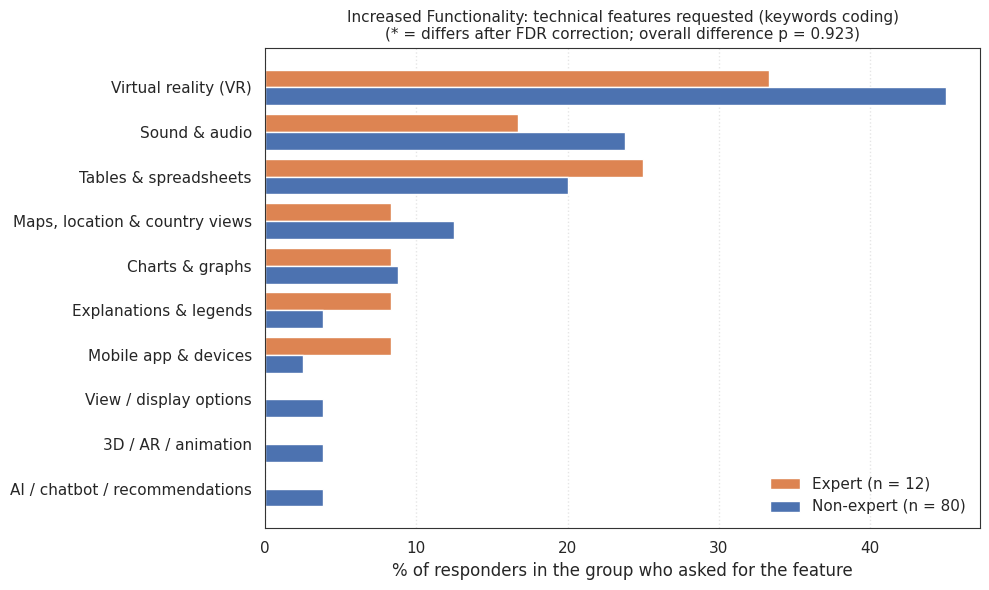

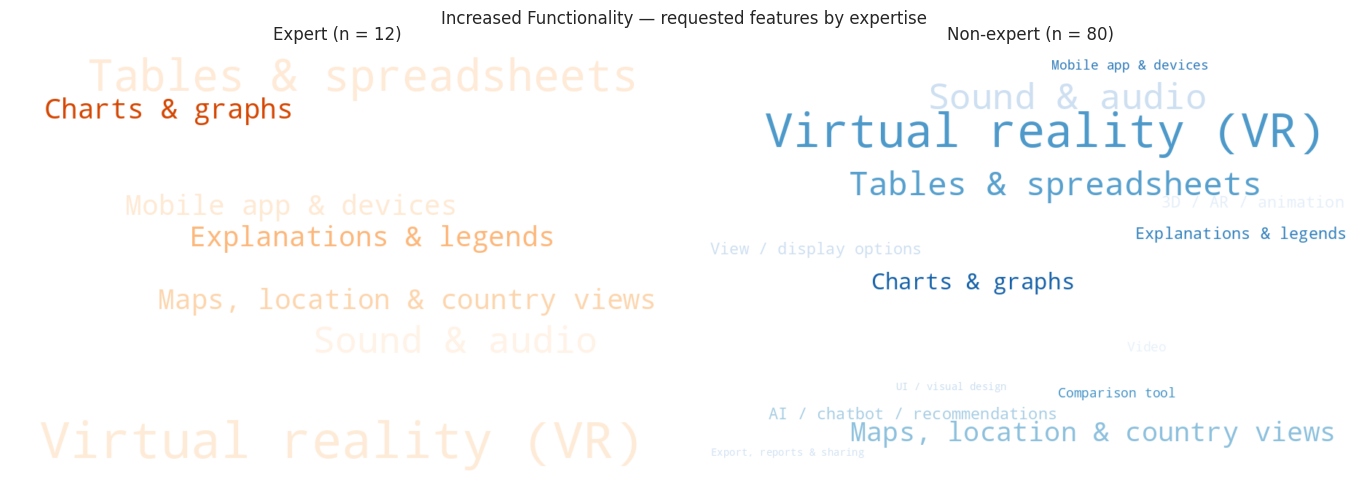

  saved -> tables/table_26c_coded_answers_QID28.csv

Example coded answers (full list saved to tables/):
Occupation                          QID28                             Features
Non-expert   Adding sounds will be better                        Sound & audio
Non-expert                       Using VR                 Virtual reality (VR)
    Expert                 More locations       Maps, location & country views
Non-expert                  Sounds and VR  Sound & audio; Virtual reality (VR)
Non-expert                         Sounds                        Sound & audio
Non-expert Addign a data table and sounds Sound & audio; Tables & spreadsheets
Non-expert                  Adding sounds                        Sound & audio
Non-expert               Video components                                Video
Non-expert                      ios usage                 Mobile app & devices
Non-expert          Adding more locations       Maps, location & country views


In [50]:
TEXT_ITEM = "QID28"                      # change to compare another open question
GROUP_VAR = "Occupation"
GROUPS = ["Expert", "Non-expert"]
MIN_MENTIONS = 3                         # features mentioned by fewer people are not tested

# Technical-feature coding scheme.
# Each answer is coded with every feature whose patterns it contains. Patterns
# are regular expressions matched at the START of a word, so "visuali" catches
# visualise / visualization, and "\b3d\b" only matches the whole token "3d".
# Data / content requests ("more data", "information") are deliberately NOT a
# feature. The "unclassified words"
# list printed below shows what is not yet covered.
TECH_FEATURES = {
    "Maps, location & country views": [r"maps?\b", r"mapping", r"gis\b", r"geo", r"spatial", r"satellite",
                                    r"heat ?maps?", r"locations?\b", r"places?\b",
                                    r"countr(?:y|ies)", r"regions?\b", r"cit(?:y|ies)\b"],
    "Tables & spreadsheets":       [r"tables?\b", r"tabular", r"spread ?sheets?",
                                    r"sheets?\b", r"csv\b", r"rows?\b", r"columns?\b"],
    # "view" alone is NOT used: in these answers it is almost always "data table
    # view", which belongs to Tables. Only explicit viewing modes count here.
    "View / display options":      [r"ways? to view", r"display", r"zoom", r"full ?screen",
                                    r"in depth\b", r"perspective", r"split ?screen"],
    "Sound & audio":               [r"sounds?\b", r"audio", r"music", r"voice",
                                    r"narrat", r"text to speech"],
    "Video":                       [r"videos?\b", r"clips?\b", r"movie"],
    "Charts & graphs":             [r"charts?\b", r"graphs?\b", r"graphical", r"plots?\b",
                                    r"visuali[sz]", r"visuals?\b", r"infographic", r"diagram",
                                    r"histogram", r"pie\b", r"statistic"],
    "Dashboard":                   [r"dashboard", r"overview panel", r"summary (?:view|page)"],
    "Virtual reality (VR)":        [r"vr\b", r"v\.r\.", r"virtual", r"immersive", r"headsets?\b",
                                    r"oculus", r"metaverse", r"quest\b"],
    "3D / AR / animation":         [r"3d\b", r"3-d\b", r"three.dimension", r"ar\b",
                                    r"augmented", r"holo", r"animat", r"simulat"],
    "Filtering & search":          [r"filter", r"search", r"sort", r"query", r"drill"],
    "Comparison tool":             [r"compar", r"benchmark", r"versus\b", r"side by side"],
    "Calculator / what-if scenarios": [r"calculat", r"scenario", r"what if", r"estimat",
                                    r"predict", r"forecast"],
    "Real-time / live updates":    [r"real ?time", r"live\b", r"sensors?\b", r"iot\b"],
    "AI / chatbot / recommendations": [r"ai\b", r"ml\b", r"artificial intelligence",
                                    r"chat ?bot", r"assistant", r"machine learning",
                                    r"recommend"],
    "Explanations & legends":      [r"expla", r"legend", r"lengend", r"descri",
                                    r"why the score"],
    "Export, reports & sharing":   [r"export", r"download", r"reports?\b", r"pdf\b",
                                    r"excel\b", r"csv\b", r"shar(?:e|ing)\b", r"print"],
    "Accounts & personalisation":  [r"log ?in\b", r"accounts?\b", r"profile", r"custom",
                                    r"personali[sz]", r"bookmark", r"save\b"],
    "Notifications & alerts":      [r"notif", r"alerts?\b", r"reminder"],
    "Mobile app & devices":        [r"mobile", r"apps?\b", r"android", r"ios\b",
                                    r"(?:smart)?phone", r"tablet"],
    "Tutorials & help":            [r"tutorial", r"guide", r"help\b", r"instruction",
                                    r"tool ?tips?", r"faq", r"onboarding"],
    "Gamification":                [r"gam(?:e|es|ing|if)", r"quiz", r"rewards?\b", r"badges?\b",
                                    r"leaderboard", r"points?\b"],
    "UI / visual design":          [r"dark mode", r"theme", r"colou?rs?\b", r"fonts?\b",
                                    r"layout", r"interface", r"ui\b", r"ux\b", r"navigat",
                                    r"menu", r"buttons?\b"],
    "Language & accessibility":    [r"languages?\b", r"translat", r"accessib",
                                    r"subtitle", r"captions?\b"],
    "Collaboration & community":   [r"social", r"community", r"forum", r"collaborat",
                                    r"discussion"],
}
FEATURE_RE = {f: re.compile(r"\b(?:" + "|".join(p) + ")", re.IGNORECASE)
              for f, p in TECH_FEATURES.items()}

# Words that are not features and not worth listing as "unclassified".
GENERIC = (set(__import__("sklearn.feature_extraction.text",
                          fromlist=["ENGLISH_STOP_WORDS"]).ENGLISH_STOP_WORDS)
           | STOPWORD_EXTRAS |
           {"add", "would", "like", "new", "component", "components", "maybe", "also",
            "think", "prototype", "prototypes", "tracker", "lcsa", "could", "should",
            "want", "include", "including", "etc", "na", "nil", "none", "dont", "don",
            "data", "information", "info", "details", "detail", "more", "better",
            "option", "options", "feature", "features", "tool", "tools", "function",
            "functions", "user", "users", "make", "easy", "easier", "use", "using",
            "datum", "nope", "perfect", "need", "needs", "adding", "added", "usage",
            "support", "good", "nothing", "yes", "project", "projects", "text",
            "really", "excellent", "interesting", "cool", "fun", "better", "would",
            "wud", "say", "definitely", "maybe", "probably", "thing", "thinking"})


# repair UTF-8 text that was decoded as Windows-1252 ('â€œ' -> '"')
def fixMojibake(text):
    t = str(text)
    if "Ã" in t or "â€" in t:
        try:
            return t.encode("cp1252").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return t


# true if the answer suggests nothing: 'No', 'Yes', 'Nice', '.', 'It is perfect'
def isNonAnswer(text):
    if codeFeatures(text):
        return False
    words = re.findall(r"[a-z]+", str(text).lower())
    return not any(len(w) >= 3 and w not in GENERIC for w in words)


# set of technical features mentioned in one answer
def codeFeatures(text):
    t = str(text)
    return {f for f, rx in FEATURE_RE.items() if rx.search(t)}


# content words in an answer that no feature pattern covers
def unclassifiedWords(text):
    t = str(text).lower()
    covered = [m.span() for rx in FEATURE_RE.values() for m in rx.finditer(t)]
    out = set()
    for m in re.finditer(r"[a-z]+", t):
        w = m.group()
        if len(w) > 2 and w not in GENERIC and \
                not any(a <= m.start() < b for a, b in covered):
            out.add(w)
    return out


answers = df.loc[df[GROUP_VAR].isin(GROUPS), [TEXT_ITEM, GROUP_VAR]].copy()
answers[TEXT_ITEM] = answers[TEXT_ITEM].where(answers[TEXT_ITEM].isna(),
                                              answers[TEXT_ITEM].map(fixMojibake))
typed = answers[TEXT_ITEM].notna() & answers[TEXT_ITEM].astype(str).str.strip().ne("")
non_answer = typed & answers[TEXT_ITEM].apply(isNonAnswer)
# "answered" = gave an actual suggestion. Typed non-answers ("No", "Nice", ".")
# are reported but not counted as suggestions, so they do not dilute the %s.
answers["answered"] = typed & ~non_answer
print(f"{labelOf(TEXT_ITEM)}: {int(typed.sum())} typed something, "
      f"{int(non_answer.sum())} of them a non-answer "
      f"(e.g. {', '.join(repr(t) for t in answers.loc[non_answer, TEXT_ITEM].head(6))}), "
      f"{int(answers['answered'].sum())} real suggestions.\n")

# Test 1: response rate
rate = pd.crosstab(answers[GROUP_VAR], answers["answered"]).reindex(
    index=GROUPS, columns=[True, False]).fillna(0).astype(int)
_, p_rate = stats.fisher_exact(rate.values)
print(f"{labelOf(TEXT_ITEM)} — who made a suggestion?")
for g in GROUPS:
    a, b = rate.loc[g, True], rate.loc[g, False]
    print(f"  {g:<11}: {a} of {a + b} answered ({pct(a, a + b)}%)")
print(f"  Fisher's exact test: p = {p_rate:.4f}")

# Code every answer
resp = answers[answers["answered"]].copy()
resp["features"] = resp[TEXT_ITEM].apply(codeFeatures)
# Coverage check: what is left uncoded?
left = Counter(w for s in resp[TEXT_ITEM].apply(unclassifiedWords) for w in s)
print("\nMost common words NOT covered by any feature (review these; add any real "
      "features to TECH_FEATURES):")
print("  " + ", ".join(f"{w} ({n})" for w, n in left.most_common(25)) or "  none")

# tests + diagram for a frame with a 'features' column of sets
def analyseFeatures(resp, method="keywords"):
    resp = resp.copy()
    resp["any_feature"] = resp["features"].apply(bool)
    n_group = resp[GROUP_VAR].value_counts().reindex(GROUPS).fillna(0).astype(int)
    print(f"\n[{method}] answers naming at least one technical feature:")
    for g in GROUPS:
        k = int(resp.loc[resp[GROUP_VAR] == g, "any_feature"].sum())
        print(f"  {g:<11}: {k} of {n_group[g]} ({pct(k, n_group[g])}%)")
    tab = pd.crosstab(resp[GROUP_VAR], resp["any_feature"]).reindex(
        index=GROUPS, columns=[True, False]).fillna(0).astype(int)
    print(f"  Fisher's exact test: p = {stats.fisher_exact(tab.values)[1]:.4f}")
    mentions = (resp.explode("features").dropna(subset=["features"])
                .groupby(["features", GROUP_VAR]).size().unstack(fill_value=0)
                .reindex(columns=GROUPS, fill_value=0))
    mentions["Total"] = mentions.sum(axis=1)
    mentions = mentions.sort_values("Total", ascending=False)
    tested = mentions[mentions["Total"] >= MIN_MENTIONS]
    if len(tested) == 0 or (n_group == 0).any():
        print("Not enough coded answers in both groups to compare features.")
        return None
    return _featureTests(resp, n_group, mentions, tested, method)


def _featureTests(resp, n_group, mentions, tested, method):
    # Test 3: per-feature Fisher, FDR-corrected
    rows = []
    for f, r in tested.iterrows():
        a, c = int(r[GROUPS[0]]), int(r[GROUPS[1]])
        _, p = stats.fisher_exact([[a, n_group[GROUPS[0]] - a],
                                   [c, n_group[GROUPS[1]] - c]])
        rows.append({"Feature": f,
                     f"{GROUPS[0]} n": a, f"{GROUPS[0]} %": pct(a, n_group[GROUPS[0]]),
                     f"{GROUPS[1]} n": c, f"{GROUPS[1]} %": pct(c, n_group[GROUPS[1]]),
                     "Difference (pp)": round(pct(a, n_group[GROUPS[0]])
                                              - pct(c, n_group[GROUPS[1]]), 1),
                     "p": p})
    feature_tests = pd.DataFrame(rows)
    feature_tests["p (FDR)"] = multipletests(feature_tests["p"], method="fdr_bh")[1]
    feature_tests["Significant"] = np.where(
        feature_tests["p (FDR)"] < CONFIG["alpha"], "yes", "no")
    feature_tests[["p", "p (FDR)"]] = feature_tests[["p", "p (FDR)"]].round(4)

    # Test 2: overall difference in feature requests (permutation)
    feats = list(tested.index)
    M = np.array([[f in s for f in feats] for s in resp["features"]], dtype=float)
    is_g0 = (resp[GROUP_VAR] == GROUPS[0]).values

    def profileDiff(mask):
        return np.abs(M[mask].mean(axis=0) - M[~mask].mean(axis=0)).sum()

    observed_diff = profileDiff(is_g0)
    gen = np.random.default_rng(CONFIG["random_seed"])
    n_perm = CONFIG["n_permutations"]
    perm = np.array([profileDiff(gen.permutation(is_g0)) for _ in range(n_perm)])
    p_feat = (np.sum(perm >= observed_diff) + 1) / (n_perm + 1)
    p_txt = "< 0.001" if p_feat < 0.001 else f"= {p_feat:.3f}"
    print(f"\n[{method}] Overall difference in requested features (permutation test, "
          f"{n_perm} shuffles): p {p_txt}")
    print("  " + ("Experts and non-experts ask for different features."
                  if p_feat < CONFIG["alpha"] else
                  "No evidence that experts and non-experts ask for different features."))

    print("\nFeature-by-feature comparison (% = share of that group's responders)")
    print(feature_tests.to_string(index=False))
    saveTable(feature_tests, f"table_26b_features_{TEXT_ITEM}_by_{GROUP_VAR}_{method}")

    # Diagram
    top = feature_tests.iloc[::-1]
    y = np.arange(len(top))
    h = 0.4
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(top) + 1.8))
    ax.barh(y + h / 2, top[f"{GROUPS[0]} %"], h, color="#DD8452",
            label=f"{GROUPS[0]} (n = {n_group[GROUPS[0]]})")
    ax.barh(y - h / 2, top[f"{GROUPS[1]} %"], h, color="#4C72B0",
            label=f"{GROUPS[1]} (n = {n_group[GROUPS[1]]})")
    ax.set_yticks(y)
    ax.set_yticklabels([f + (" *" if s == "yes" else "")
                        for f, s in zip(top["Feature"], top["Significant"])])
    ax.set_xlabel("% of responders in the group who asked for the feature")
    ax.set_title(f"{labelOf(TEXT_ITEM)}: technical features requested ({method} coding)\n"
                 f"(* = differs after FDR correction; overall difference p {p_txt})",
                 fontsize=11)
    ax.legend(frameon=False, loc="lower right")
    ax.xaxis.grid(True, ls=":", alpha=0.5)
    ax.yaxis.grid(False)
    plt.tight_layout()
    saveFig(f"fig_13b_features_{TEXT_ITEM}_by_{GROUP_VAR}_{method}")
    plt.show()

    if HAS_WORDCLOUD:
        from wordcloud import WordCloud
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        for ax, g, cmap in zip(axes, GROUPS, ["Oranges", "Blues"]):
            freqs = {f: int(n) for f, n in mentions[g].items() if n > 0}
            if freqs:
                wc = WordCloud(width=900, height=600, background_color="white",
                               colormap=cmap, random_state=CONFIG["random_seed"],
                               prefer_horizontal=1.0).generate_from_frequencies(freqs)
                ax.imshow(wc, interpolation="bilinear")
            ax.set_title(f"{g} (n = {n_group[g]})")
            ax.axis("off")
        plt.suptitle(f"{labelOf(TEXT_ITEM)} — requested features by expertise")
        plt.tight_layout()
        saveFig(f"fig_13c_feature_clouds_{TEXT_ITEM}_by_{GROUP_VAR}_{method}")
        plt.show()

    return feature_tests


keyword_results = analyseFeatures(resp, "keywords")

# Coded answers, for checking the coding by hand.
coded = resp[[GROUP_VAR, TEXT_ITEM]].assign(
    Features=resp["features"].apply(lambda s: "; ".join(sorted(s)) or "(none)"))
saveTable(coded, f"table_26c_coded_answers_{TEXT_ITEM}")
print("\nExample coded answers (full list saved to tables/):")
print(coded.head(10).to_string(index=False))


#### Top 5 requested features


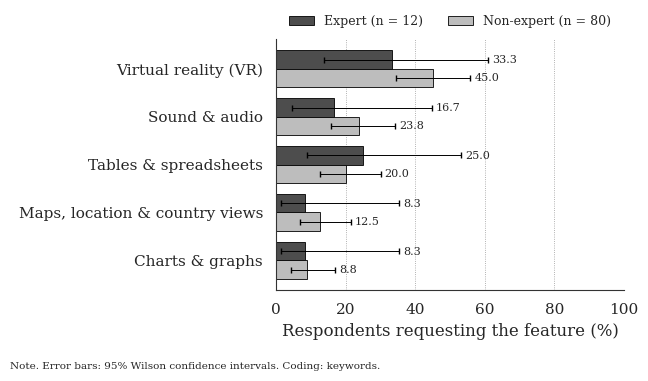

In [51]:
# Top 5 requested features: publication-style figure
def plotTop5Features(feature_tests, coded, method, top_n=5):
    if feature_tests is None or len(feature_tests) == 0:
        print("No feature results to plot.")
        return
    n_group = coded[GROUP_VAR].value_counts().reindex(GROUPS).fillna(0).astype(int)
    top = (feature_tests.assign(_tot=feature_tests[f"{GROUPS[0]} n"]
                                + feature_tests[f"{GROUPS[1]} n"])
           .sort_values("_tot", ascending=False).head(top_n))

    def wilson(k, n, z=1.96):
        if n == 0:
            return 0.0, 0.0
        p = k / n
        centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
        half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
        return 100 * (centre - half), 100 * (centre + half)

    top = top.iloc[::-1]
    colours = {GROUPS[0]: "#4D4D4D", GROUPS[1]: "#BDBDBD"}
    with plt.rc_context({"font.family": "serif",
                         "font.serif": ["Times New Roman", "DejaVu Serif"],
                         "font.size": 10, "axes.linewidth": 0.8}):
        fig, ax = plt.subplots(figsize=(6.5, 3.6))
        y = np.arange(len(top))
        h = 0.38
        for off, g in [(+h / 2, GROUPS[0]), (-h / 2, GROUPS[1])]:
            pcts = top[f"{g} %"].values
            ci = np.array([wilson(k, n_group[g]) for k in top[f"{g} n"].values])
            err = np.vstack([pcts - ci[:, 0], ci[:, 1] - pcts])
            ax.barh(y + off, pcts, h, color=colours[g], edgecolor="black",
                    linewidth=0.6, label=f"{g} (n = {n_group[g]})")
            ax.errorbar(pcts, y + off, xerr=err, fmt="none", ecolor="black",
                        elinewidth=0.7, capsize=2)
            for yi, v, hi in zip(y + off, pcts, ci[:, 1]):
                ax.text(hi + 1.2, yi, f"{v:.1f}", va="center", fontsize=8)
        ax.set_yticks(y)
        ax.set_yticklabels(top["Feature"])
        ax.set_xlabel("Respondents requesting the feature (%)")
        ax.set_xlim(0, 100)
        ax.spines[["top", "right"]].set_visible(False)
        ax.xaxis.grid(True, linestyle=":", linewidth=0.6, color="#999999")
        ax.yaxis.grid(False)
        ax.set_axisbelow(True)
        ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0),
                  ncol=2, fontsize=9)
        fig.text(0.01, -0.02, "Note. Error bars: 95% Wilson confidence intervals. "
                 f"Coding: {method}.", fontsize=7.5, ha="left", va="top")
        plt.tight_layout()
        saveFig(f"fig_13d_top5_features_{TEXT_ITEM}_by_{GROUP_VAR}_{method}")
        plt.show()


plotTop5Features(keyword_results, resp, "keywords")


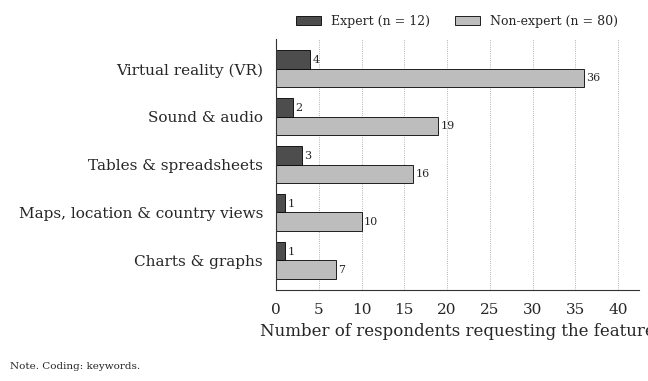

In [52]:
# Top 5 requested features: publication-style figure (counts)
def plotTop5Features(feature_tests, coded, method, top_n=5):
    if feature_tests is None or len(feature_tests) == 0:
        print("No feature results to plot.")
        return
    n_group = coded[GROUP_VAR].value_counts().reindex(GROUPS).fillna(0).astype(int)
    top = (feature_tests.assign(_tot=feature_tests[f"{GROUPS[0]} n"]
                                + feature_tests[f"{GROUPS[1]} n"])
           .sort_values("_tot", ascending=False).head(top_n))

    top = top.iloc[::-1]
    colours = {GROUPS[0]: "#4D4D4D", GROUPS[1]: "#BDBDBD"}
    with plt.rc_context({"font.family": "serif",
                         "font.serif": ["Times New Roman", "DejaVu Serif"],
                         "font.size": 10, "axes.linewidth": 0.8}):
        fig, ax = plt.subplots(figsize=(6.5, 3.6))
        y = np.arange(len(top))
        h = 0.38
        for off, g in [(+h / 2, GROUPS[0]), (-h / 2, GROUPS[1])]:
            counts = top[f"{g} n"].values
            ax.barh(y + off, counts, h, color=colours[g], edgecolor="black",
                    linewidth=0.6, label=f"{g} (n = {n_group[g]})")
            for yi, v in zip(y + off, counts):
                ax.text(v + 0.3, yi, f"{int(v)}", va="center", fontsize=8)
        ax.set_yticks(y)
        ax.set_yticklabels(top["Feature"])
        ax.set_xlabel("Number of respondents requesting the feature")
        ax.set_xlim(0, top[[f"{g} n" for g in GROUPS]].values.max() * 1.15 + 1)
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
        ax.spines[["top", "right"]].set_visible(False)
        ax.xaxis.grid(True, linestyle=":", linewidth=0.6, color="#999999")
        ax.yaxis.grid(False)
        ax.set_axisbelow(True)
        ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0),
                  ncol=2, fontsize=9)
        fig.text(0.01, -0.02, f"Note. Coding: {method}.", fontsize=7.5,
                 ha="left", va="top")
        plt.tight_layout()
        saveFig(f"fig_13d_top5_features_{TEXT_ITEM}_by_{GROUP_VAR}_{method}")
        plt.show()


plotTop5Features(keyword_results, resp, "keywords")

#### Agreement between experts and non-experts on priority features (Cohen's κ)


In [53]:
# Do experts and non-experts agree on which features matter?
# Items = features; "raters" = the two groups. Each group rates each feature as a
# PRIORITY if at least PRIORITY_PCT % of its responders asked for it.
#   Cohen's kappa  : agreement on priority / not priority, corrected for chance
#   Spearman's rho : agreement on the ranking of all features
#   Top-5 overlap  : shared features in each group's five most requested
# 95% CIs: bootstrap, resampling respondents within each group.
from sklearn.metrics import cohen_kappa_score

PRIORITY_PCT = 10
TOP_K = 5
N_BOOT = 2000


def groupProfiles(coded):
    feats = sorted(set().union(*coded["features"])) if len(coded) else []
    out = {}
    for g in GROUPS:
        sub = coded.loc[coded[GROUP_VAR] == g, "features"]
        out[g] = [100 * sub.apply(lambda s: f in s).mean() if len(sub) else np.nan
                  for f in feats]
    return pd.DataFrame(out, index=feats)


def agreement(prof):
    a, b = prof[GROUPS[0]], prof[GROUPS[1]]
    pa, pb = (a >= PRIORITY_PCT).astype(int), (b >= PRIORITY_PCT).astype(int)
    kappa = (cohen_kappa_score(pa, pb)
             if len(set(pa)) > 1 or len(set(pb)) > 1 else np.nan)
    rho = stats.spearmanr(a, b)[0] if len(prof) > 2 else np.nan
    overlap = len(set(a.nlargest(TOP_K).index) & set(b.nlargest(TOP_K).index))
    return kappa, rho, overlap


def groupAgreement(coded, method):
    coded = coded[coded[GROUP_VAR].isin(GROUPS)]
    prof = groupProfiles(coded)
    if prof.empty or (coded[GROUP_VAR].value_counts().reindex(GROUPS).fillna(0) < 2).any():
        print("Not enough coded answers in both groups.")
        return None
    k, r, o = agreement(prof)
    gen = np.random.default_rng(CONFIG["random_seed"])
    groups = {g: coded[coded[GROUP_VAR] == g] for g in GROUPS}
    boots = []
    for _ in range(N_BOOT):
        sample = pd.concat([d.iloc[gen.integers(0, len(d), len(d))]
                            for d in groups.values()])
        boots.append(agreement(groupProfiles(sample).reindex(prof.index).fillna(0)))
    boots = np.array(boots, dtype=float)
    ci = lambda j: np.nanpercentile(boots[:, j], [2.5, 97.5])
    n = coded[GROUP_VAR].value_counts().reindex(GROUPS)
    summary = pd.DataFrame([
        {"Measure": f"Cohen's kappa (priority = requested by >= {PRIORITY_PCT}%)",
         "Value": round(k, 2), "95% CI": "[{:.2f}, {:.2f}]".format(*ci(0))},
        {"Measure": "Spearman's rho (ranking of all features)",
         "Value": round(r, 2), "95% CI": "[{:.2f}, {:.2f}]".format(*ci(1))},
        {"Measure": f"Shared features in each group's top {TOP_K}",
         "Value": f"{o} of {TOP_K}", "95% CI": "[{:.0f}, {:.0f}]".format(*ci(2))},
    ])
    print(f"Agreement between {GROUPS[0]}s (n = {n[GROUPS[0]]}) and "
          f"{GROUPS[1]}s (n = {n[GROUPS[1]]}) on requested features [{method} coding]")
    print(summary.to_string(index=False))
    saveTable(summary, f"table_26h_group_agreement_{TEXT_ITEM}_{method}")
    return summary


groupAgreement(resp, "keywords")


Agreement between Experts (n = 12) and Non-experts (n = 80) on requested features [keywords coding]
                                       Measure  Value       95% CI
Cohen's kappa (priority = requested by >= 10%)   0.81 [0.19, 1.00]
      Spearman's rho (ranking of all features)   0.79 [0.40, 0.86]
         Shared features in each group's top 5 4 of 5       [3, 5]
  saved -> tables/table_26h_group_agreement_QID28_keywords.csv


,Measure,Value,95% CI
0,Cohen's kappa (priority = requested by >= 10%),0.81,"[0.19, 1.00]"
1,Spearman's rho (ranking of all features),0.79,"[0.40, 0.86]"
2,Shared features in each group's top 5,4 of 5,"[3, 5]"


#### Size of the expert vs non-expert difference per feature (Cohen's h)


In [54]:
# Cohen's h: size of the expert vs non-expert difference, per feature
# h = 2*arcsin(sqrt(p_experts)) - 2*arcsin(sqrt(p_non-experts))
# |h| < .20 negligible, .20 small, .50 medium, .80 large (Cohen, 1988).
# Positive h = experts request the feature more often than non-experts.
def cohensH(p1, p2):
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))


def hSize(h):
    h = abs(h)
    return ("negligible" if h < 0.2 else "small" if h < 0.5
            else "medium" if h < 0.8 else "large")


n_e = int((resp[GROUP_VAR] == GROUPS[0]).sum())
n_n = int((resp[GROUP_VAR] == GROUPS[1]).sum())
se_h = np.sqrt(1 / n_e + 1 / n_n)
rows = []
for _, r in keyword_results.iterrows():
    pe, pn = r[f"{GROUPS[0]} %"], r[f"{GROUPS[1]} %"]
    h = cohensH(pe / 100, pn / 100)
    rows.append({"Feature": r["Feature"],
                 f"{GROUPS[0]} (%)": pe, f"{GROUPS[1]} (%)": pn,
                 "Priority (E / N)": f"{'Yes' if pe >= PRIORITY_PCT else 'No'} / "
                                     f"{'Yes' if pn >= PRIORITY_PCT else 'No'}",
                 "Cohen's h": round(h, 2),
                 "95% CI": f"[{h - 1.96 * se_h:.2f}, {h + 1.96 * se_h:.2f}]",
                 "Effect": hSize(h)})
effect_sizes = (pd.DataFrame(rows)
                .assign(_tot=lambda d: d[f"{GROUPS[0]} (%)"] * n_e
                                       + d[f"{GROUPS[1]} (%)"] * n_n)
                .sort_values("_tot", ascending=False).drop(columns="_tot")
                .head(5))                                    # top 5 features
print(f"{GROUPS[0]}s (n = {n_e}) vs {GROUPS[1]}s (n = {n_n}): Cohen's h, top 5 features")
print(effect_sizes.to_string(index=False))
saveTable(effect_sizes, f"table_26i_cohens_h_{TEXT_ITEM}")


Experts (n = 12) vs Non-experts (n = 80): Cohen's h, top 5 features
                       Feature  Expert (%)  Non-expert (%) Priority (E / N)  Cohen's h        95% CI     Effect
          Virtual reality (VR)        33.3            45.0        Yes / Yes      -0.24 [-0.85, 0.37]      small
                 Sound & audio        16.7            23.8        Yes / Yes      -0.18 [-0.78, 0.43] negligible
         Tables & spreadsheets        25.0            20.0        Yes / Yes       0.12 [-0.49, 0.73] negligible
Maps, location & country views         8.3            12.5         No / Yes      -0.14 [-0.75, 0.47] negligible
               Charts & graphs         8.3             8.8          No / No      -0.02 [-0.62, 0.59] negligible
  saved -> tables/table_26i_cohens_h_QID28.csv


,Feature,Expert (%),Non-expert (%),Priority (E / N),Cohen's h,95% CI,Effect
0,Virtual reality (VR),33.3,45.0,Yes / Yes,-0.24,"[-0.85, 0.37]",small
1,Sound & audio,16.7,23.8,Yes / Yes,-0.18,"[-0.78, 0.43]",negligible
2,Tables & spreadsheets,25.0,20.0,Yes / Yes,0.12,"[-0.49, 0.73]",negligible
3,"Maps, location & country views",8.3,12.5,No / Yes,-0.14,"[-0.75, 0.47]",negligible
4,Charts & graphs,8.3,8.8,No / No,-0.02,"[-0.62, 0.59]",negligible


### 7.1c Transformer coding of the suggested features (comparison)

As a check on the keyword coding, we also code the answers with a zero-shot
natural-language-inference model (`facebook/bart-large-mnli`). For each answer and
feature the model scores the statement *"This suggestion asks for {feature}."* A
feature is assigned when its probability is at least 0.90 and it is among the
answer's three highest-scoring features. Non-answers ("nothing", "good") are not
scored. We report agreement with the keyword coding (Cohen's κ per feature, and
for the top five features separately for experts and non-experts with bootstrap
95% CIs) and save all answers where the two methods disagree (`table_26e_…`).


Zero-shot coding with facebook/bart-large-mnli (threshold 0.9, max 3 per answer) ...


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

  loaded facebook/bart-large-mnli on cpu; labels ['contradiction', 'entailment', 'neutral']
  scored 16 of 75 answers
  scored 32 of 75 answers
  scored 48 of 75 answers
  scored 64 of 75 answers
  scored 75 of 75 answers

Inflation check (a high mean probability, or % transformer far above % keywords, suggests a catch-all category):
                                Mean probability  % transformer  % keywords
Notifications & alerts                      0.48           17.4         0.0
Tutorials & help                            0.41            0.0         0.0
Virtual reality (VR)                        0.40           35.9        43.5
Sound & audio                               0.37           21.7        22.8
View / display options                      0.27            2.2         3.3
Comparison tool                             0.25            3.3         2.2
Filtering & search                          0.24            1.1         0.0
AI / chatbot / recommendations              0.22        

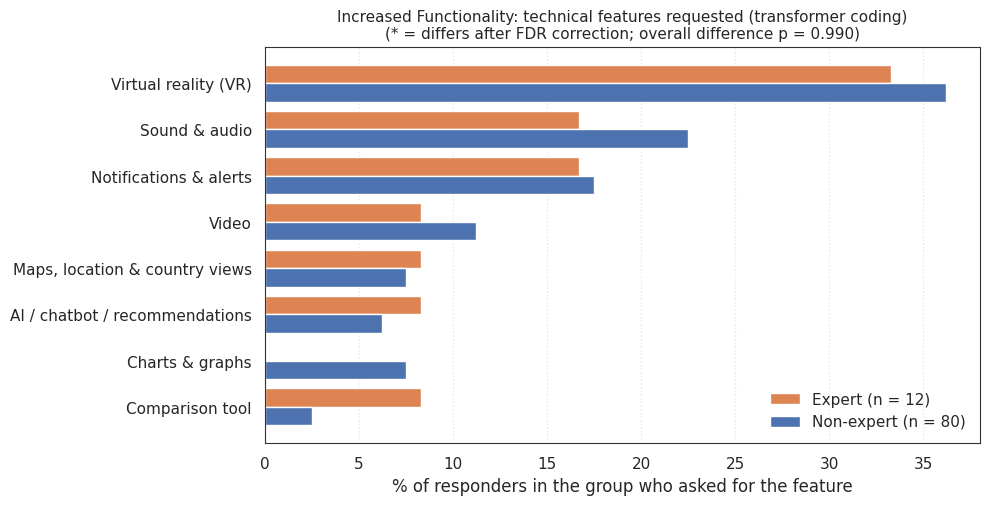

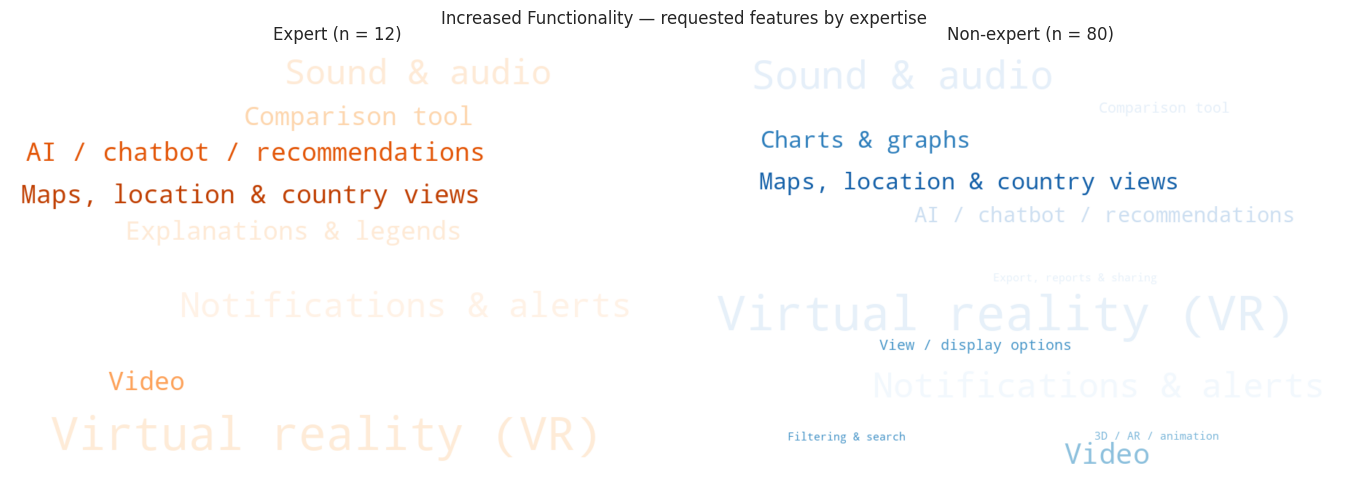


Agreement between keyword and transformer coding (kappa: >.80 strong, .60-.80 substantial, <.40 weak)
                       Feature  Keywords n  Transformer n  Both  % agreement  Cohen's kappa
          Virtual reality (VR)          40             33    33         92.4           0.84
                 Sound & audio          21             20    19         96.7           0.91
        Notifications & alerts           0             16     0         82.6           0.00
                         Video           2             10     2         91.3           0.31
Maps, location & country views          11              7     7         95.7           0.75
               Charts & graphs           8              6     5         95.7           0.69
AI / chatbot / recommendations           3              6     2         94.6           0.42
               Comparison tool           2              3     2         98.9           0.79
        View / display options           3              2     2      

In [55]:
# Transformer (zero-shot) coding of the same answers.
# Loaded the same way as the sentiment model in Part 3 (AutoTokenizer +
# AutoModelForSequenceClassification, model name from CONFIG). The sentiment
# model itself cannot be used: it only outputs negative/neutral/positive. Feature
# coding needs a natural-language-inference (NLI) model, which scores whether a
# statement ("This suggestion asks for VR.") follows from the answer.
ZS_MODEL = CONFIG.get("feature_model", "facebook/bart-large-mnli")
ZS_TEMPLATE = "This suggestion asks for {}."
ZS_THRESHOLD = 0.90        # a feature is assigned when the model's probability >= this
MAX_FEATURES = 3           # ... and it is among the answer's 3 highest-scoring features
ZS_BATCH = 16

# Non-answers ("No", "Nice", ".") are already removed in 7.1b (isNonAnswer), so
# every answer reaching the model is a real suggestion. NLI models score such
# fragments erratically, which is what inflated some categories before.

# What the model is asked about: a plain-English description per feature.
# Keep the KEYS identical to TECH_FEATURES so the two codings can be compared.
FEATURE_DESCRIPTIONS = {
    "Maps, location & country views": "a map or location-based or country-level view",
    "Tables & spreadsheets":         "tables or spreadsheets",
    "View / display options":        "new viewing modes such as zoom, full-screen or split-screen views",
    "Sound & audio":                 "sound or audio",
    "Video":                         "videos",
    "Charts & graphs":               "charts, graphs or data visualisation",
    "Dashboard":                     "a dashboard",
    "Virtual reality (VR)":          "virtual reality (VR)",
    "3D / AR / animation":           "3D models, augmented reality or animation",
    "Filtering & search":            "search or filtering",
    "Comparison tool":               "a comparison or benchmarking tool",
    "Calculator / what-if scenarios": "a calculator or what-if scenarios",
    "Real-time / live updates":      "data that updates live in real time",
    "AI / chatbot / recommendations": "artificial intelligence, a chatbot or recommendations",
    "Export, reports & sharing":     "exporting, downloading, reports or sharing",
    "Accounts & personalisation":    "user accounts, saving or personalisation",
    "Notifications & alerts":        "notifications or alerts sent to the user",
    "Mobile app & devices":          "a smartphone or tablet app version of the tool",
    "Tutorials & help":              "tutorials, guidance or help",
    "Gamification":                  "games, quizzes or rewards",
    "UI / visual design":            "changes to the colours, layout or visual design of the interface",
    "Language & accessibility":      "more languages or accessibility",
    "Collaboration & community":     "a forum or tools for users to collaborate with each other",
    "Explanations & legends":        "explanations or legends describing what the data means",
}
assert set(FEATURE_DESCRIPTIONS) == set(TECH_FEATURES), \
    "FEATURE_DESCRIPTIONS and TECH_FEATURES must have the same features"
desc_to_feature = {d: f for f, d in FEATURE_DESCRIPTIONS.items()}

zs_cache = Path(CONFIG["cache_dir"]) / f"zeroshot_{TEXT_ITEM}.json"


# {text: {feature: probability}} — cached, so the model runs once
def zeroShotScores(texts):
    cache = json.loads(zs_cache.read_text(encoding="utf-8")) if zs_cache.exists() else {}
    key = f"{ZS_MODEL}|{ZS_TEMPLATE}|" + "|".join(FEATURE_DESCRIPTIONS.values())
    if cache.get("_key") != key:
        cache = {"_key": key}
    todo = [t for t in dict.fromkeys(texts) if t not in cache]
    if todo:
        if not HAS_TRANSFORMERS:
            raise RuntimeError("transformers is not installed: pip install transformers torch")
        from transformers import AutoModelForSequenceClassification, AutoTokenizer
        import torch

        tok = AutoTokenizer.from_pretrained(ZS_MODEL)
        model = AutoModelForSequenceClassification.from_pretrained(ZS_MODEL)
        model.eval()
        device = "cuda" if torch.cuda.is_available() else "cpu"
        model.to(device)

        # Read the label order from the model config rather than assuming it.
        id2label = {int(k): v.lower() for k, v in model.config.id2label.items()}
        # 3-label NLI models (BART-MNLI): entailment / neutral / contradiction.
        # 2-label zero-shot models (DeBERTa zeroshot-v2): entailment / not_entailment.
        ent = [i for i, l in id2label.items() if "entail" in l and "not" not in l]
        con = [i for i, l in id2label.items() if "contra" in l or "not_entail" in l
               or "not entail" in l]
        if not ent or not con:
            raise ValueError(f"{ZS_MODEL} is not an NLI model (labels: "
                             f"{sorted(id2label.values())}). Set CONFIG['feature_model'] "
                             "to an NLI model such as MoritzLaurer/deberta-v3-large-zeroshot-v2.0.")
        ent, con = ent[0], con[0]
        print(f"  loaded {ZS_MODEL} on {device}; labels {sorted(id2label.values())}")

        feats = list(FEATURE_DESCRIPTIONS)
        hyps = [ZS_TEMPLATE.format(FEATURE_DESCRIPTIONS[f]) for f in feats]
        for i in range(0, len(todo), ZS_BATCH):
            batch = todo[i:i + ZS_BATCH]
            # One (answer, hypothesis) pair per answer x feature.
            prem = [t for t in batch for _ in hyps]
            hyp = hyps * len(batch)
            enc = tok(prem, hyp, padding=True, truncation="only_first", max_length=256,
                      return_tensors="pt").to(device)
            with torch.no_grad():
                logits = model(**enc).logits
            # Multi-label scoring, as in the standard zero-shot method: for each
            # feature, P(entailment) from a softmax over entailment vs contradiction.
            probs = torch.softmax(logits[:, [con, ent]], dim=-1)[:, 1]
            probs = probs.view(len(batch), len(feats)).cpu().numpy()
            for t, row in zip(batch, probs):
                cache[t] = {f: round(float(pv), 4) for f, pv in zip(feats, row)}
            print(f"  scored {min(i + ZS_BATCH, len(todo))} of {len(todo)} answers")
        zs_cache.write_text(json.dumps(cache, indent=1), encoding="utf-8")
    return {t: cache[t] for t in texts}


if not HAS_TRANSFORMERS and not zs_cache.exists():
    print("transformers not installed and no cached scores — skipping transformer coding.")
    print("  pip install transformers torch")
else:
    texts = resp[TEXT_ITEM].astype(str).str.strip().tolist()
    non_ans = [isNonAnswer(t) for t in texts]          # none expected (filtered in 7.1b)
    to_score = [t for t, na in zip(texts, non_ans) if not na]
    print(f"Zero-shot coding with {ZS_MODEL} (threshold {ZS_THRESHOLD}, "
          f"max {MAX_FEATURES} per answer) ...")
    scores = zeroShotScores(to_score)

    def assign(t, na):
        if na:
            return set()
        ranked = sorted(scores[t].items(), key=lambda kv: kv[1], reverse=True)
        return {f for f, p in ranked[:MAX_FEATURES] if p >= ZS_THRESHOLD}

    resp_zs = resp.copy()
    resp_zs["features"] = [assign(t, na) for t, na in zip(texts, non_ans)]

    # Inflation check: a feature the model assigns far more often than the keyword
    # coding finds it, or that scores high on average, is probably a catch-all.
    if to_score:
        mean_p = pd.DataFrame([scores[t] for t in to_score]).mean()
        inflation = pd.DataFrame({
            "Mean probability": mean_p.round(2),
            "% transformer": [pct(int(resp_zs["features"].apply(lambda s: f in s).sum()),
                                  len(resp_zs)) for f in mean_p.index],
            "% keywords": [pct(int(resp["features"].apply(lambda s: f in s).sum()),
                               len(resp)) for f in mean_p.index],
        }, index=mean_p.index).sort_values("Mean probability", ascending=False)
        print("\nInflation check (a high mean probability, or % transformer far above "
              "% keywords, suggests a catch-all category):")
        print(inflation.head(10).to_string())

    transformer_results = analyseFeatures(resp_zs, "transformer")

    # How well do the two codings agree?
    from sklearn.metrics import cohen_kappa_score
    agree_rows = []
    for f in TECH_FEATURES:
        kw = resp["features"].apply(lambda s: f in s).values
        zs = resp_zs["features"].apply(lambda s: f in s).values
        if kw.sum() + zs.sum() == 0:
            continue
        both_const = (kw.min() == kw.max()) and (zs.min() == zs.max())
        agree_rows.append({
            "Feature": f,
            "Keywords n": int(kw.sum()),
            "Transformer n": int(zs.sum()),
            "Both": int((kw & zs).sum()),
            "% agreement": pct(int((kw == zs).sum()), len(kw)),
            "Cohen's kappa": (np.nan if both_const
                              else round(cohen_kappa_score(kw, zs), 2)),
        })
    agreement = pd.DataFrame(agree_rows).sort_values("Transformer n", ascending=False)
    print("\nAgreement between keyword and transformer coding "
          "(kappa: >.80 strong, .60-.80 substantial, <.40 weak)")
    print(agreement.to_string(index=False))
    saveTable(agreement, f"table_26d_coding_agreement_{TEXT_ITEM}")

    # Top-5 features: agreement by expertise
    # The five features requested most often (transformer coding, the main method),
    # and for each one Cohen's kappa between the keyword and transformer coding,
    # separately for experts and non-experts, with a bootstrap 95% CI. This shows
    # whether the coding is equally reliable in both groups: if it is much worse for
    # one group, a group difference in that feature could come from the coding.
    TOP_K = 5
    N_BOOT = 2000
    zs_counts = resp_zs["features"].explode().value_counts()
    top_feats = list(zs_counts.head(TOP_K).index)
    gen = np.random.default_rng(CONFIG["random_seed"])

    # cohen's kappa with a percentile bootstrap 95% CI (NaN if undefined)
    def kappaCi(kw, zs):
        def k(a, b):
            if len(set(a)) < 2 and len(set(b)) < 2:
                return np.nan                         # no variation: kappa undefined
            return cohen_kappa_score(a, b)
        point = k(kw, zs)
        if np.isnan(point):
            return point, np.nan, np.nan
        boots = []
        for _ in range(N_BOOT):
            i = gen.integers(0, len(kw), len(kw))
            boots.append(k(kw[i], zs[i]))
        lo, hi = np.nanpercentile(boots, [2.5, 97.5])
        return point, lo, hi

    top_rows = []
    for f in top_feats:
        row = {"Feature": f, "Total n (transformer)": int(zs_counts[f])}
        for g in GROUPS:
            m = (resp[GROUP_VAR] == g).values
            kw = resp.loc[m, "features"].apply(lambda s: f in s).values.astype(int)
            zs = resp_zs.loc[m, "features"].apply(lambda s: f in s).values.astype(int)
            kap, lo, hi = kappaCi(kw, zs)
            row[f"{g} n"] = int(m.sum())
            row[f"{g} % requesting"] = pct(int(zs.sum()), int(m.sum()))
            row[f"{g} % agreement"] = pct(int((kw == zs).sum()), int(m.sum()))
            row[f"{g} kappa [95% CI]"] = ("n/a" if np.isnan(kap) else
                                          f"{kap:.2f} [{lo:.2f}, {hi:.2f}]")
        top_rows.append(row)
    top5 = pd.DataFrame(top_rows)
    print(f"\nTop {TOP_K} requested features — keyword vs transformer agreement "
          "by expertise (Cohen's kappa, bootstrap 95% CI)")
    print(top5.to_string(index=False))
    print("Read: similar kappa in both groups = the coding is equally reliable for "
          "experts and non-experts. Wide CIs for experts reflect their small number.")
    saveTable(top5, f"table_26f_top5_kappa_by_{GROUP_VAR}_{TEXT_ITEM}")

    # Answers where the two disagree — read these to decide which is right.
    diff = resp[[GROUP_VAR, TEXT_ITEM]].assign(
        Keywords=resp["features"].apply(lambda s: "; ".join(sorted(s)) or "(none)"),
        Transformer=resp_zs["features"].apply(lambda s: "; ".join(sorted(s)) or "(none)"))
    diff = diff[diff["Keywords"] != diff["Transformer"]]
    saveTable(diff, f"table_26e_coding_disagreements_{TEXT_ITEM}")
    print(f"\n{len(diff)} answers coded differently by the two methods "
          "(first 10; all saved):")
    print(diff.head(10).to_string(index=False))


### 7.2 Joint display: sentiment vs qualitative themes

Requires `qual_themes.csv`. Theme counts are expressed as a percentage of each
region's total mentions so that regions of different size can be compared.


In [56]:
qual_path = Path(CONFIG["qual_themes_file"])
if not qual_path.exists():
    print(f"{qual_path} not found — skipping the joint display.")
    print("  Expected columns: 'Main Category' plus one count column per region.")
else:
    df_qual = pd.read_csv(qual_path)
    region_cols = [r for r in region_order if r in df_qual.columns]
    if not region_cols:
        print(f"{qual_path} has no region columns matching {region_order}.")
    else:
        totals = df_qual[region_cols].sum()
        theme_pct = (df_qual.set_index("Main Category")[region_cols]
                     .div(totals, axis=1) * 100).round(1)
        print("Theme mentions as % of each region's total mentions")
        print(theme_pct.to_string())
        saveTable(theme_pct.reset_index(), "table_27_theme_percentages")

        ux_theme = "Improved User Interface and Support"
        if ux_theme in theme_pct.index:
            ue_pct = theme_pct.loc[ux_theme, region_cols]
            ue_col = construct_col_map["User-experience"]
            gg = df_mice_full.groupby("Region", observed=True)[ue_col]
            means = gg.mean().reindex(region_cols)
            sds = gg.std().reindex(region_cols)
            ns = gg.size().reindex(region_cols)

            x = np.arange(len(region_cols))
            w = 0.36
            fig, ax = plt.subplots(figsize=(8, 5))
            ax.bar(x - w / 2, means.values, w, yerr=sds.values, capsize=5,
                   color="#9DB4C8", edgecolor="#4A6076",
                   label="User-experience sentiment (mean ± SD)")
            ax.bar(x + w / 2, ue_pct.values, w, color="#B5495B",
                   edgecolor="#7A2E3A",
                   label="UI/support improvement mentions (% of region total)")
            for xi, m in zip(x, means.values):
                ax.text(xi - w / 2, m + 1.5, f"{m:.1f}", ha="center", fontsize=8)
            for xi, p in zip(x, ue_pct.values):
                ax.text(xi + w / 2, p + 1.5, f"{p:.1f}%", ha="center", fontsize=8)
            ax.set_ylabel("Value (0–100 scale)")
            ax.set_ylim(0, 100)
            ax.set_xticks(x)
            ax.set_xticklabels([f"{r}\n(n = {int(n)})"
                                for r, n in zip(region_cols, ns)])
            ax.legend(loc="upper right", frameon=False, fontsize=8)
            ax.yaxis.grid(True, ls=":", alpha=0.5)
            ax.set_axisbelow(True)
            plt.title("Joint display: sentiment and improvement requests by region")
            plt.tight_layout()
            saveFig("fig_14_joint_display")
            plt.show()
            print("\nRead this as convergence/divergence, not correlation: three "
                  "regions give three points, far too few to correlate. High "
                  "sentiment alongside many improvement requests means users liked "
                  "the prototype and still wanted changes — a substantive finding, "
                  "not a contradiction.")

qual_themes.csv not found — skipping the joint display.
  Expected columns: 'Main Category' plus one count column per region.


### 7.3 LLM-assisted keyword scoring (off by default)

Optional keyword ranking with a local Ollama model. It is disabled by default
(`CONFIG["use_ollama"] = False`) because generated output varies between runs and
requires a local server. It is not used in any reported result.


In [57]:
CONFIG["use_ollama"] = False
OLLAMA_CACHE = Path(CONFIG["cache_dir"]) / "llm_keywords.json"

if CONFIG["use_ollama"]:
    try:
        import ollama
        from tqdm import tqdm
        keywords = {}
        for qid in [c for c in Questions if c in df.columns][:5]:
            answers = df[qid].dropna().astype(str).tolist()
            if not answers:
                continue
            prompt = (
                f"Question: {question_labels.get(qid, qid)}\n"
                f"Responses:\n" + "\n".join(answers) + "\n\n"
                "List the keywords relating to life cycle sustainability and give "
                "each an integer score from 0 (negative) to 5 (highly positive), "
                "reflecting the keyword's implication for life cycle "
                "sustainability rather than how often it appears. "
                "Reply with one 'keyword: score' pair per line and nothing else."
            )
            resp = ollama.chat(model="llama3.2:3b",
                               messages=[{"role": "user", "content": prompt}],
                               options={"seed": CONFIG["random_seed"],
                                        "temperature": 0.0})
            keywords[qid] = resp["message"]["content"]
        OLLAMA_CACHE.write_text(json.dumps(keywords, indent=2), encoding="utf-8")
        print(f"Cached {len(keywords)} LLM responses -> {OLLAMA_CACHE}")
    except Exception as exc:
        print(f"Ollama step failed ({type(exc).__name__}: {exc}).")
        print("Needs a running Ollama server with llama3.2:3b pulled.")
elif OLLAMA_CACHE.exists():
    keywords = json.loads(OLLAMA_CACHE.read_text(encoding="utf-8"))
    print(f"Loaded {len(keywords)} cached LLM responses from {OLLAMA_CACHE}")
else:
    print("LLM keyword scoring disabled (CONFIG['use_ollama'] = False) and no cache "
          "present. Nothing downstream depends on it.")

LLM keyword scoring disabled (CONFIG['use_ollama'] = False) and no cache present. Nothing downstream depends on it.


## Part 9 — Tracker, Mapping and Geolocation features

This part addresses three questions:

1. How did respondents rate each feature, and the prototype's usability,
   interactivity, experience and usefulness?
2. What improvements did they suggest (open-ended answers)?
3. How do the prototypes help them understand the LCSA indicators (numeric
   values, colour, location, impact categories)?

All analyses use observed answers only. The question-to-topic mapping is set in
the first cell below.


In [58]:
# Which survey questions answer which part (edit to match the questionnaire)
FEATURE_ITEMS = {                      # opinion of each feature (like/dislike, open text)
    "Tracker":     "QID13_5",
    "Mapping":     "QID13_4",
    "Geolocation": "QID13_6",
}
DIMENSION_ITEMS = {                    # general opinion dimensions (open text)
    "Usability (intuitiveness)": "QID19",
    "Interactivity":             "QID21",
    "Experience":                "QID12",
    "Usefulness":                "QID16",
}
IMPROVE_ITEMS = ["QID14", "QID20", "QID23", "QID26"]   # "how would you improve ..."
INDICATOR_ITEMS = ["QID16", "QID17", "QID18", "QID19"]  # understanding / representing LCSA

# Sentiment for any of these items that Part 3 did not score (same model ensemble,
# cached separately so Part 3's cache is untouched).
wanted = list(dict.fromkeys(list(FEATURE_ITEMS.values()) + list(DIMENSION_ITEMS.values())))
extra = [c for c in wanted if c in df.columns and c not in df_scores.columns]
extra_scores = pd.DataFrame(index=df.index)
if extra:
    parts = []
    for name in model_scores:                    # the models that ran in Part 3
        try:
            parts.append(scoreFrame(df, extra, name, tag="part9"))
        except Exception as exc:
            print(f"  ** {name} skipped for Part 9: {exc}")
    if parts:
        extra_scores = sum(parts) / len(parts)
all_scores = pd.concat([df_scores, extra_scores], axis=1)
scores_ctx = pd.concat([df[context_cols], all_scores], axis=1)

for label, col in list(FEATURE_ITEMS.items()) + list(DIMENSION_ITEMS.items()):
    question_labels.setdefault(col, label)
absent = [c for c in wanted if c not in all_scores.columns]
print(f"Scored items available: {[c for c in wanted if c in all_scores.columns]}")
if absent:
    print(f"Not in the data (check the mapping above): {absent}")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  loaded cardiffnlp/twitter-roberta-base-sentiment-latest on cpu; labels ['negative', 'neutral', 'positive']
  cardiffnlp/twitter-roberta-base-sentiment-latest | QID19: scored 187, missing 25
  cardiffnlp/twitter-roberta-base-sentiment-latest | QID16: scored 135, missing 77
Cached -> cache/sentiment_cardiffnlp_twitter_roberta_base_sentiment_latest_expected_score_part9.csv


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  loaded nlptown/bert-base-multilingual-uncased-sentiment on cpu; labels ['1 star', '2 stars', '3 stars', '4 stars', '5 stars']
  nlptown/bert-base-multilingual-uncased-sentiment | QID19: scored 187, missing 25
  nlptown/bert-base-multilingual-uncased-sentiment | QID16: scored 135, missing 77
Cached -> cache/sentiment_nlptown_bert_base_multilingual_uncased_sentiment_expected_score_part9.csv


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  loaded lxyuan/distilbert-base-multilingual-cased-sentiments-student on cpu; labels ['positive', 'neutral', 'negative']
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID19: scored 187, missing 25
  lxyuan/distilbert-base-multilingual-cased-sentiments-student | QID16: scored 135, missing 77
Cached -> cache/sentiment_lxyuan_distilbert_base_multilingual_cased_sentiments_student_expected_score_part9.csv
Scored items available: ['QID13_5', 'QID13_4', 'QID13_6', 'QID19', 'QID21', 'QID12', 'QID16']


### 9.1 Opinion of the three features

The same respondents rated all three features, so we compare them within person:
Friedman test (effect size Kendall's *W*), then pairwise Wilcoxon signed-rank tests
with Holm correction (effect size rank-biserial *r*). Region and expertise
differences use the tests from 5.4.


Sentiment towards each feature — mean ± SD (n) by expertise
    Feature   n  Mean   SD  Median       IQR           Expert        Non-expert
    Tracker 143  68.1 14.3    69.5 64.2–74.0 62.9 ± 13.1 (17) 68.8 ± 14.3 (126)
    Mapping 148  68.4 14.6    69.5 64.2–75.1 64.9 ± 12.7 (17) 68.8 ± 14.8 (131)
Geolocation 153  67.7 15.2    69.5 64.5–75.1 62.5 ± 14.4 (16) 68.3 ± 15.3 (137)
  saved -> tables/table_30_feature_sentiment.csv

Friedman test (n = 141 who answered all three): chi2(2) = 1.18, p = 0.5555, Kendall's W = 0.00

Pairwise Wilcoxon signed-rank tests (positive r = first feature rated higher)
            Comparison   n  Median difference     W  r (rank-biserial)      p  p (Holm)
    Tracker vs Mapping 142                0.0 617.5               0.07 0.6697       1.0
Tracker vs Geolocation 142                0.0 653.5              -0.09 0.5831       1.0
Mapping vs Geolocation 145                0.0 816.0              -0.01 0.9335       1.0
  saved -> tables/table_31_feature_pairwise.

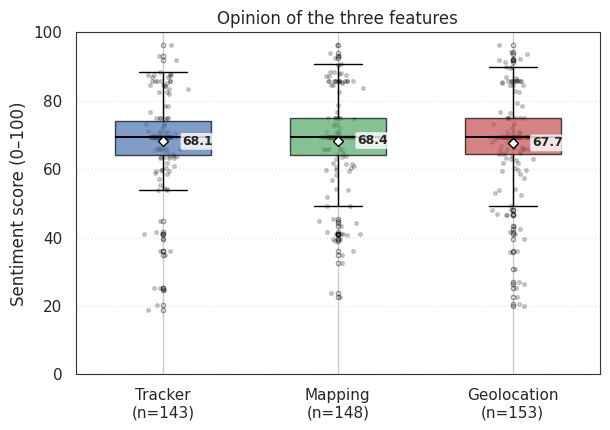

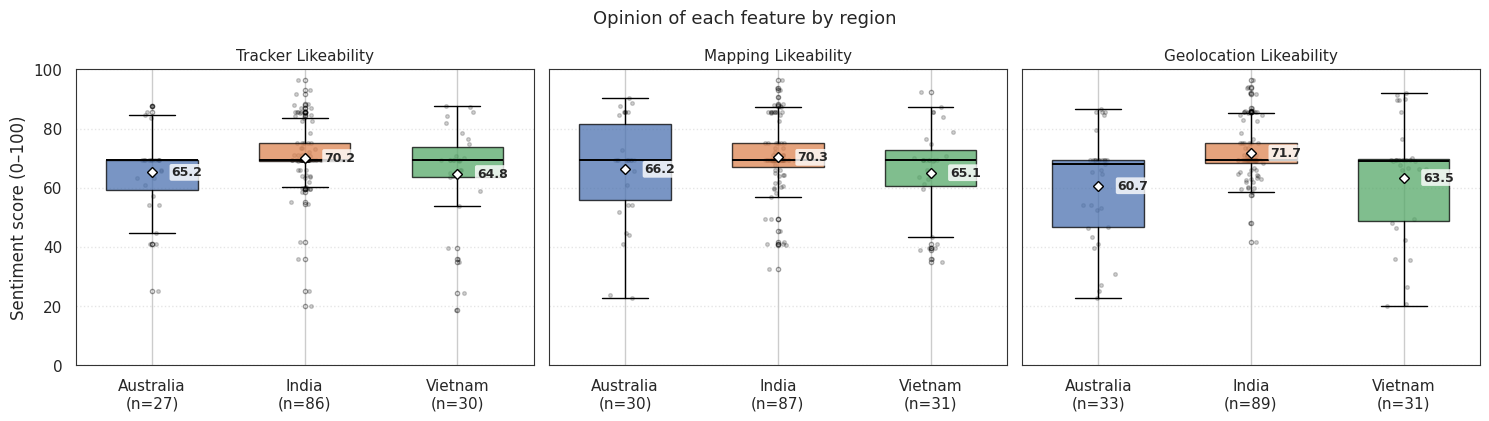

In [59]:
feat_cols = [c for c in FEATURE_ITEMS.values() if c in all_scores.columns]
feat_names = {c: f for f, c in FEATURE_ITEMS.items()}

# Descriptives
rows = []
for c in feat_cols:
    v = all_scores[c].dropna()
    row = {"Feature": feat_names[c], "n": len(v), "Mean": round(v.mean(), 1),
           "SD": round(v.std(ddof=1), 1), "Median": round(v.median(), 1),
           "IQR": f"{v.quantile(.25):.1f}–{v.quantile(.75):.1f}"}
    for g in GROUPS:
        row[g] = fmtCell(all_scores.loc[df["Occupation"] == g, c])
    rows.append(row)
feature_desc = pd.DataFrame(rows)
print("Sentiment towards each feature — mean ± SD (n) by expertise")
print(feature_desc.to_string(index=False))
saveTable(feature_desc, "table_30_feature_sentiment")

# Within-person comparison
complete = all_scores[feat_cols].dropna()
if len(complete) >= 5 and len(feat_cols) >= 3:
    chi2_f, p_f = stats.friedmanchisquare(*[complete[c] for c in feat_cols])
    W = chi2_f / (len(complete) * (len(feat_cols) - 1))
    print(f"\nFriedman test (n = {len(complete)} who answered all three): "
          f"chi2({len(feat_cols) - 1}) = {chi2_f:.2f}, p = {p_f:.4f}, Kendall's W = {W:.2f}")

    def rankBiserial(x, y):
        d = np.asarray(x) - np.asarray(y)
        d = d[d != 0]
        if len(d) == 0:
            return 0.0
        r = stats.rankdata(np.abs(d))
        return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()

    pair_rows, raw_p = [], []
    for a, b in [(0, 1), (0, 2), (1, 2)]:
        ca, cb = feat_cols[a], feat_cols[b]
        pair = all_scores[[ca, cb]].dropna()
        stat, p = stats.wilcoxon(pair[ca], pair[cb])
        raw_p.append(p)
        pair_rows.append({"Comparison": f"{feat_names[ca]} vs {feat_names[cb]}",
                          "n": len(pair),
                          "Median difference": round(float((pair[ca] - pair[cb]).median()), 1),
                          "W": round(float(stat), 1),
                          "r (rank-biserial)": round(rankBiserial(pair[ca], pair[cb]), 2)})
    pairs = pd.DataFrame(pair_rows)
    pairs["p"] = np.round(raw_p, 4)
    pairs["p (Holm)"] = np.round(multipletests(raw_p, method="holm")[1], 4)
    print("\nPairwise Wilcoxon signed-rank tests (positive r = first feature rated higher)")
    print(pairs.to_string(index=False))
    saveTable(pairs, "table_31_feature_pairwise")
else:
    print("\nToo few respondents answered all three feature questions for a "
          "within-person test.")

# Region and expertise, per feature
for gvar in ["Region", "Occupation"]:
    res, dropped = groupComparison(scores_ctx, feat_cols, gvar, orderFor(gvar))
    if not res.empty:
        print(f"\nFeatures by {labelOf(gvar)}")
        print(res[[c for c in res.columns if not c.endswith("(n)")]].to_string(index=False))
        saveTable(res, f"table_32_features_by_{gvar}")

# Figure (a): the three features side by side
with plt.rc_context({"font.size": 10}):
    fig, ax = plt.subplots(figsize=(6.2, 4.4))
    data = [all_scores[c].dropna().values for c in feat_cols]
    bp = ax.boxplot(data, patch_artist=True, showmeans=True, widths=0.55,
                    tick_labels=[f"{feat_names[c]}\n(n={len(d)})" for c, d in zip(feat_cols, data)],
                    medianprops=dict(color="black", linewidth=1.4),
                    meanprops=dict(marker="D", markerfacecolor="white",
                                   markeredgecolor="black", markersize=5),
                    flierprops=dict(marker="o", markersize=3, alpha=0.4))
    for patch, colr in zip(bp["boxes"], ["#4C72B0", "#55A868", "#C44E52"]):
        patch.set_facecolor(colr)
        patch.set_alpha(0.7)
    jit = np.random.default_rng(CONFIG["random_seed"])
    for i, d in enumerate(data, start=1):
        ax.scatter(jit.normal(i, 0.05, len(d)), d, s=7, color="black", alpha=0.18)
        if len(d):
            ax.annotate(f"{np.mean(d):.1f}", xy=(i, np.mean(d)), xytext=(14, 0),
                        textcoords="offset points", va="center", fontsize=9,
                        fontweight="bold", bbox=dict(boxstyle="round,pad=0.15",
                                                     fc="white", ec="none", alpha=0.8))
    ax.set_ylim(0, 100)
    ax.set_ylabel("Sentiment score (0–100)")
    ax.set_title("Opinion of the three features")
    ax.yaxis.grid(True, linestyle=":", alpha=0.5)
    ax.set_axisbelow(True)
    plt.tight_layout()
    saveFig("fig_20a_feature_sentiment")
    plt.show()

# Figure (b): each feature by region (includes Geolocation)
regionBoxplots(all_scores, feat_cols, "Opinion of each feature by region",
                "fig_20b_feature_sentiment_by_region", ncols=3)


#### Usability, interactivity, experience and usefulness

These questions were asked about the prototype as a whole, not per feature.


Sentiment by dimension — mean ± SD (n) by expertise
                Dimension Question   n  Mean   SD  Median           Expert        Non-expert
Usability (intuitiveness)    QID19 187  81.1 14.9    86.3 78.9 ± 17.7 (22) 81.4 ± 14.5 (165)
            Interactivity    QID21 178  77.9 16.0    85.0 75.8 ± 17.4 (20) 78.2 ± 15.8 (158)
               Experience    QID12 182  82.5 13.8    85.7 81.4 ± 18.7 (18) 82.7 ± 13.2 (164)
               Usefulness    QID16 135  78.7 16.9    85.7 81.2 ± 16.9 (16) 78.3 ± 16.9 (119)
  saved -> tables/table_33_dimension_sentiment.csv

Dimensions by Region
             Variable Total (M±SD) Australia (M±SD) India (M±SD) Vietnam (M±SD)           Test  Statistic  Effect size Effect metric  Magnitude    Higher      p  p (holm) Significant
        Intuitiveness  81.1 ± 14.9      80.2 ± 18.9  82.8 ± 12.2    76.7 ± 17.5 Kruskal-Wallis      3.660        0.020     epsilon^2      small     India 0.1604    0.3208          no
      Interactiveness  77.9 ± 16.0      76.3

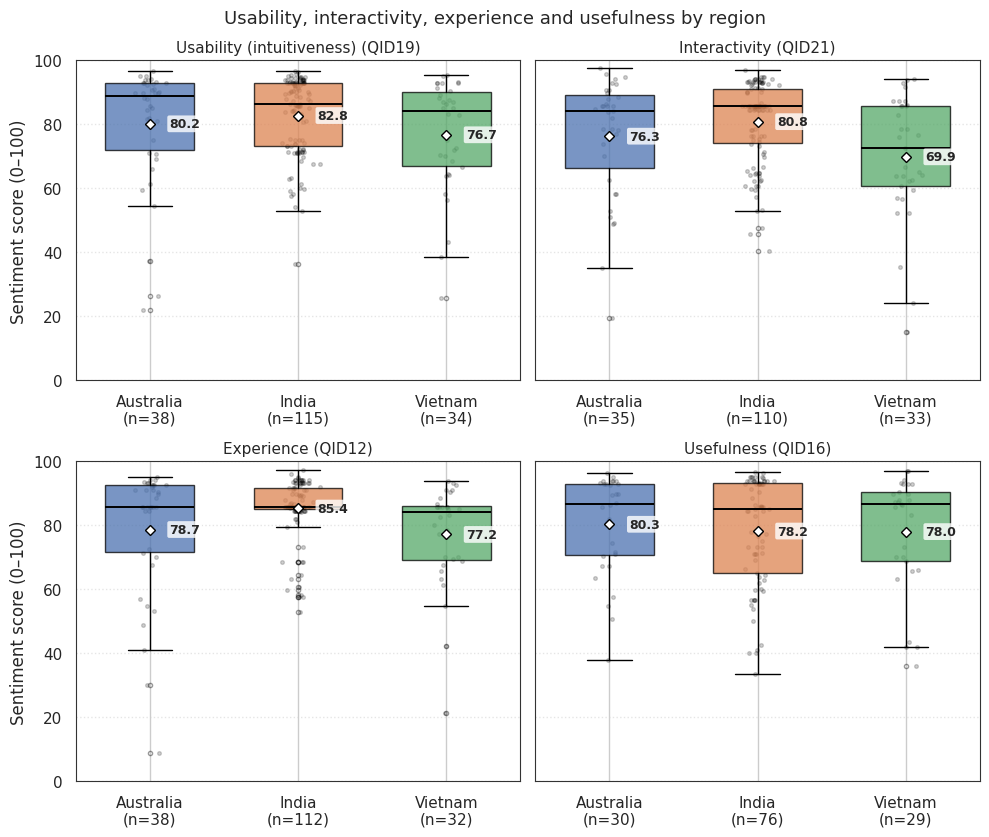

In [60]:
dim_cols = [c for c in DIMENSION_ITEMS.values() if c in all_scores.columns]
dim_names = {c: d for d, c in DIMENSION_ITEMS.items()}
rows = []
for c in dim_cols:
    v = all_scores[c].dropna()
    row = {"Dimension": dim_names[c], "Question": c, "n": len(v),
           "Mean": round(v.mean(), 1), "SD": round(v.std(ddof=1), 1),
           "Median": round(v.median(), 1)}
    for g in GROUPS:
        row[g] = fmtCell(all_scores.loc[df["Occupation"] == g, c])
    rows.append(row)
dimension_desc = pd.DataFrame(rows)
print("Sentiment by dimension — mean ± SD (n) by expertise")
print(dimension_desc.to_string(index=False))
saveTable(dimension_desc, "table_33_dimension_sentiment")

for gvar in ["Region", "Occupation"]:
    res, _ = groupComparison(scores_ctx, dim_cols, gvar, orderFor(gvar))
    if not res.empty:
        print(f"\nDimensions by {labelOf(gvar)}")
        print(res[[c for c in res.columns if not c.endswith("(n)")]].to_string(index=False))
        saveTable(res, f"table_34_dimensions_by_{gvar}")

_saved_labels = {c: question_labels.get(c) for c in dim_cols}
for c in dim_cols:                         # titles show the dimension names
    question_labels[c] = f"{dim_names[c]} ({c})"
regionBoxplots(all_scores, dim_cols, "Usability, interactivity, experience and usefulness by region",
                "fig_21_dimensions_by_region", ncols=2)
for c, lab in _saved_labels.items():       # restore the original labels
    if lab is None:
        question_labels.pop(c, None)
    else:
        question_labels[c] = lab


In [61]:
# Helpers for coding open-ended answers into themes
def compileThemes(themes):
    return {t: re.compile(r"\b(?:" + "|".join(p) + ")", re.IGNORECASE)
            for t, p in themes.items()}


# answers to `col` that say something (non-answers like 'No', '.' removed)
def substantive(col):
    if col not in df.columns:
        return pd.Series(dtype=str)
    t = df[col].dropna().astype(str).map(fixMojibake).str.strip()
    t = t[t.ne("")]
    return t[~t.apply(lambda x: bool(re.fullmatch(r"\W*", x)) or
                      (not any(len(w) >= 3 and w not in GENERIC
                               for w in re.findall(r"[a-z]+", x.lower()))))]


# % of respondents mentioning each theme in any of `cols`, overall and by expertise
def themeTable(cols, themes, title, fname, top_n=12):
    rx = compileThemes(themes)
    texts = pd.concat([substantive(c) for c in cols if c in df.columns], axis=0)
    if texts.empty:
        print(f"No answers found in {cols}.")
        return None
    per_person = texts.groupby(level=0).apply(lambda s: " | ".join(s))
    coded = per_person.apply(lambda t: {k for k, r in rx.items() if r.search(t)})
    grp = df.loc[coded.index, "Occupation"]
    n_all = len(coded)
    rows = []
    for k in themes:
        has = coded.apply(lambda s: k in s)
        row = {"Theme": k, "n": int(has.sum()), "% of respondents": pct(int(has.sum()), n_all)}
        for g in GROUPS:
            m = grp == g
            row[f"{g} %"] = pct(int(has[m].sum()), int(m.sum()))
        rows.append(row)
    tab = (pd.DataFrame(rows).query("n > 0")
           .sort_values("n", ascending=False).reset_index(drop=True))
    print(f"{title} — {n_all} respondents with a substantive answer "
          f"({', '.join(f'{g} {int((grp == g).sum())}' for g in GROUPS)})")
    print(tab.to_string(index=False))
    saveTable(tab, fname.replace("fig_", "table_"))

    top = tab.head(top_n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.38 * len(top) + 1.4))
    ax.barh(top["Theme"], top["% of respondents"], color="#4C72B0", edgecolor="black",
            linewidth=0.5)
    for y, (v, n) in enumerate(zip(top["% of respondents"], top["n"])):
        ax.text(v + 0.8, y, f"{v:.1f}% (n={n})", va="center", fontsize=8)
    ax.set_xlabel("Respondents mentioning the theme (%)")
    ax.set_xlim(0, max(10, top["% of respondents"].max() * 1.25))
    ax.set_title(title, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.grid(True, linestyle=":", alpha=0.5)
    ax.yaxis.grid(False)
    plt.tight_layout()
    saveFig(fname)
    plt.show()
    return tab, coded


### 9.2 Suggested improvements

The improvement questions (`IMPROVE_ITEMS`) are combined per respondent and coded
by keyword for (a) which feature the suggestion is about and (b) the type of
improvement. Each theme is counted once per person. The answers matched to the
device-compatibility and built-in-map themes are printed for checking.


Improvement questions used: ['QID14', 'QID20', 'QID23', 'QID26']
What should be improved (themes) — 173 respondents with a substantive answer (Expert 19, Non-expert 154)
                                Theme  n  % of respondents  Expert %  Non-expert %
                      Maps & location 53              30.6      15.8          32.5
                Ease of use / clarity 33              19.1      21.1          18.8
                   Visual design / UI 28              16.2      10.5          16.9
     More data / indicators / content 28              16.2      15.8          16.2
                        Interactivity 23              13.3      26.3          11.7
               Charts & visualisation 21              12.1      10.5          12.3
              Explanations & guidance 20              11.6      10.5          11.7
Device compatibility (phone / camera) 18              10.4      36.8           7.1
          Immersive (VR / 3D / sound) 13               7.5      10.5           7.1


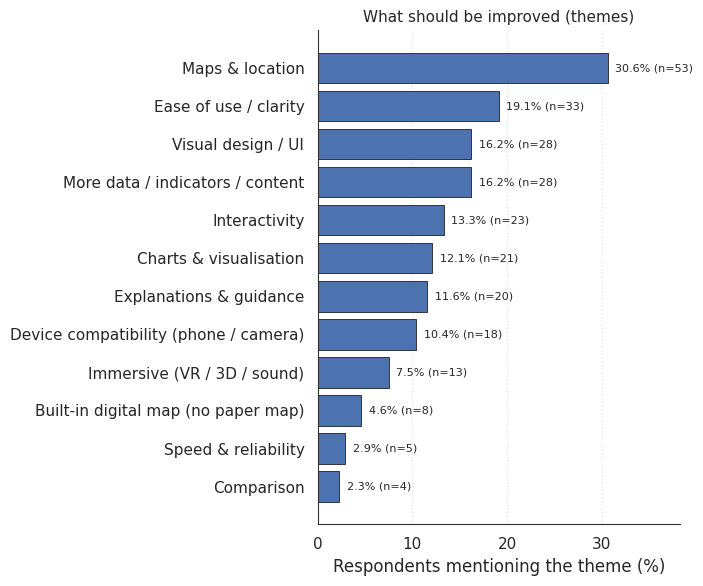

Which feature the improvement is about — 173 respondents with a substantive answer (Expert 19, Non-expert 154)
      Theme  n  % of respondents  Expert %  Non-expert %
Geolocation 39              22.5      10.5          24.0
    Mapping 24              13.9       5.3          14.9
    Tracker 12               6.9       5.3           7.1
  saved -> tables/table_22b_improvement_features.csv


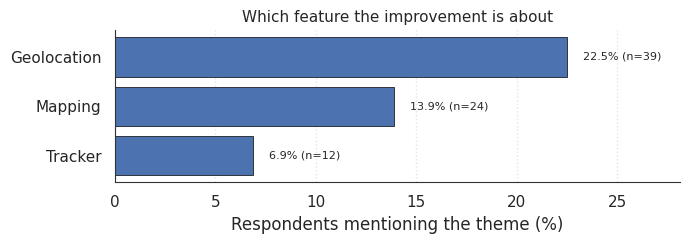


% of respondents mentioning each feature who asked for each improvement
                    n  More data / indicators / content  Explanations & guidance  Ease of use / clarity  Visual design / UI  Interactivity  Charts & visualisation  Comparison  Device compatibility (phone / camera)  Built-in digital map (no paper map)  Immersive (VR / 3D / sound)
Feature mentioned                                                                                                                                                                                                                                                                      
Tracker            12                              41.7                     41.7                   16.7                16.7           16.7                     8.3        16.7                                    0.0                                  8.3                          8.3
Mapping            24                              29.2                     25.0       

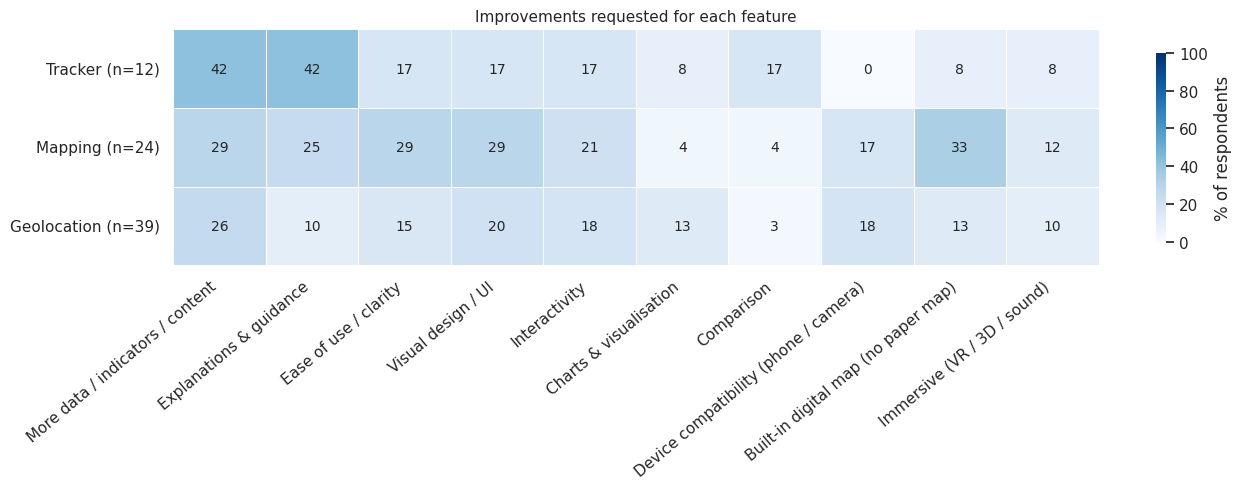


--- Device compatibility (phone / camera) ---
[QID14] ios usage
[QID14] Larger text etc for use on phone
[QID14] I would improve the Geo-Location to work better for all phones.
[QID20] ios usage
[QID20] More sensitive of the app’s camera
[QID20] This app must be improve for IOS user in mobile phone
[QID20] Simple UI is working, little bit of improvement possible for the layout on a mobile device, so cut off at the edges
[QID20] I would love if it be more android-friendly
[QID20] The app in Iphones should be improved, there're some phones that can't use this app and the data must be downloaded to the phone so that it can export to the app. I suggest connecting the app with emails and giving more information of other countries. Overall, this app is useful. 3.8/10 .
[QID20] I have no objection but may be it shoul be well in all android or ios
[QID20] personally, I couldn't use the app on my phone but I saw the ones on my friend's phone and it's quite nice. I cant think of any improvement

In [62]:
FEATURE_MENTIONS = {
    "Tracker":     [r"track"],
    "Mapping":     [r"map(?!le)", r"mapping"],
    "Geolocation": [r"geo", r"location", r"gps\b", r"places?\b", r"countr"],
}
IMPROVE_THEMES = {
    "More data / indicators / content": [r"more data", r"more information", r"indicator",
                                         r"metric", r"parameter", r"content", r"detail"],
    "Explanations & guidance":          [r"expla", r"guid", r"tutorial", r"help\b",
                                         r"instruction", r"descri", r"legend", r"label"],
    "Ease of use / clarity":            [r"easy", r"easier", r"simpl", r"user.friendly",
                                         r"intuitiv", r"confus", r"complicat", r"clear",
                                         r"understand"],
    "Visual design / UI":               [r"design", r"colou?r", r"layout", r"interface",
                                         r"\bui\b", r"font", r"theme", r"attractive", r"look"],
    "Interactivity":                    [r"interact", r"click", r"zoom", r"filter",
                                         r"search", r"drag", r"hover", r"select", r"navigat"],
    "Charts & visualisation":           [r"chart", r"graph", r"visual", r"plot", r"table"],
    "Maps & location":                  [r"map(?!le)", r"location", r"geo", r"countr",
                                         r"region", r"place"],
    "Comparison":                       [r"compar", r"benchmark"],
    "Speed & reliability":              [r"slow", r"fast", r"speed", r"lag", r"load",
                                         r"bug", r"crash", r"error"],
    "Device compatibility (phone / camera)": [r"mobile", r"phones?\b", r"smartphone",
                                              r"android", r"\bios\b", r"iphones?",
                                              r"camera", r"screen", r"compatib"],
    "Built-in digital map (no paper map)":   [r"digital map", r"google ?(?:map|earth)",
                                              r"apple map", r"map in(?:built| the app)",
                                              r"paper", r"printed", r"install a map",
                                              r"add a map", r"map inbuilt"],
    "Immersive (VR / 3D / sound)":      [r"\bvr\b", r"virtual", r"3d\b", r"sound", r"audio",
                                         r"animat"],
}
print("Improvement questions used:", [c for c in IMPROVE_ITEMS if c in df.columns])
out = themeTable(IMPROVE_ITEMS, IMPROVE_THEMES,
                  "What should be improved (themes)", "fig_22a_improvement_themes")
out_f = themeTable(IMPROVE_ITEMS, FEATURE_MENTIONS,
                    "Which feature the improvement is about", "fig_22b_improvement_features")

# Themes x feature: what is asked for, for each feature
if out and out_f:
    _, coded_t = out
    _, coded_f = out_f
    rows = []
    for feat in FEATURE_MENTIONS:
        who = coded_f[coded_f.apply(lambda s: feat in s)].index
        row = {"Feature mentioned": feat, "n": len(who)}
        for t in IMPROVE_THEMES:
            if t == "Maps & location":       # circular: it is how Mapping/Geolocation
                continue                     # mentions are detected
            row[t] = pct(int(coded_t.loc[who].apply(lambda s: t in s).sum()), len(who))
        rows.append(row)
    by_feature = pd.DataFrame(rows).set_index("Feature mentioned")
    keep = [c for c in by_feature.columns if c == "n" or by_feature[c].sum() > 0]
    print("\n% of respondents mentioning each feature who asked for each improvement")
    print(by_feature[keep].to_string())
    saveTable(by_feature[keep].reset_index(), "table_22c_improvement_by_feature")

    plot = by_feature[[c for c in keep if c != "n"]]
    if not plot.empty and plot.values.sum() > 0:
        fig, ax = plt.subplots(figsize=(1.0 * plot.shape[1] + 3.5, 0.6 * plot.shape[0] + 3.2))
        sns.heatmap(plot, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
                    cbar_kws={"label": "% of respondents", "shrink": 0.8},
                    linewidths=0.4, linecolor="white", ax=ax)
        ax.set_yticklabels([f"{f} (n={int(by_feature.loc[f, 'n'])})" for f in plot.index],
                           rotation=0)
        ax.set_xlabel("")
        ax.set_ylabel("")
        plt.xticks(rotation=40, ha="right")
        ax.set_title("Improvements requested for each feature", fontsize=11)
        plt.tight_layout()
        saveFig("fig_22c_improvement_by_feature")
        plt.show()


# Check: the answers counted as device problems or built-in-map requests
for theme in ["Device compatibility (phone / camera)", "Built-in digital map (no paper map)"]:
    rx = compileThemes({theme: IMPROVE_THEMES[theme]})[theme]
    print(f"\n--- {theme} ---")
    for col in IMPROVE_ITEMS:
        for t in substantive(col):
            if rx.search(t):
                print(f"[{col}] {t}")


### 9.3 Understanding of the LCSA indicators

The answers to the understanding and representation questions (`INDICATOR_ITEMS`)
are coded for how respondents want results shown (numeric values, colour,
location, charts, positive/negative impact) and which impact categories they name.
Note that question 12 itself listed "Positive and Negative Impact" and
"Numeric Values" as examples, so some respondents repeated them.


Understanding / representation questions used: ['QID16', 'QID17', 'QID18', 'QID19']
Caveat: QID18 itself lists 'Positive and Negative Impact, parameters, Numeric Values' as examples, so these themes are partly prompted by the question.
How respondents want LCSA data represented — 190 respondents with a substantive answer (Expert 21, Non-expert 169)
                     Theme  n  % of respondents  Expert %  Non-expert %
Positive / negative impact 65              34.2      42.9          33.1
            Numeric values 50              26.3      28.6          26.0
           Charts & graphs 49              25.8       9.5          27.8
            Location / map 43              22.6      14.3          23.7
                    Colour 12               6.3       9.5           5.9
                Comparison 11               5.8      19.0           4.1
                    Tables  1               0.5       0.0           0.6
  saved -> tables/table_23a_indicator_representation.csv


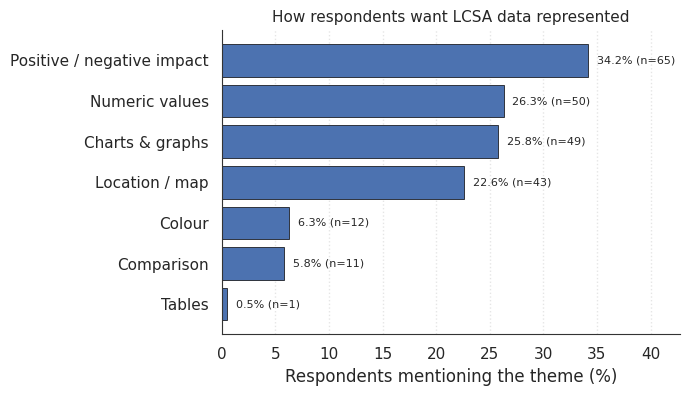

LCSA impact categories mentioned — 190 respondents with a substantive answer (Expert 21, Non-expert 169)
                  Theme  n  % of respondents  Expert %  Non-expert %
 GWP / carbon / climate 14               7.4       9.5           7.1
        Air / pollution 13               6.8       4.8           7.1
        Social / labour  9               4.7       9.5           4.1
Human toxicity / health  6               3.2       0.0           3.6
                  Water  6               3.2       0.0           3.6
      Waste / resources  6               3.2       0.0           3.6
        Cost / economic  5               2.6       0.0           3.0
        Ozone depletion  5               2.6       0.0           3.0
                 Energy  3               1.6       0.0           1.8
  saved -> tables/table_23b_impact_categories.csv


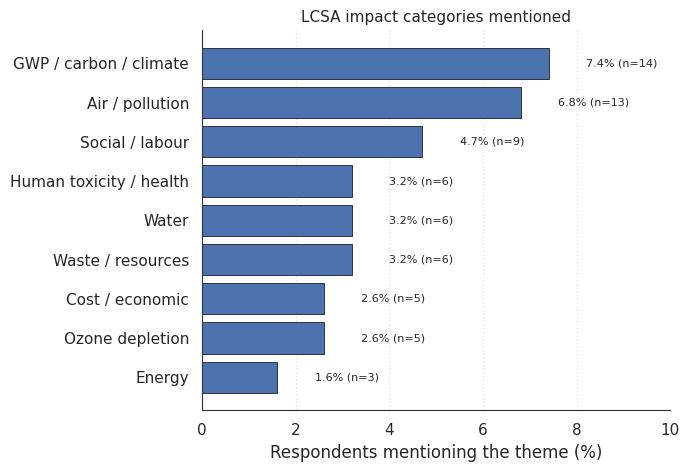

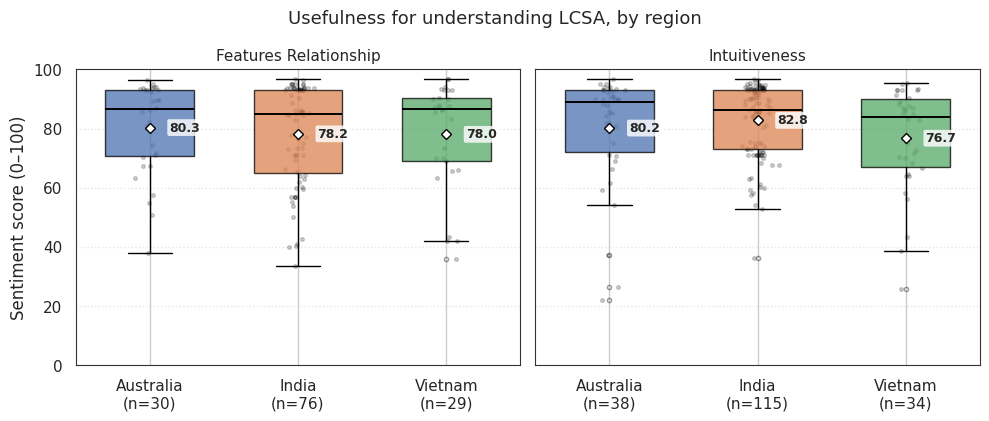

In [63]:
REPRESENTATION = {
    "Numeric values":             [r"number", r"numeric", r"value", r"percent", r"%",
                                   r"figure", r"score", r"quantit"],
    "Colour":                     [r"colou?r", r"red\b", r"green\b", r"heat ?map", r"shade"],
    "Location / map":             [r"map(?!le)", r"location", r"geo", r"countr", r"region",
                                   r"place", r"spatial"],
    "Charts & graphs":            [r"chart", r"graph", r"plot", r"bar\b", r"pie\b", r"visual"],
    "Positive / negative impact": [r"positive", r"negative", r"impact", r"benefit", r"harm"],
    "Comparison":                 [r"compar", r"benchmark", r"versus", r"rank"],
    "Tables":                     [r"table", r"sheet"],
}
IMPACT_CATEGORIES = {
    "GWP / carbon / climate":     [r"gwp", r"global warming", r"carbon", r"co2", r"emission",
                                   r"climate", r"greenhouse", r"ghg"],
    "Cost / economic":            [r"cost", r"price", r"economic", r"money", r"financ",
                                   r"profit"],
    "Human toxicity / health":    [r"toxic", r"health", r"human"],
    "Water":                      [r"water"],
    "Energy":                     [r"energy", r"electric", r"fuel", r"power"],
    "Land / biodiversity":        [r"land\b", r"biodivers", r"ecosystem", r"forest"],
    "Social / labour":            [r"social", r"labou?r", r"worker", r"community", r"job",
                                   r"employ"],
    "Waste / resources":          [r"waste", r"recycl", r"resource", r"material"],
    "Ozone depletion":            [r"ozone"],
    "Air / pollution":            [r"air\b", r"pollut", r"particulate"],
}
print("Understanding / representation questions used:",
      [c for c in INDICATOR_ITEMS if c in df.columns])
print("Caveat: QID18 itself lists 'Positive and Negative Impact, parameters, Numeric "
      "Values' as examples, so these themes are partly prompted by the question.")
themeTable(INDICATOR_ITEMS, REPRESENTATION,
            "How respondents want LCSA data represented", "fig_23a_indicator_representation")
themeTable(INDICATOR_ITEMS, IMPACT_CATEGORIES,
            "LCSA impact categories mentioned", "fig_23b_impact_categories")

# The two quantitative understanding questions, side by side
und = [c for c in ["QID16", "QID19"] if c in all_scores.columns]
if und:
    regionBoxplots(all_scores, und, "Usefulness for understanding LCSA, by region",
                    "fig_23c_understanding_by_region", ncols=2)


### 9.4 The eight metrics — box plots and density plots

Box plots (by region and by expertise) and density plots (by country) for the
eight metrics reported in the paper. Labels in the data are mapped to the names
used in the paper: Interactiveness → Interactivity, Prototype Novelty →
Visualisation usefulness, and Sustainability / Environmental / Economic / Social
Importance → LCSA / LCA / LCC / S-LCA indicators suitability. Dashed lines in the
density plots mark each country's median.


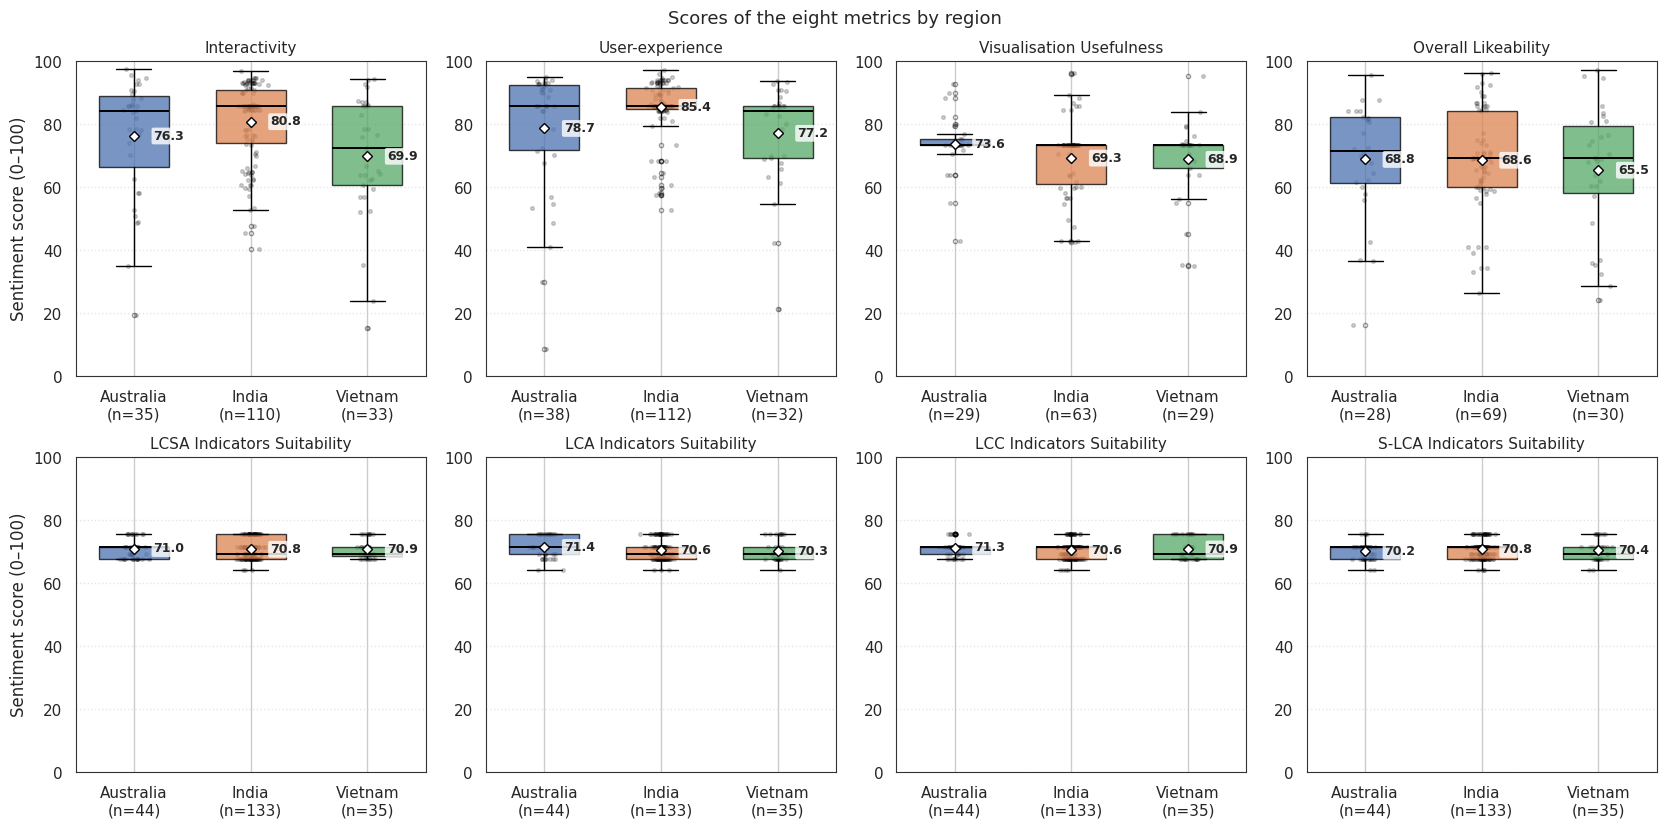

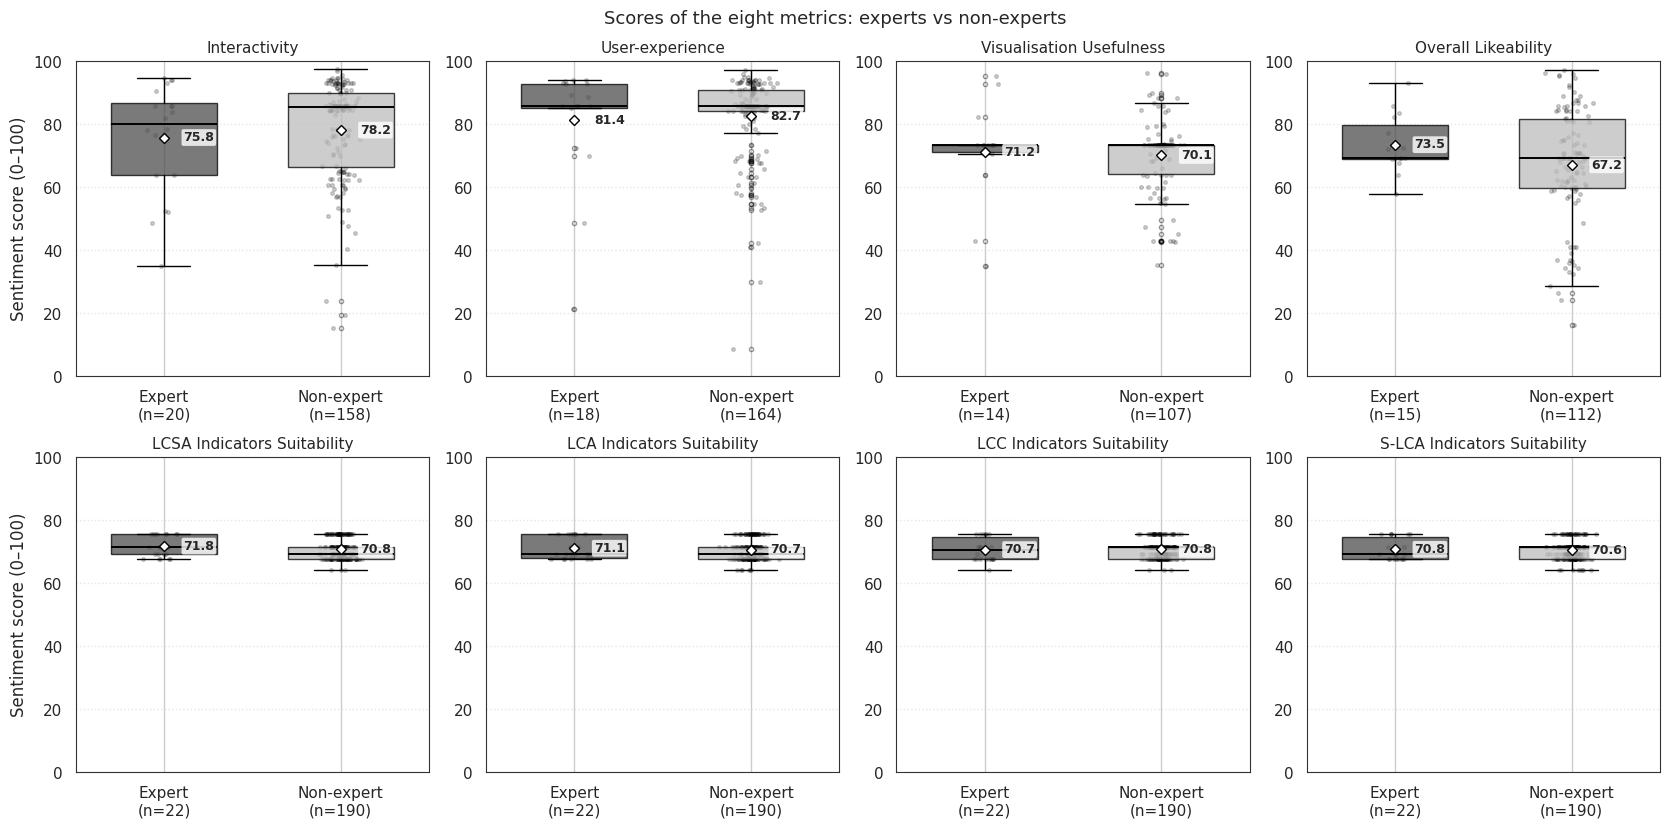

In [64]:
# Box plots of the eight metrics, using the names in the paper
CONFIG["fig_formats"] = ("svg", "png")
CONFIG["fig_dpi"] = 1000
plt.rcParams["svg.fonttype"] = "none"

# label in the data  ->  name used in the paper
METRICS = {
    "Interactiveness":           "Interactivity",
    "User-Experience":           "User-experience",
    "Prototype Novelty":         "Visualisation Usefulness",
    "Overall Likeability":       "Overall Likeability",
    "Sustainability Importance": "LCSA Indicators Suitability",
    "Environmental Importance":  "LCA Indicators Suitability",
    "Economic Importance":       "LCC Indicators Suitability",
    "Social Importance":         "S-LCA Indicators Suitability",
}

label_to_col = {labelOf(c).strip().lower(): c for c in df_scores.columns}
metric_cols, metric_names = [], []
for orig, new in METRICS.items():
    col = label_to_col.get(orig.lower())
    if col is None:
        print(f"Not found: {orig!r}")
    else:
        metric_cols.append(col)
        metric_names.append(new)


def metricBoxplots(gvar, levels, colours, title, fname, ncols=4):
    nrows = int(np.ceil(len(metric_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows),
                             squeeze=False)
    jit = np.random.default_rng(CONFIG["random_seed"])
    for ax, col, name in zip(axes.ravel(), metric_cols, metric_names):
        groups = [df_scores.loc[df[gvar] == g, col].dropna().values for g in levels]
        bp = ax.boxplot(groups, patch_artist=True, showmeans=True, widths=0.6,
                        tick_labels=[f"{g}\n(n={len(d)})" for g, d in zip(levels, groups)],
                        medianprops=dict(color="black", linewidth=1.4),
                        meanprops=dict(marker="D", markerfacecolor="white",
                                       markeredgecolor="black", markersize=5),
                        flierprops=dict(marker="o", markersize=3, alpha=0.4))
        for patch, g in zip(bp["boxes"], levels):
            patch.set_facecolor(colours.get(g, "#999999"))
            patch.set_alpha(0.75)
        for i, d in enumerate(groups, start=1):
            ax.scatter(jit.normal(i, 0.05, len(d)), d, s=7, color="black", alpha=0.18)
            if len(d):
                ax.annotate(f"{np.mean(d):.1f}", xy=(i, np.mean(d)), xytext=(14, 0),
                            textcoords="offset points", va="center", fontsize=9,
                            fontweight="bold",
                            bbox=dict(boxstyle="round,pad=0.15", fc="white",
                                      ec="none", alpha=0.8))
        ax.set_title(name, fontsize=11)
        ax.set_ylim(0, 100)
        ax.yaxis.grid(True, linestyle=":", alpha=0.5)
        ax.set_axisbelow(True)
    for ax in axes.ravel()[len(metric_cols):]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel("Sentiment score (0–100)")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    saveFig(fname)
    plt.show()


# Figure 1: by region (Table 3)
metricBoxplots("Region", regions_present, region_colors,
                "Scores of the eight metrics by region",
                "fig_40a_eight_metrics_by_region")

# Figure 2: experts vs non-experts (Table 4)
EXPERT_VAR = "Occupation"
EXPERT_GROUPS = [g for g in orderedCategories(df[EXPERT_VAR], orderFor(EXPERT_VAR))
                 if g not in NON_RESPONSE_LEVELS]
metricBoxplots(EXPERT_VAR, EXPERT_GROUPS,
                {EXPERT_GROUPS[0]: "#4D4D4D", EXPERT_GROUPS[1]: "#BDBDBD"},
                "Scores of the eight metrics: experts vs non-experts",
                "fig_40b_eight_metrics_by_expertise")


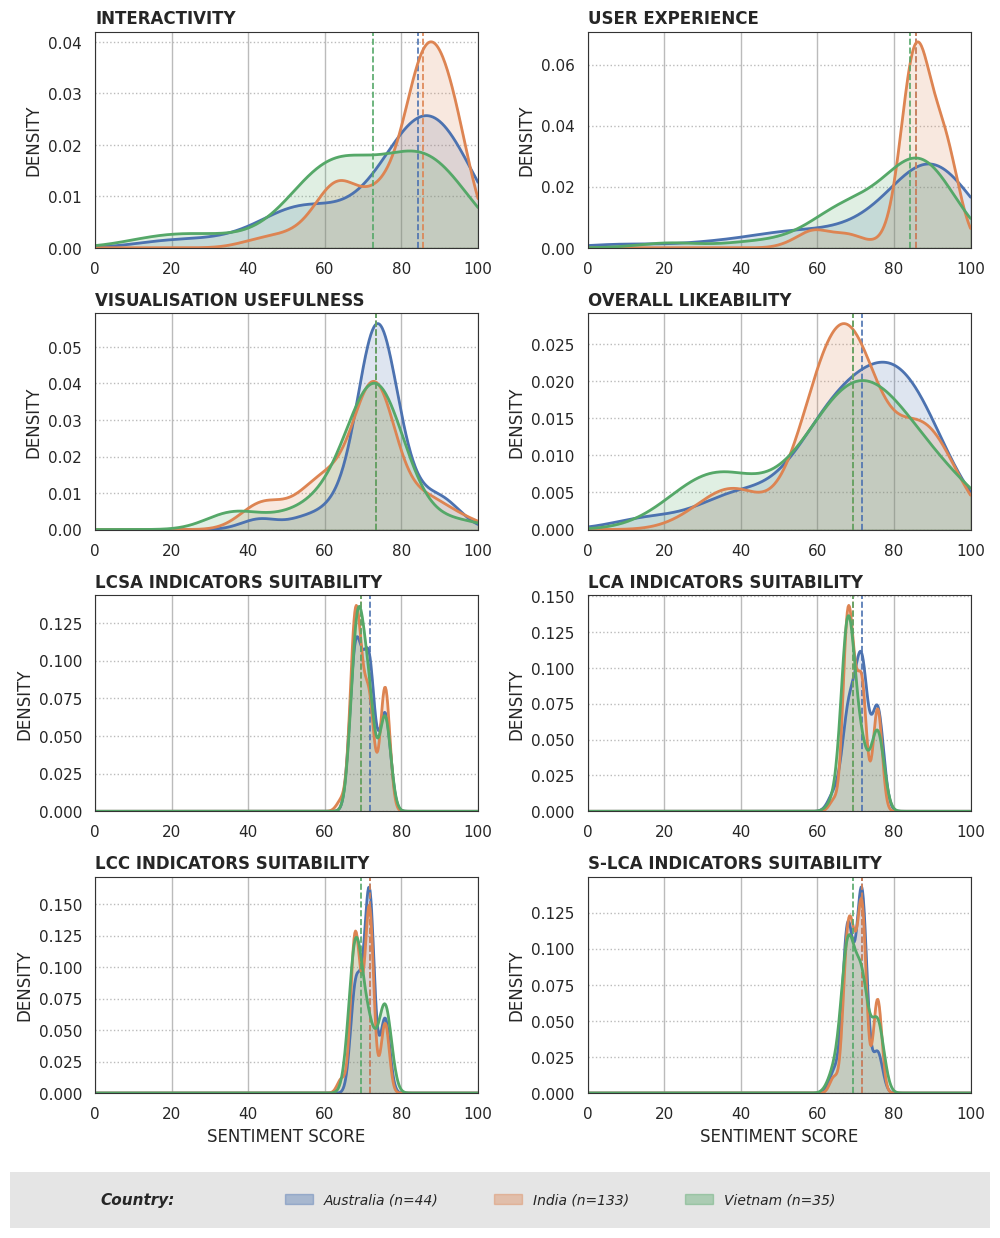

Dashed lines = median of each country. n = respondents per country; each panel uses only those who answered that question.


In [65]:
# Density plots (KDE) of the eight metrics by country
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch, Rectangle

CONFIG["fig_formats"] = ("svg", "png")
CONFIG["fig_dpi"] = 1000
plt.rcParams["svg.fonttype"] = "none"

# label in the data -> name used in the paper
KDE_METRICS = {
    "Interactiveness":           "Interactivity",
    "User-Experience":           "User experience",
    "Prototype Novelty":         "Visualisation usefulness",
    "Overall Likeability":       "Overall likeability",
    "Sustainability Importance": "LCSA indicators suitability",
    "Environmental Importance":  "LCA indicators suitability",
    "Economic Importance":       "LCC indicators suitability",
    "Social Importance":         "S-LCA indicators suitability",
}
COUNTRY_COLOURS = {"Australia": "#4C72B0", "India": "#DD8452", "Vietnam": "#55A868"}

label_to_col = {labelOf(c).strip().lower(): c for c in df_scores.columns}
kde_cols, kde_names = [], []
for orig, new in KDE_METRICS.items():
    col = label_to_col.get(orig.lower())
    if col is None:
        print(f"Not found: {orig!r}")
    else:
        kde_cols.append(col)
        kde_names.append(new)

countries = [r for r in regions_present if r in COUNTRY_COLOURS]
x = np.linspace(0, 100, 501)

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10}):
    ncols = 2
    nrows = int(np.ceil(len(kde_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 3.1 * nrows), squeeze=False)
    for k, (ax, col, name) in enumerate(zip(axes.ravel(), kde_cols, kde_names)):
        for r in countries:
            v = df_scores.loc[df["Region"] == r, col].dropna().values
            if len(v) < 3 or np.std(v) == 0:
                continue
            y = gaussian_kde(v)(x)
            c = COUNTRY_COLOURS[r]
            ax.plot(x, y, color=c, linewidth=2)
            ax.fill_between(x, y, color=c, alpha=0.18)
            ax.axvline(np.median(v), color=c, linestyle="--", linewidth=1.2)
        ax.set_title(name.upper(), loc="left", fontweight="bold", fontsize=12)
        ax.set_xlim(0, 100)
        ax.set_ylim(bottom=0)
        ax.set_ylabel("DENSITY")
        ax.set_xlabel("SENTIMENT SCORE" if k >= len(kde_cols) - ncols else "")
        ax.xaxis.grid(True, color="#BBBBBB", linewidth=1)
        ax.yaxis.grid(True, linestyle=":", color="#BBBBBB")
        ax.set_axisbelow(True)
    for ax in axes.ravel()[len(kde_cols):]:
        ax.axis("off")

    n_country = {r: int((df["Region"] == r).sum()) for r in countries}
    handles = [Patch(facecolor=COUNTRY_COLOURS[r], edgecolor=COUNTRY_COLOURS[r],
                     alpha=0.4, label=f"{r} (n={n_country[r]})") for r in countries]
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    fig.patches.append(Rectangle((0.01, 0.005), 0.98, 0.045, transform=fig.transFigure,
                                 facecolor="#E5E5E5", edgecolor="none", zorder=0))
    fig.text(0.1, 0.0275, "Country:", fontsize=11, fontweight="bold",
             fontstyle="italic", va="center")
    fig.legend(handles=handles, loc="center", ncol=len(handles), frameon=False,
               prop={"style": "italic", "size": 10}, columnspacing=4,
               bbox_to_anchor=(0.56, 0.0275))
    saveFig("fig_41_eight_metrics_density_by_country")
    plt.show()

print("Dashed lines = median of each country. n = respondents per country; "
      "each panel uses only those who answered that question.")


## Part 8 — Session information

Software versions used for this run. Results from `IterativeImputer` and
`FactorAnalyzer` can change between library versions.


In [66]:
import importlib.metadata as md

session = [("Python", sys.version.split()[0]),
           ("Platform", platform.platform())]
for pkg in ["pandas", "numpy", "scipy", "scikit-learn", "statsmodels",
            "matplotlib", "seaborn", "factor_analyzer", "scikit-posthocs",
            "transformers", "torch", "plotly", "spacy", "wordcloud"]:
    try:
        session.append((pkg, md.version(pkg)))
    except md.PackageNotFoundError:
        session.append((pkg, "not installed"))

session_info = pd.DataFrame(session, columns=["Component", "Version"])
print(session_info.to_string(index=False))

meta = {
    "config": {k: (str(v) if isinstance(v, Path) else v)
               for k, v in CONFIG.items()},
    "n_raw": int(len(df_raw)),
    "n_analysis": int(len(df_mice_full)),
    "rank_cols": rank_cols,
    "constructs": constructs,
    "versions": dict(session),
}
out = Path(CONFIG["table_dir"]) / "session_info.json"
out.write_text(json.dumps(meta, indent=2, default=str), encoding="utf-8")
print(f"\nSaved run metadata -> {out}")
saveTable(session_info, "table_28_session_info")

print("\n" + "=" * 62)
print("Run complete.")
print(f"  Figures -> {CONFIG['fig_dir']}/")
print(f"  Tables  -> {CONFIG['table_dir']}/")
print(f"  Cache   -> {CONFIG['cache_dir']}/")
print("=" * 62)

      Component                              Version
         Python                              3.13.18
       Platform Linux-6.6.159+-x86_64-with-glibc2.39
         pandas                                2.2.3
          numpy                                2.4.6
          scipy                               1.16.3
   scikit-learn                                1.6.1
    statsmodels                               0.15.0
     matplotlib                               3.10.0
        seaborn                               0.13.2
factor_analyzer                        not installed
scikit-posthocs                        not installed
   transformers                               5.22.0
          torch                           2.11.0+cpu
         plotly                               5.24.1
          spacy                               3.8.18
      wordcloud                                1.9.6

Saved run metadata -> tables/session_info.json
  saved -> tables/table_28_session_info.csv

Run co

In [70]:
# import os, shutil

# SAVE_DIR = "/content/drive/MyDrive/LCSA_analysis"
# os.makedirs(SAVE_DIR, exist_ok=True)

# # copy the output folders that already exist into Drive
# for folder in ["figures", "tables", "cache"]:
#     for base in ["/content", "/content/drive/MyDrive"]:
#         src = os.path.join(base, folder)
#         if os.path.isdir(src) and os.path.abspath(src) != os.path.join(SAVE_DIR, folder):
#             shutil.copytree(src, os.path.join(SAVE_DIR, folder), dirs_exist_ok=True)
#             print(f"copied {src} -> {SAVE_DIR}/{folder}")

# %cd {SAVE_DIR}
# !ls

copied /content/figures -> /content/drive/MyDrive/LCSA_analysis/figures
copied /content/tables -> /content/drive/MyDrive/LCSA_analysis/tables
copied /content/cache -> /content/drive/MyDrive/LCSA_analysis/cache
/content/drive/MyDrive/LCSA_analysis
cache  figures	tables
